# Benchmark: sensitivity, stability and sortability

Numerical results are read from `results/analysis/`. Figures are drawn inline; this notebook does not refit models or rerun graph metrics or statistical comparisons.


## Noise, mechanisms and confounding

Compares linear/mixed mechanisms, noise distributions and observed/latent confounding. Complete-fit coverage is required for paired condition comparisons.


In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'runs/run_model.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from inside the repository.')
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.cache/matplotlib'))
sys.path[:0] = [str(ROOT / 'analysis'), str(ROOT / 'runs')]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
sources = th.load_final_results()
benchmark_data = sources['benchmark_data']


### Mechanisms and noise


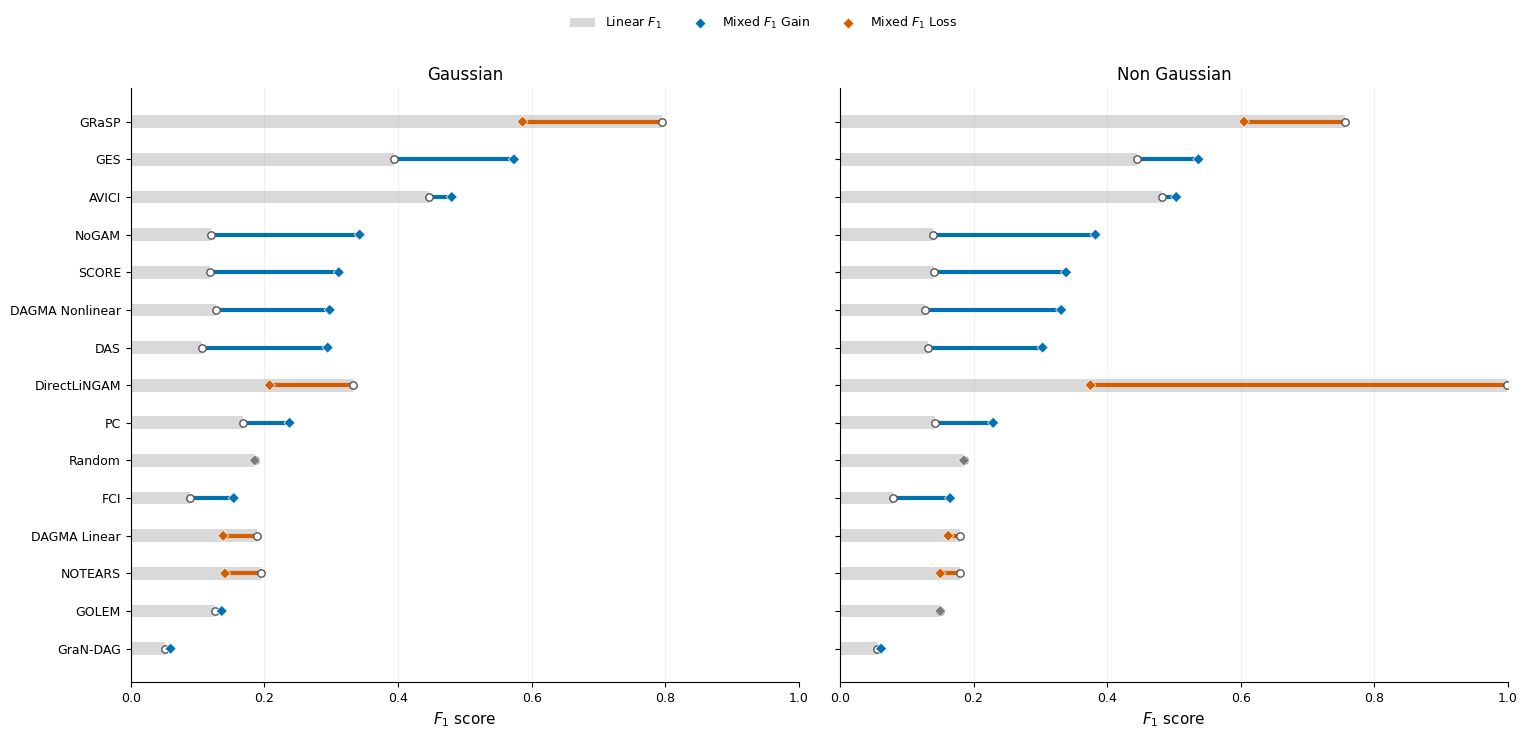

In [2]:
_, _, mechanism_tables = fv.plot_mechanism_heatmap(benchmark_data, metric='f1', mechanisms=('Linear', 'Mixed'), noises={'Gaussian': ('Gaussian',), 'Non Gaussian': ('NonGaussian', 'Non_Gaussian')}, n_nodes=20, graph_type='ER', obs_conf=0, lat_conf=0, coverage_policy='complete', show_metric_title=False)
plt.close(plt.gcf())
fig_mechanism, _, mechanism_change = fv.plot_mechanism_change_bars(mechanism_tables, baseline='Linear', comparison='Mixed', order_by='comparison', xlim=(0, 1), annotate_delta=False, xlabel='$F_1$ score', show_title=False, figsize=(15.5, 7.5), font_size=11, title_size=12)
display(fig_mechanism)
plt.close(fig_mechanism)
_, _, high_noise_table = fv.plot_noise_heatmap(benchmark_data, metric='f1', noises={'Gaussian': ('Gaussian',), 'High Gaussian': ('HighGaussian',)}, mechanisms=('Mixed',), n_nodes=20, graph_type='ER', obs_conf=0, lat_conf=0, coverage_policy='complete', show_metric_title=False)


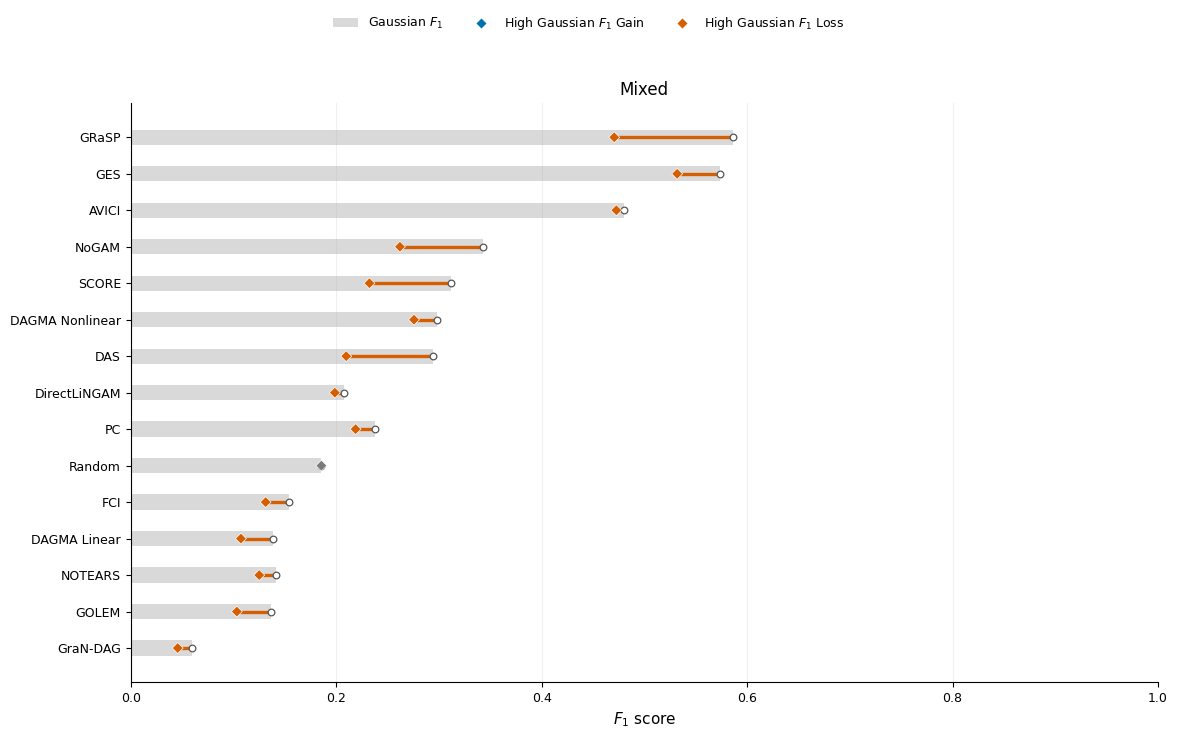

In [3]:
plt.close(plt.gcf())
shared_noise_model_order = mechanism_change['model_order']['model'].tolist()
fig_high, _, high_change = fv.plot_noise_change_by_mechanism({'Mixed': high_noise_table}, baseline='Gaussian', comparisons=('High Gaussian',), model_order=shared_noise_model_order, xlim=(0, 1), xlabel='$F_1$ score', show_title=False, figsize=(12.0, 7.5), font_size=11, title_size=12)
display(fig_high)
plt.close(fig_high)
noise_by_mechanism = {}
for mechanism in ('Linear', 'Mixed'):
    _, _, output = fv.plot_noise_heatmap(benchmark_data, metric='f1', noises={'Gaussian': ('Gaussian',), 'Non Gaussian': ('NonGaussian', 'Non_Gaussian')}, mechanisms=(mechanism,), n_nodes=20, graph_type='ER', obs_conf=0, lat_conf=0, coverage_policy='complete', show_metric_title=False)
    plt.close(plt.gcf())
    noise_by_mechanism[mechanism] = output
fig_non_gaussian, _, non_gaussian_change = fv.plot_noise_change_by_mechanism(noise_by_mechanism, baseline='Gaussian', comparisons=('Non Gaussian',), model_order=shared_noise_model_order, xlim=(0, 1), xlabel='$F_1$ score', show_title=False, figsize=(12.0, 7.5), font_size=11, title_size=12)


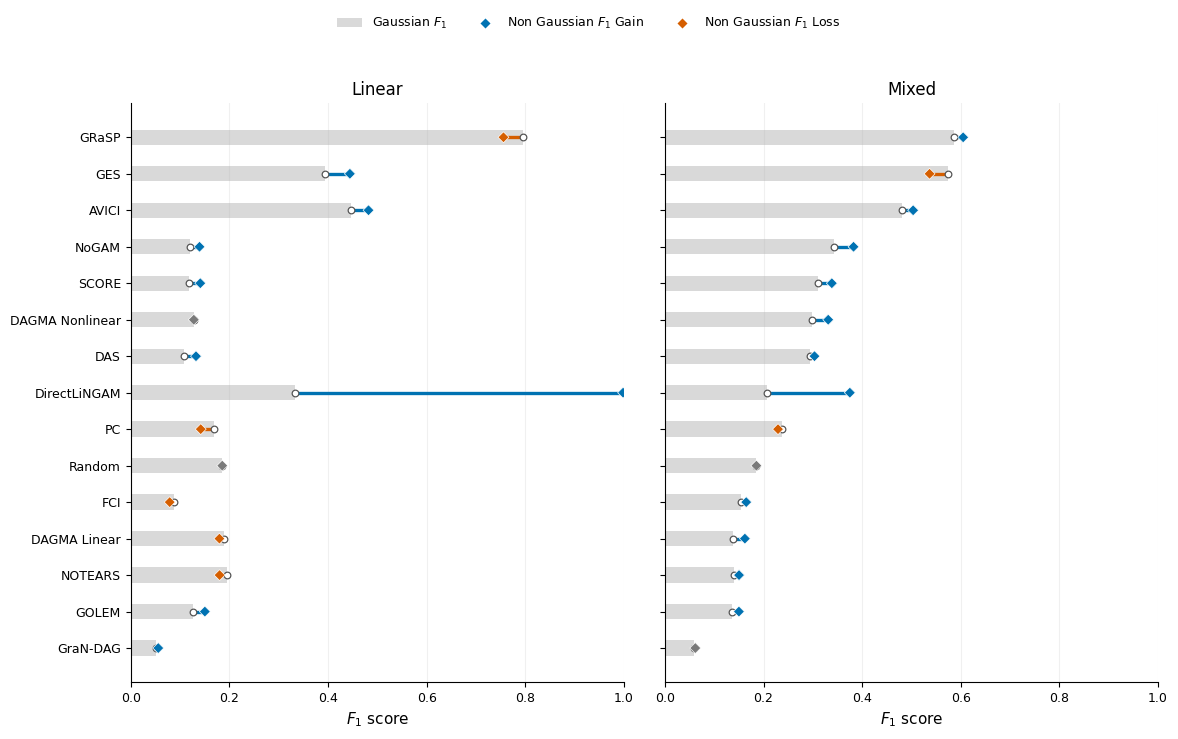

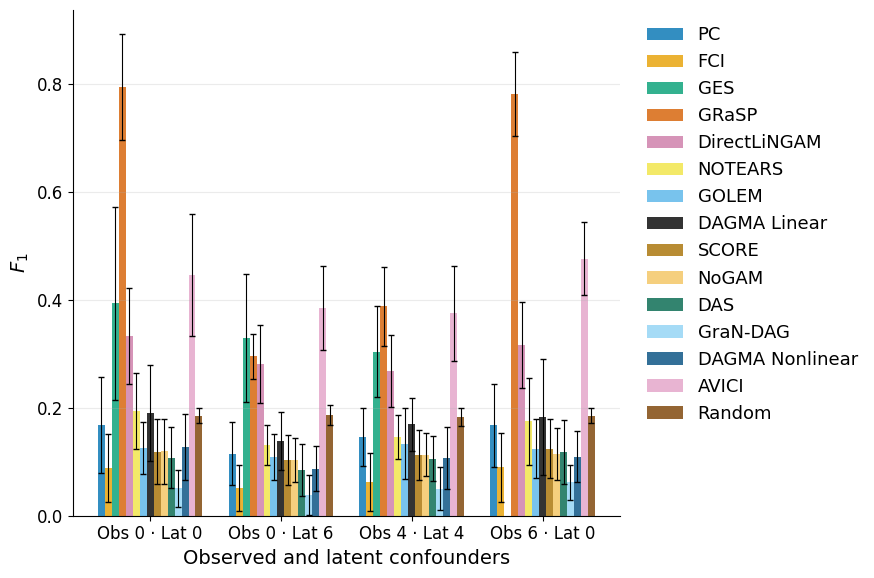

In [4]:
display(fig_non_gaussian)
plt.close(fig_non_gaussian)
fig_conf, _, confounding_output = fv.plot_confounding_f1(benchmark_data, metric='f1', uncertainty='sd', n_nodes=20, obs_conf=None, lat_conf=None, coverage_policy='complete', bar_alpha=0.8, show_metric_title=False)
display(fig_conf)
plt.close(fig_conf)


## Seed variability and model assumptions

Presents the saved summaries of variability across dataset and model seeds. Sortability and the sorting baseline use the same 2,000-observation instances as the model comparisons.


In [5]:
sources = th.load_final_results()
benchmark_data = sources['benchmark_data']


### Stability and assumption effects


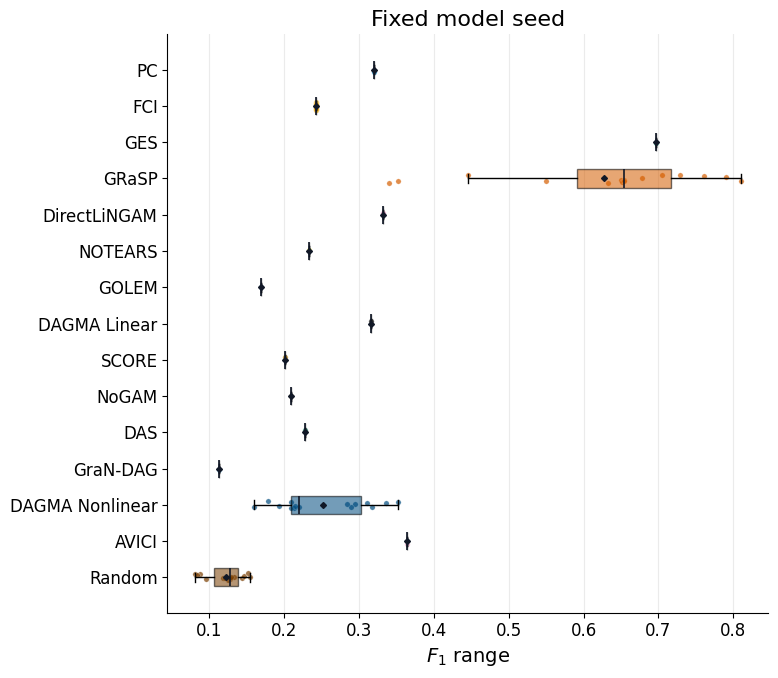

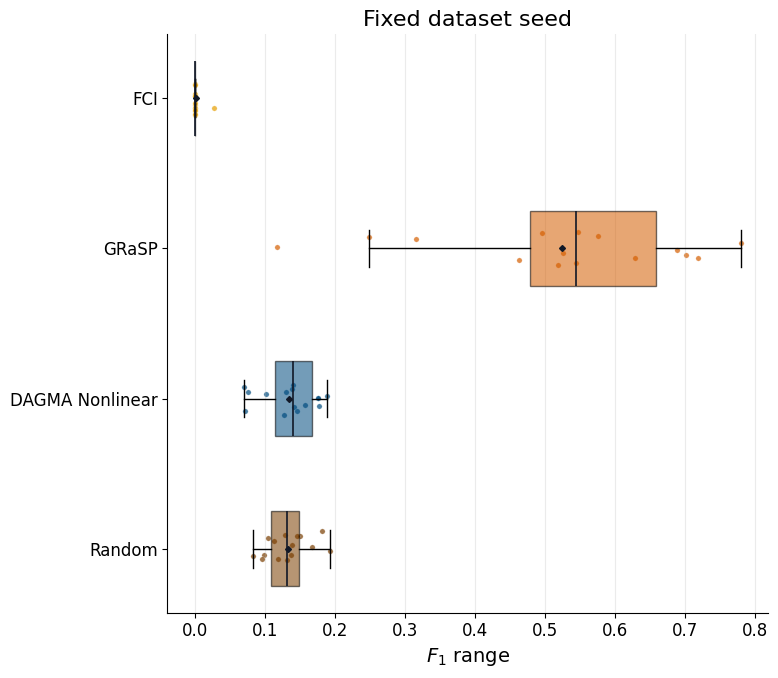

In [6]:
fig_dataset, _, dataset_stability = fv.plot_dataset_seed_stability(benchmark_data, metric='f1', variability='range', n_nodes=20, graph_type='ER', noise='Gaussian', mechanism='Linear', obs_conf=0, lat_conf=0, min_coverage_fraction=0.8, title='Fixed model seed', ylabel='$F_1$ range', figsize=(8, 7), font_size=14, title_size=16, plot_kind='box', model_axis='y')
display(fig_dataset)
plt.close(fig_dataset)
fig_model, _, model_stability = fv.plot_model_seed_stability(benchmark_data, metric='f1', variability='range', n_nodes=20, graph_type='ER', noise='Gaussian', mechanism='Linear', obs_conf=0, lat_conf=0, min_coverage_fraction=0.8, title='Fixed dataset seed', ylabel='$F_1$ range', figsize=(8, 7), font_size=14, title_size=16, plot_kind='box', model_axis='y')
display(fig_model)


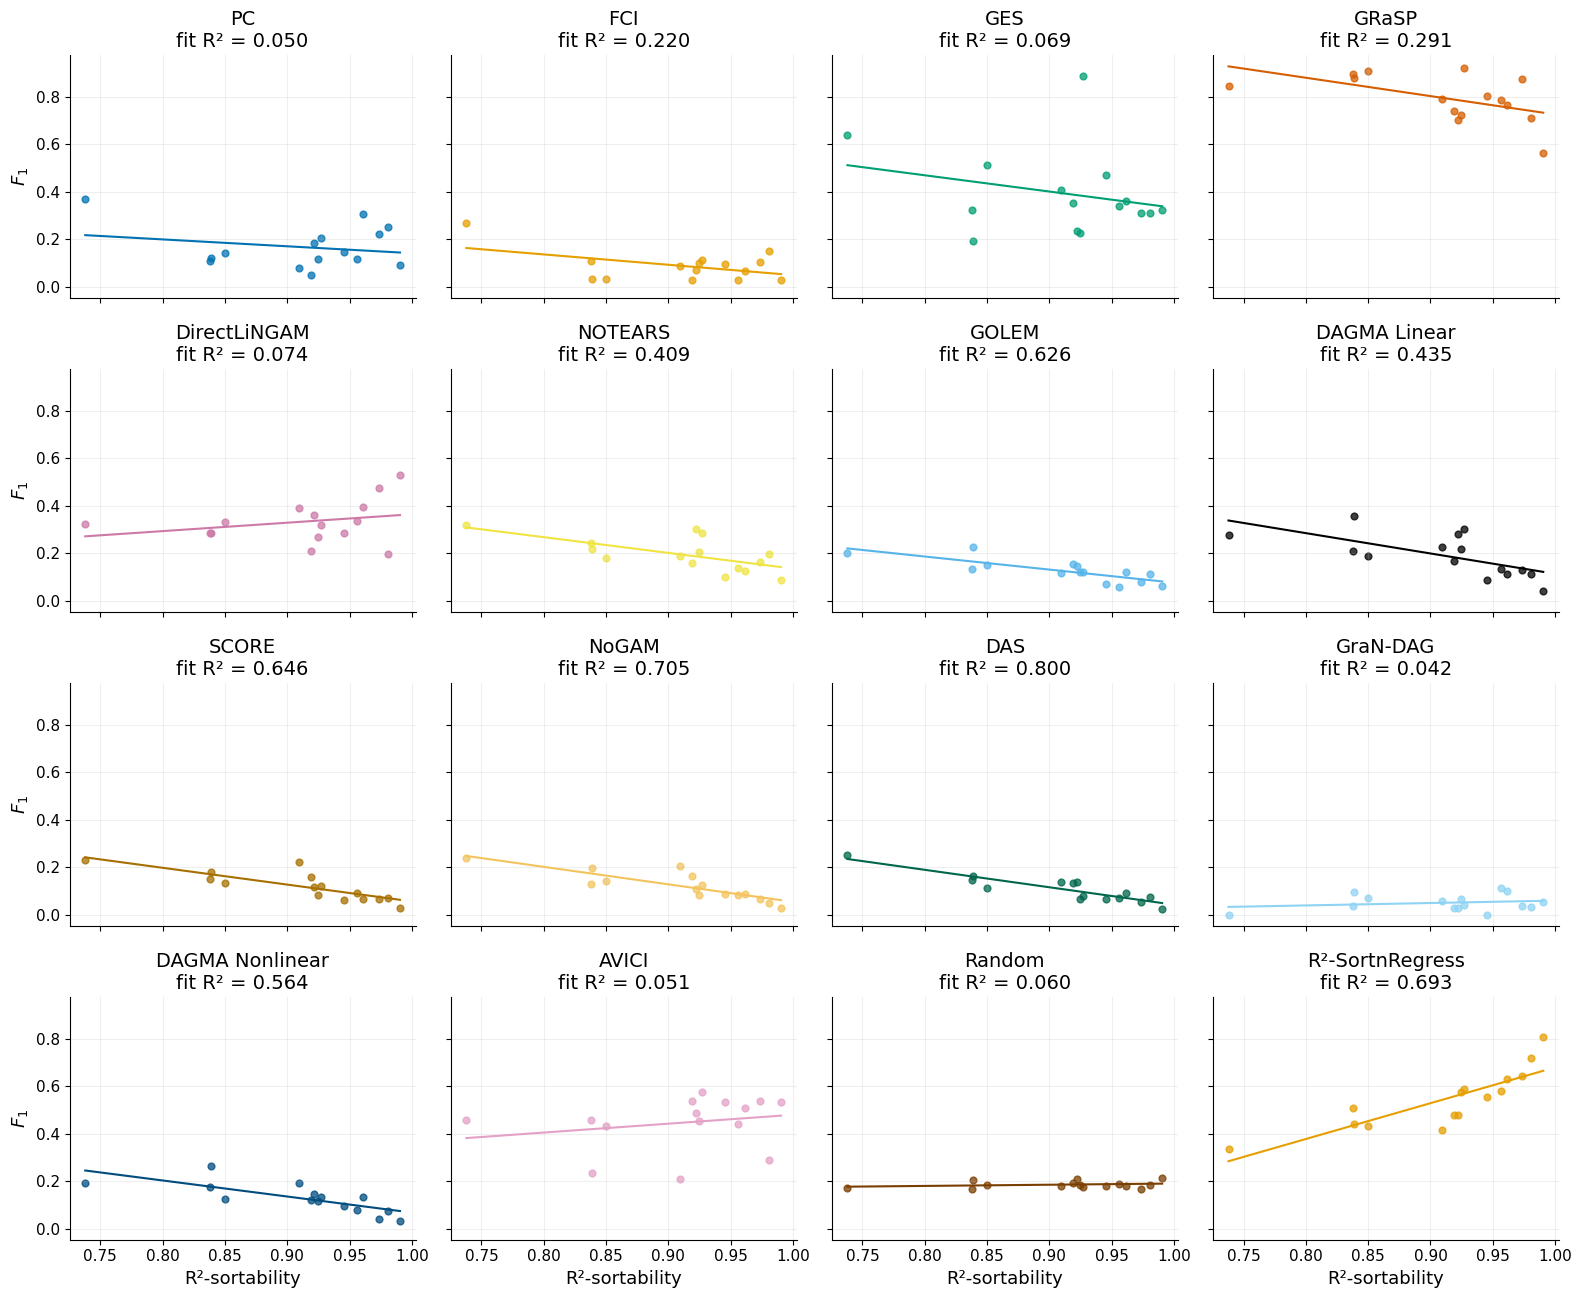

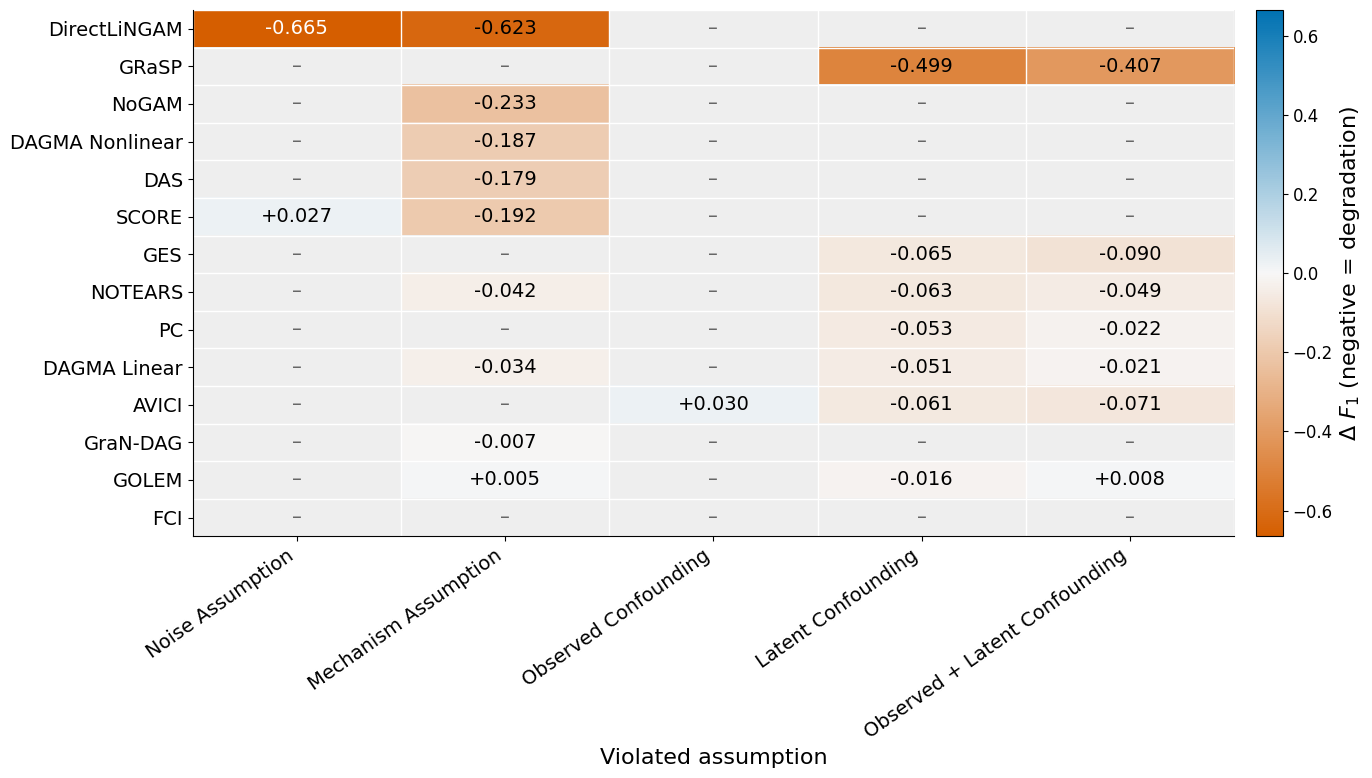

In [7]:
plt.close(fig_model)
fig_var, _, varsortability_output = fv.plot_varsortability_vs_f1(benchmark_data,
    prepared_data=pd.read_pickle(ROOT / "results/analysis/plot_data.pkl")["scatter"]["main"], metric='f1', sortability='r2_sortability', include_r2_sort_regress=True, varsortability_values=pd.read_pickle(ROOT / "results/analysis/sortability.pkl")["gaussian"], r2_sort_regress_values=pd.read_pickle(ROOT / "results/analysis/sortability.pkl")["r2_baseline"], datasets=th.OOD_FAMILIES[0], coverage_policy='complete', columns=4, font_size=13, title_size=14, show_metric_title=False, show_model_titles=True, project_root=ROOT)
display(fig_var)
plt.close(fig_var)
fig_assumption, _, assumption_output = fv.plot_assumption_degradation_heatmap(benchmark_data,
    prepared_data=pd.read_pickle(ROOT / "results/analysis/plot_data.pkl")["assumptions"], metric='f1', assumptions=fv.DEFAULT_ASSUMPTIONS, uncertainty='sd', show_metric_title=False, show_comparisons=False, figsize=(14, 8), font_size=16)
display(fig_assumption)
plt.close(fig_assumption)


### Stability under non-Gaussian mixed mechanisms


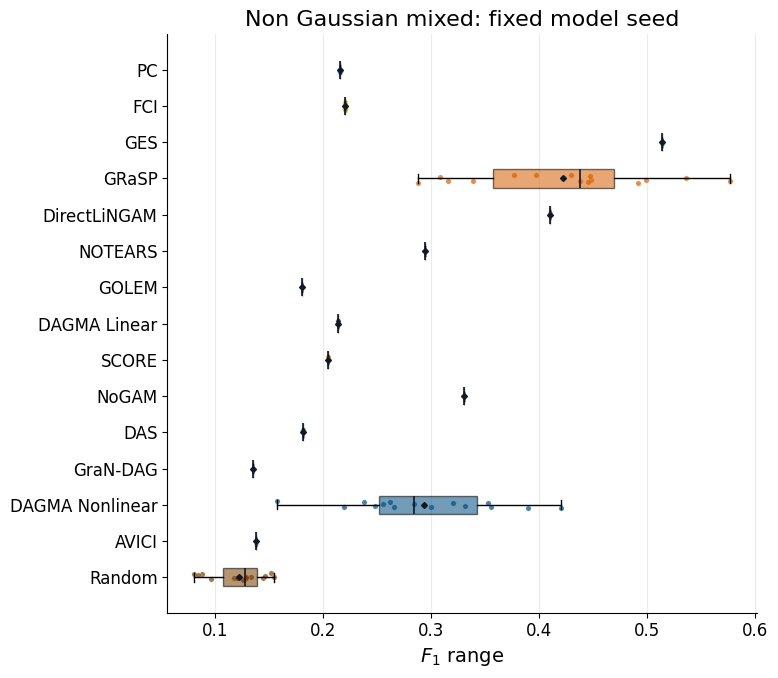

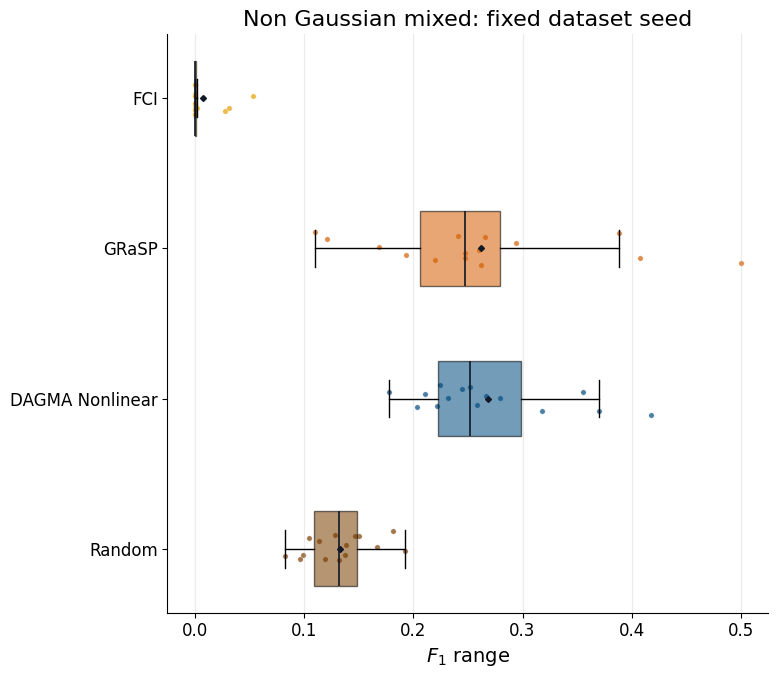

In [8]:
fig_dataset, _, dataset_stability = fv.plot_dataset_seed_stability(benchmark_data, metric='f1', variability='range', n_nodes=20, graph_type='ER', noise='Non_Gaussian', mechanism='Mixed', obs_conf=0, lat_conf=0, min_coverage_fraction=0.8, title='Non Gaussian mixed: fixed model seed', ylabel='$F_1$ range', figsize=(8, 7), font_size=14, title_size=16, plot_kind='box', model_axis='y')
display(fig_dataset)
plt.close(fig_dataset)
fig_model, _, model_stability = fv.plot_model_seed_stability(benchmark_data, metric='f1', variability='range', n_nodes=20, graph_type='ER', noise='Non_Gaussian', mechanism='Mixed', obs_conf=0, lat_conf=0, min_coverage_fraction=0.8, title='Non Gaussian mixed: fixed dataset seed', ylabel='$F_1$ range', figsize=(8, 7), font_size=14, title_size=16, plot_kind='box', model_axis='y')
display(fig_model)
plt.close(fig_model)


## Seed variability across all conditions

Results for all 36 benchmark conditions at 10, 15, 20 and 30 variables. Metrics are summarised within dataset instances before averaging across instances.


In [9]:
import sys, json, textwrap
sys.path.insert(0, str(ROOT / 'analysis'))
frame = pd.concat([th.prepare_metrics(th.load_graph_size_results()), th.load_final_results()['benchmark_with_biological']], ignore_index=True)


In [10]:
def plot_conditions(table, metric, title, filename, bounded=False):
    models = sorted(table.model.unique(), key=th.model_label)
    sizes = sorted(table.n_nodes.unique())
    fig, axes = plt.subplots(2, 2, figsize=(19, 14), constrained_layout=True)
    maximum = 1.0 if bounded else float(table[metric].max())
    cmap = plt.colormaps['viridis'].copy()
    cmap.set_bad('#e8e8e8')
    for ax, size in zip(axes.flat, sizes):
        selected = table.loc[table.n_nodes.eq(size)]
        matrix = selected.pivot(index='dataset', columns='model', values=metric).reindex(columns=models)
        image = ax.imshow(np.ma.masked_invalid(matrix.to_numpy(float)), aspect='auto', cmap=cmap, vmin=0, vmax=maximum)
        labels = [textwrap.fill(name.split('nodes_', 1)[1].replace('_obsconf0_latconf0', '').replace('_', ' '), 33) for name in matrix.index]
        ax.set_yticks(range(len(matrix)), labels, fontsize=8)
        ax.set_xticks(range(len(models)), [th.model_label(m) for m in models], rotation=55, ha='right', fontsize=8)
        ax.set_title(f'{int(size)} variables')
    fig.colorbar(image, ax=axes.ravel().tolist(), label=title, shrink=0.7)
    display(fig)
    plt.close(fig)


,dataset,n_nodes,model,mean,std,size
0,10nodes_ER_obsconf0_latconf0_Gaussian_Linear,10.0,AVICI,0.000000,0.000000,15
1,10nodes_ER_obsconf0_latconf0_Gaussian_Linear,10.0,DAGMA_Linear,0.000000,0.000000,15
2,10nodes_ER_obsconf0_latconf0_Gaussian_Linear,10.0,DAGMA_Nonlinear,0.513508,0.121925,15
3,10nodes_ER_obsconf0_latconf0_Gaussian_Linear,10.0,DAS,0.000000,0.000000,15
4,10nodes_ER_obsconf0_latconf0_Gaussian_Linear,10.0,DirectLiNGAM,0.000000,0.000000,15
...,...,...,...,...,...,...
507,30nodes_ModOncogene_obsconf0_latconf0_Gaussian...,30.0,GraNDAG,0.000000,0.000000,15
508,30nodes_ModOncogene_obsconf0_latconf0_Gaussian...,30.0,NOTEARS,0.000000,0.000000,15
509,30nodes_ModOncogene_obsconf0_latconf0_Gaussian...,30.0,PC,0.000000,0.000000,15
510,30nodes_ModOncogene_obsconf0_latconf0_Gaussian...,30.0,Random,0.097471,0.018173,15


,dataset,n_nodes,model,mean,std,size
0,10nodes_ER_obsconf0_latconf0_Gaussian_Linear,10.0,AVICI,0.404389,0.000000,15
1,10nodes_ER_obsconf0_latconf0_Gaussian_Linear,10.0,DAGMA_Linear,0.659722,0.000000,15
2,10nodes_ER_obsconf0_latconf0_Gaussian_Linear,10.0,DAGMA_Nonlinear,0.545753,0.137274,15
3,10nodes_ER_obsconf0_latconf0_Gaussian_Linear,10.0,DAS,0.499316,0.000000,15
4,10nodes_ER_obsconf0_latconf0_Gaussian_Linear,10.0,DirectLiNGAM,0.524224,0.000000,15
...,...,...,...,...,...,...
507,30nodes_ModOncogene_obsconf0_latconf0_Gaussian...,30.0,GraNDAG,0.111111,0.000000,15
508,30nodes_ModOncogene_obsconf0_latconf0_Gaussian...,30.0,NOTEARS,0.185578,0.000000,15
509,30nodes_ModOncogene_obsconf0_latconf0_Gaussian...,30.0,PC,0.329060,0.000000,15
510,30nodes_ModOncogene_obsconf0_latconf0_Gaussian...,30.0,Random,0.088930,0.020979,15


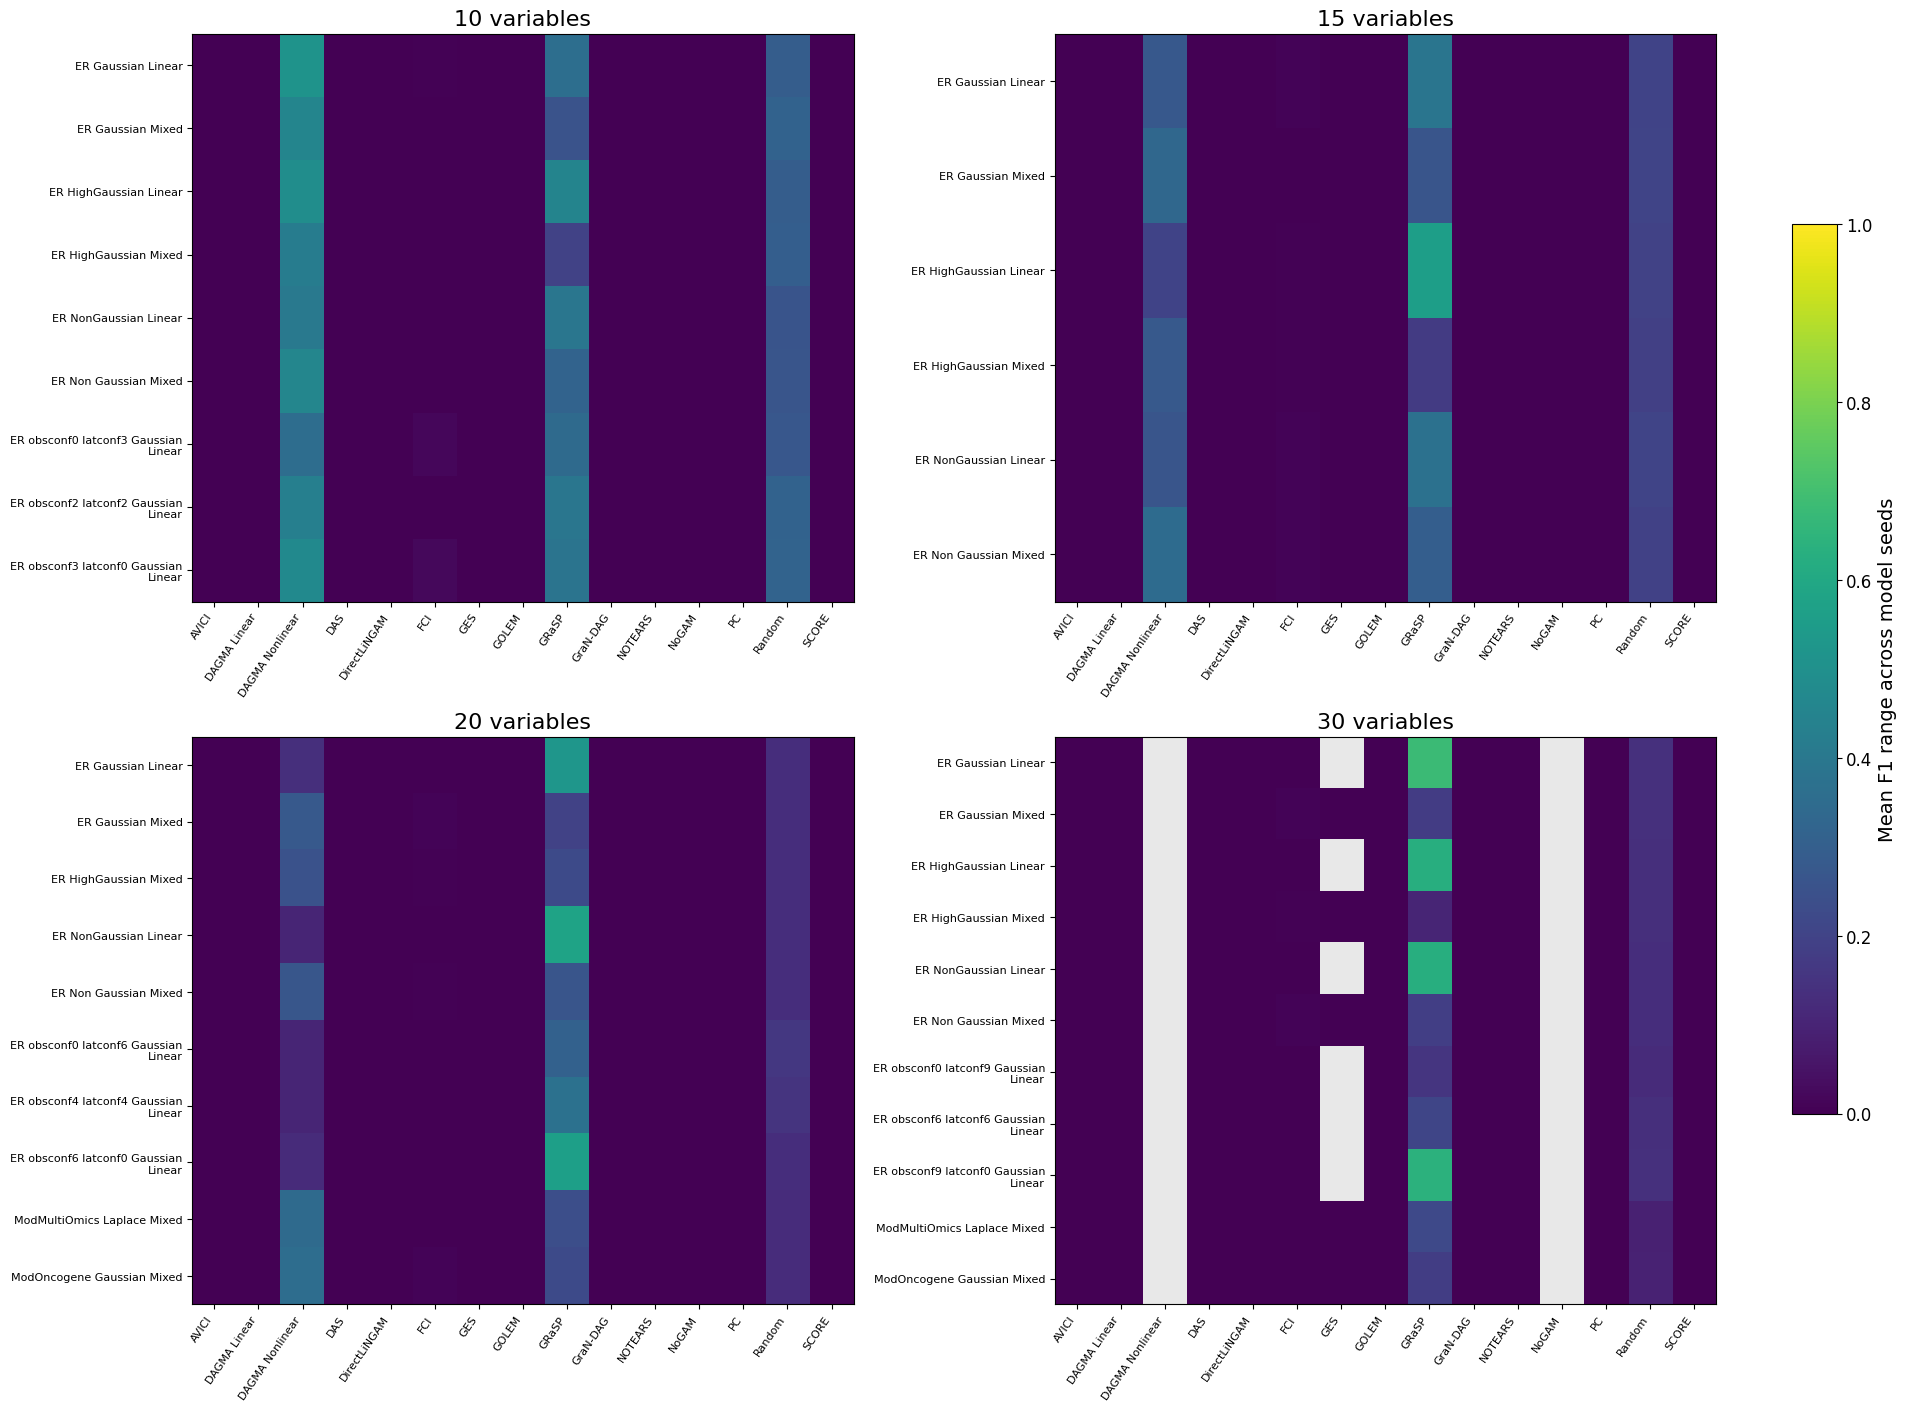

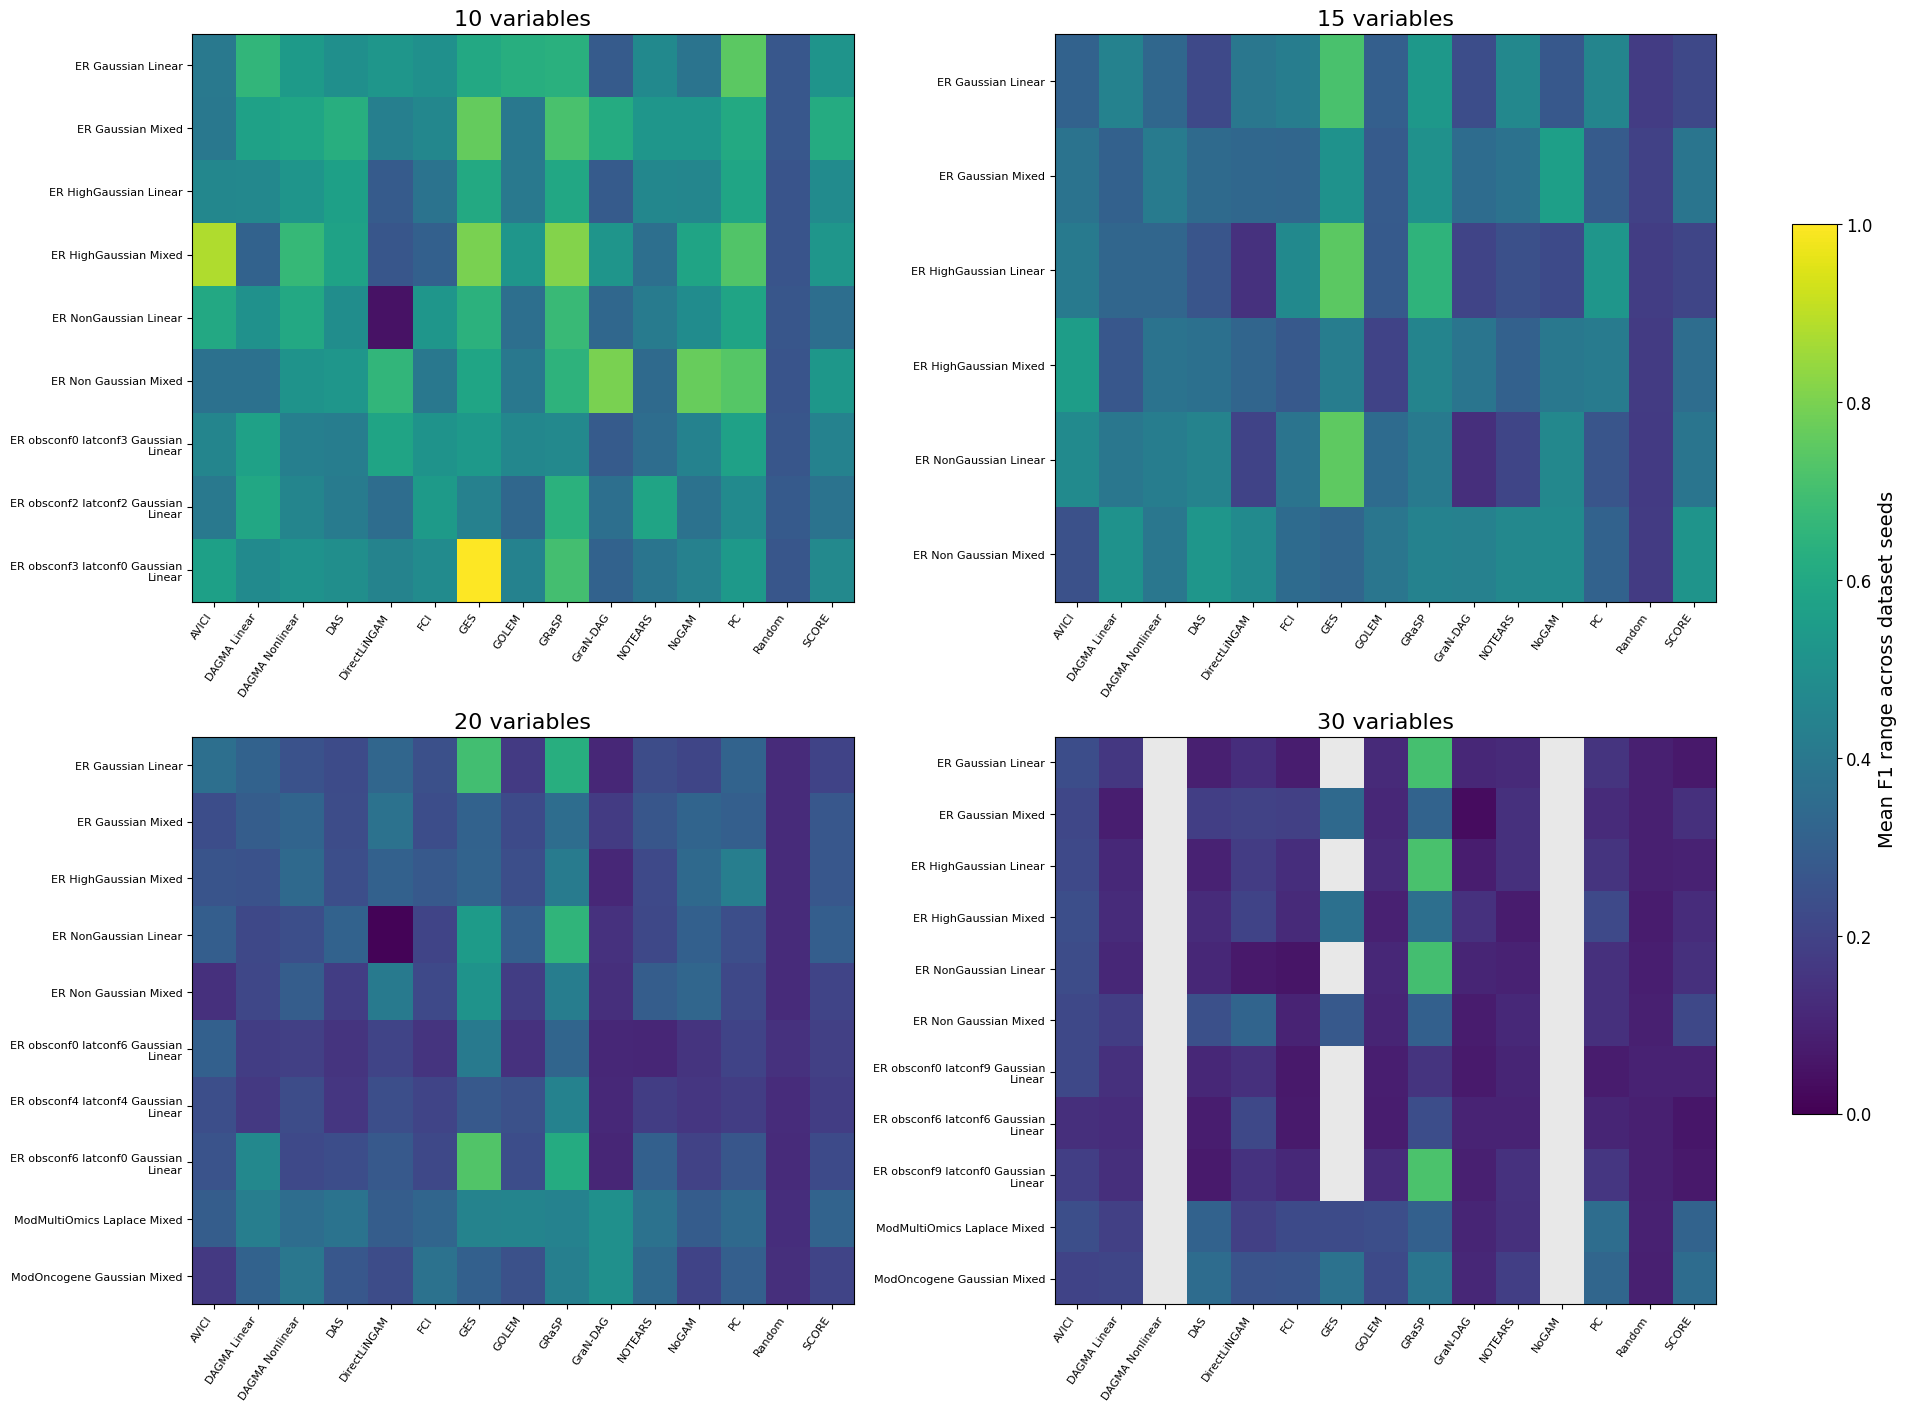

In [11]:
tables = pd.read_pickle(ROOT / "results/analysis/benchmark.pkl")
model_summary = tables['model_summary']
dataset_summary = tables['dataset_summary']
display(model_summary)
display(dataset_summary)
plot_conditions(model_summary, "mean", "Mean F1 range across model seeds", "model_seed_stability.pdf", bounded=True)
plot_conditions(dataset_summary, "mean", "Mean F1 range across dataset seeds", "dataset_seed_stability.pdf", bounded=True)


## Sortability and correlations across all conditions

Varsortability and R²-sortability for every stored dataset instance: all 36 benchmark conditions and all six held-out evaluation families. Associations with F1 use dataset-level averages over model seeds.


In [12]:
from statistical_methods import holm


In [13]:
# Sortability and correlations are prepared outside the notebook.


In [14]:
tables = pd.read_pickle(ROOT / "results/analysis/sortability.pkl")
sortability_all = tables['sortability_all']
corr = tables['corr']
display(sortability_all)
display(corr)


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations,n_nodes
0,10nodes_ER_obsconf0_latconf0_Gaussian_Linear,11,benchmark,True,datasets/synthetic/10nodes_ER_obsconf0_latconf...,0.878788,0.696970,33,29.0,0.0,23,0,10,2000,10
1,10nodes_ER_obsconf0_latconf0_Gaussian_Linear,19,benchmark,True,datasets/synthetic/10nodes_ER_obsconf0_latconf...,1.000000,0.500000,14,14.0,0.0,7,0,10,2000,10
2,10nodes_ER_obsconf0_latconf0_Gaussian_Linear,27,benchmark,True,datasets/synthetic/10nodes_ER_obsconf0_latconf...,1.000000,0.894737,19,19.0,0.0,17,0,10,2000,10
3,10nodes_ER_obsconf0_latconf0_Gaussian_Linear,30,benchmark,True,datasets/synthetic/10nodes_ER_obsconf0_latconf...,0.923077,0.692308,26,24.0,0.0,18,0,10,2000,10
4,10nodes_ER_obsconf0_latconf0_Gaussian_Linear,42,benchmark,True,datasets/synthetic/10nodes_ER_obsconf0_latconf...,1.000000,0.869565,23,23.0,0.0,20,0,10,2000,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
625,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,220,tuned_untuned,True,datasets/synthetic/20nodes_ModOncogene_obsconf...,0.234694,0.193878,98,23.0,0.0,19,0,20,2000,20
626,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,235,tuned_untuned,True,datasets/synthetic/20nodes_ModOncogene_obsconf...,0.421687,0.253012,83,35.0,0.0,21,0,20,2000,20
627,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,306,tuned_untuned,True,datasets/synthetic/20nodes_ModOncogene_obsconf...,0.623762,0.584158,101,63.0,0.0,59,0,20,2000,20
628,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,400,tuned_untuned,True,datasets/synthetic/20nodes_ModOncogene_obsconf...,0.777778,0.611111,54,42.0,0.0,33,0,20,2000,20


,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
0,benchmark,untuned,10nodes_ER_obsconf0_latconf0_Gaussian_Linear,AVICI,r2_sortability,15,0.071556,0.799945,estimated,1.0
1,benchmark,untuned,10nodes_ER_obsconf0_latconf0_Gaussian_Linear,AVICI,varsortability,15,0.358279,0.189765,estimated,1.0
2,benchmark,untuned,10nodes_ER_obsconf0_latconf0_Gaussian_Linear,DAGMA_Linear,r2_sortability,15,-0.641645,0.009924,estimated,1.0
3,benchmark,untuned,10nodes_ER_obsconf0_latconf0_Gaussian_Linear,DAGMA_Linear,varsortability,15,-0.373030,0.170860,estimated,1.0
4,benchmark,untuned,10nodes_ER_obsconf0_latconf0_Gaussian_Linear,DAGMA_Nonlinear,r2_sortability,15,-0.032143,0.909462,estimated,1.0
...,...,...,...,...,...,...,...,...,...,...
1319,tuned_untuned,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,PC,varsortability,15,0.216265,0.438839,estimated,1.0
1320,tuned_untuned,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,Random,r2_sortability,15,-0.214286,0.443141,estimated,1.0
1321,tuned_untuned,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,Random,varsortability,15,-0.003571,0.989921,estimated,1.0
1322,tuned_untuned,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,SCORE,r2_sortability,15,-0.396429,0.143495,estimated,1.0


### Family summaries


In [15]:
family_summary = pd.read_pickle(ROOT / "results/analysis/sortability.pkl")["family_summary"]
display(family_summary)


,study,dataset,n_nodes,dataset_instances,varsortability_mean,varsortability_std,r2_sortability_mean,r2_sortability_std
0,benchmark,10nodes_ER_obsconf0_latconf0_Gaussian_Linear,10,15,0.970212,0.037060,0.750205,0.154758
1,benchmark,10nodes_ER_obsconf0_latconf0_Gaussian_Mixed,10,15,0.860045,0.101245,0.496597,0.212774
2,benchmark,10nodes_ER_obsconf0_latconf0_HighGaussian_Linear,10,15,0.955838,0.051057,0.738237,0.170792
3,benchmark,10nodes_ER_obsconf0_latconf0_HighGaussian_Mixed,10,15,0.717002,0.176881,0.350600,0.144961
4,benchmark,10nodes_ER_obsconf0_latconf0_NonGaussian_Linear,10,15,0.885421,0.106224,0.664557,0.229735
5,benchmark,10nodes_ER_obsconf0_latconf0_Non_Gaussian_Mixed,10,15,0.374412,0.199530,0.493439,0.176658
6,benchmark,10nodes_ER_obsconf0_latconf3_Gaussian_Linear,10,15,0.976055,0.028892,0.716214,0.181907
7,benchmark,10nodes_ER_obsconf2_latconf2_Gaussian_Linear,10,15,0.963205,0.060288,0.779599,0.177673
8,benchmark,10nodes_ER_obsconf3_latconf0_Gaussian_Linear,10,15,0.971515,0.049515,0.742311,0.161609
9,benchmark,15nodes_ER_obsconf0_latconf0_Gaussian_Linear,15,15,0.982660,0.016322,0.848588,0.106791


### All benchmark datasets


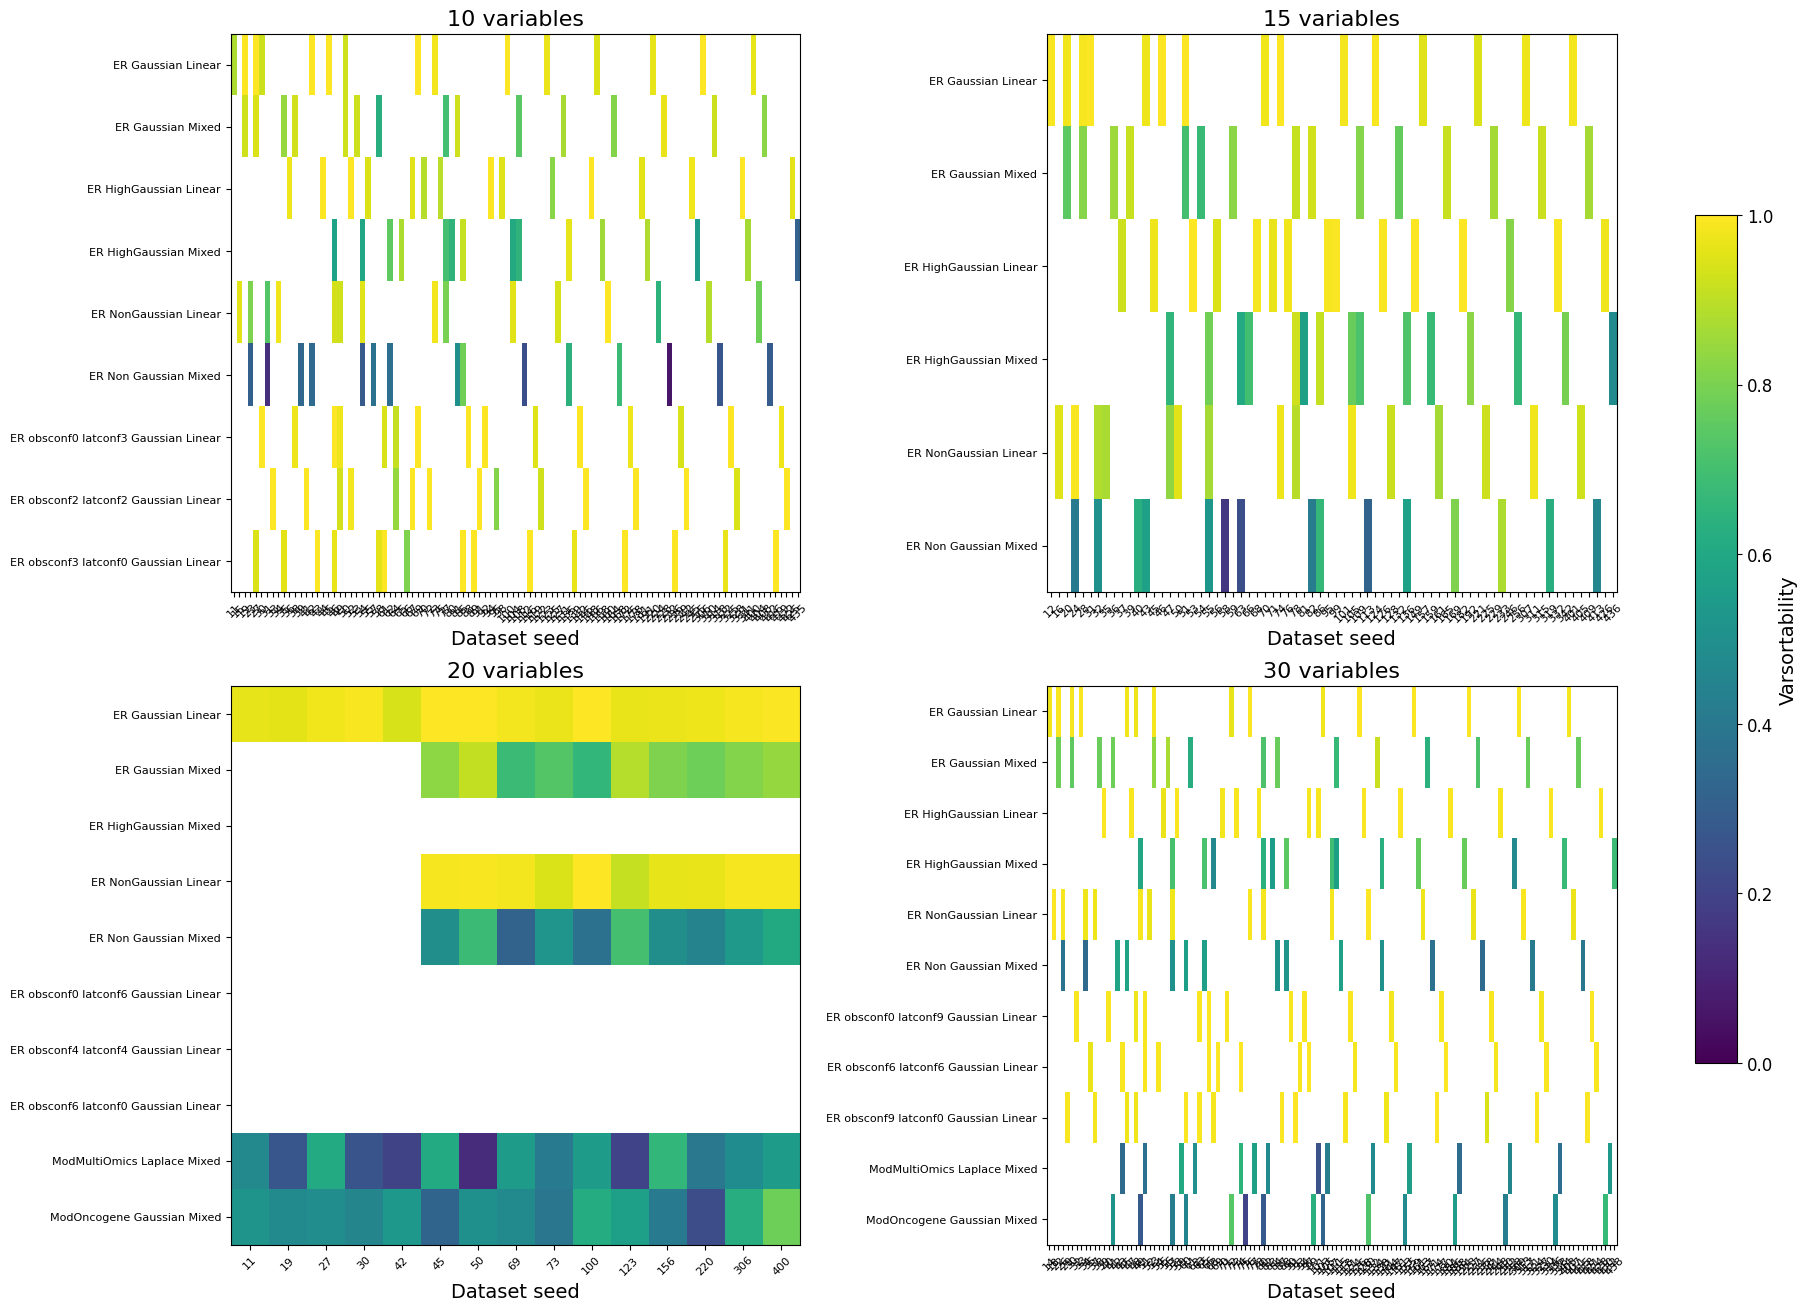

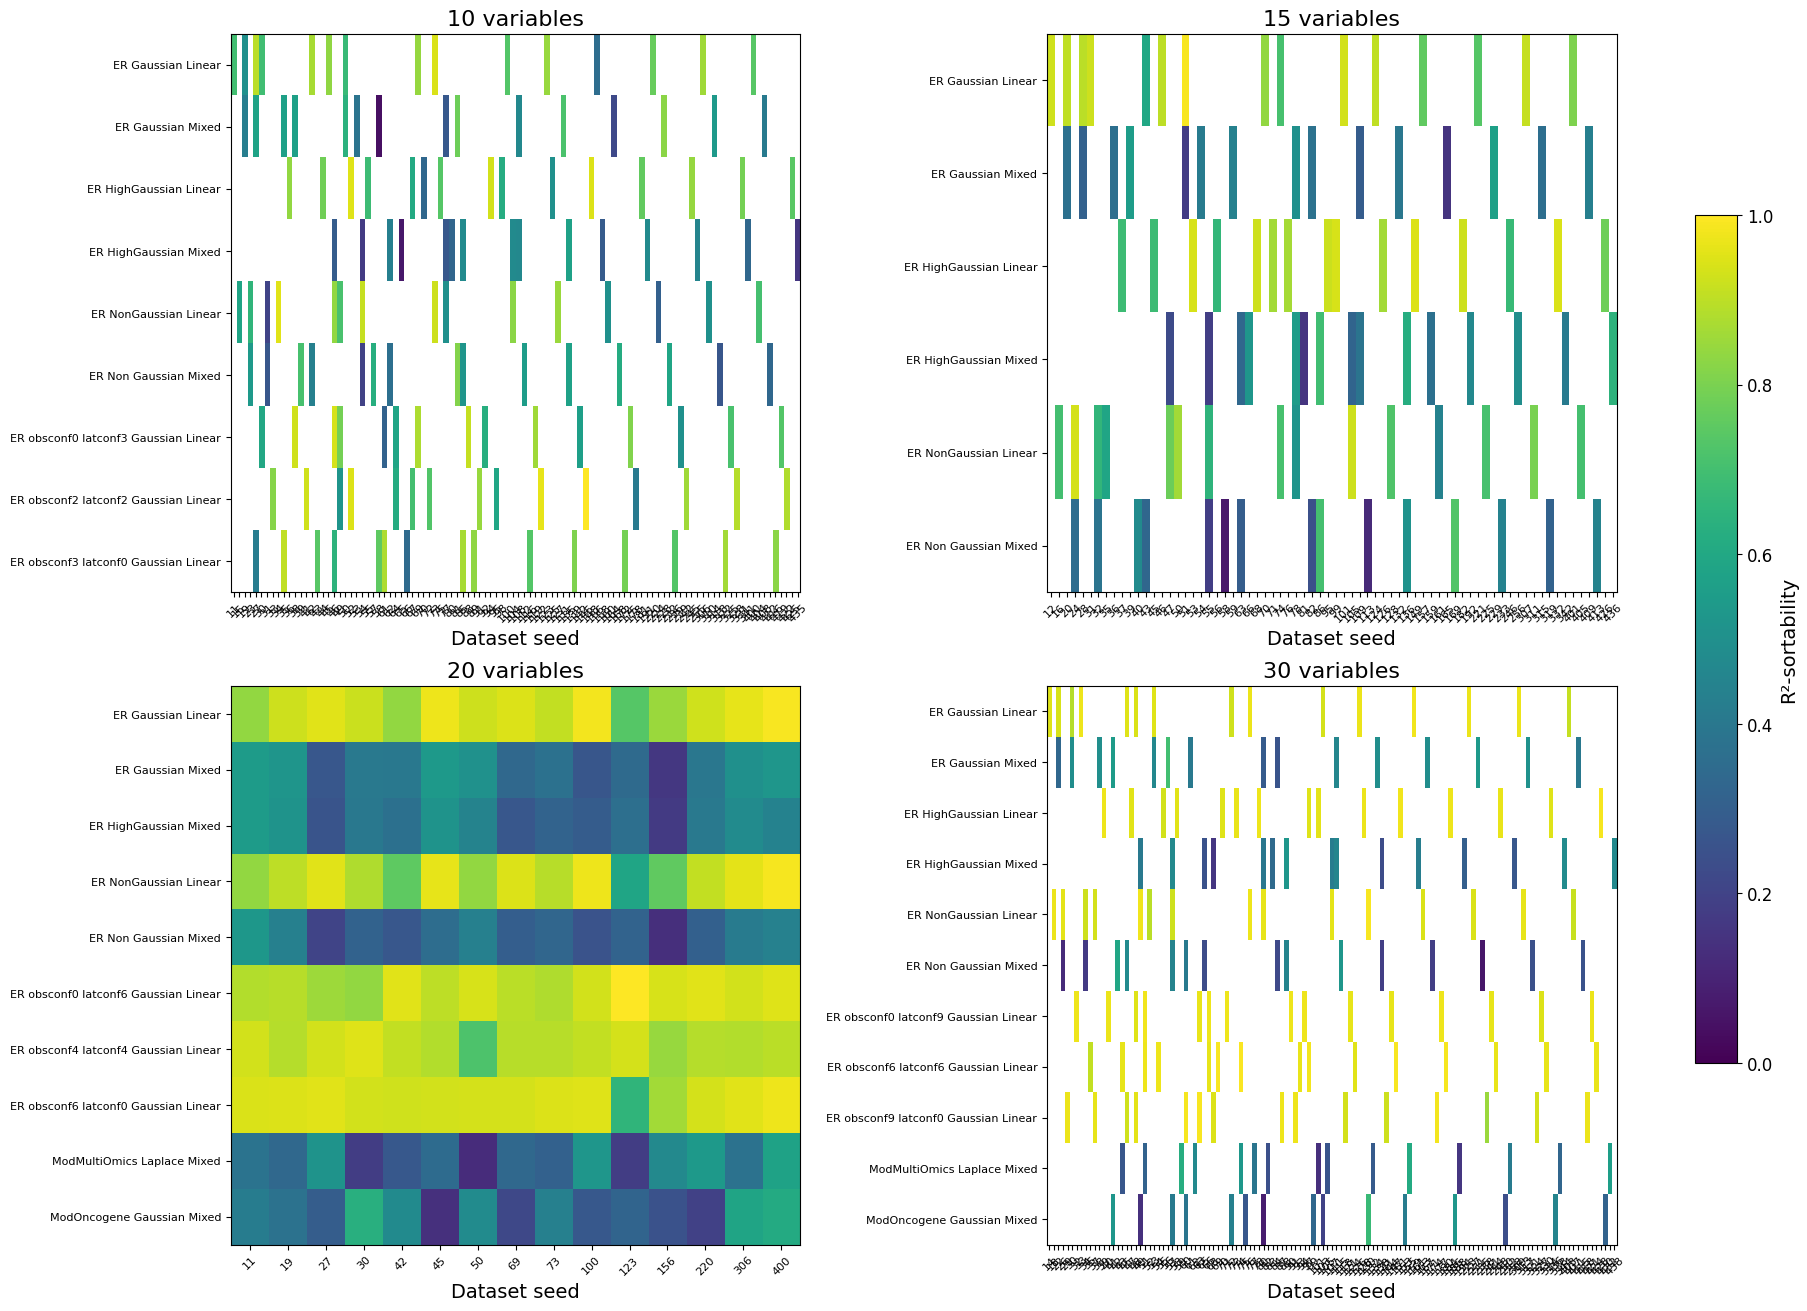

In [16]:
for score, label in [('varsortability', 'Varsortability'), ('r2_sortability', 'R²-sortability')]:
    benchmark = sortability_all.loc[sortability_all.study.eq('benchmark')]
    fig, axes = plt.subplots(2, 2, figsize=(18, 13), constrained_layout=True)
    for ax, size in zip(axes.flat, sorted(benchmark.n_nodes.unique())):
        part = benchmark.loc[benchmark.n_nodes.eq(size)]
        values = part.pivot(index='dataset', columns='dataset_seed', values=score)
        im = ax.imshow(np.ma.masked_invalid(values.to_numpy(float)), vmin=0, vmax=1, cmap='viridis', aspect='auto')
        labels = [name.split('nodes_', 1)[1].replace('_obsconf0_latconf0', '').replace('_', ' ') for name in values.index]
        ax.set_yticks(range(len(values)), labels, fontsize=8)
        ax.set_xticks(range(len(values.columns)), values.columns, rotation=45, fontsize=8)
        ax.set_title(f'{int(size)} variables')
        ax.set_xlabel('Dataset seed')
    fig.colorbar(im, ax=axes.ravel().tolist(), label=label, shrink=0.7)
    display(fig)
    plt.close(fig)


## Gaussian-linear sorting baseline

Displays the saved varsortability, R²-sortability and sorting-baseline measurements for the Gaussian-linear benchmark instances, with 2,000 observations per instance.


### Raw-data sortability


In [17]:
sortability = pd.read_pickle(ROOT / "results/analysis/sortability.pkl")["gaussian"]
baseline = pd.read_pickle(ROOT / "results/analysis/sortability.pkl")["r2_baseline"]
comparison = sortability.merge(baseline[["dataset", "dataset_seed", "f1"]],
                              on=["dataset", "dataset_seed"])


In [18]:
display(comparison[["dataset", "dataset_seed", "n_observations", "varsortability", "r2_sortability", "f1"]])


,dataset,dataset_seed,n_observations,varsortability,r2_sortability,f1
0,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,11,2000,0.963351,0.837696,0.506494
1,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,19,2000,0.958491,0.924528,0.574850
2,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,27,2000,0.978125,0.956250,0.577778
3,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,30,2000,0.991620,0.918994,0.477157
4,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,42,2000,0.938416,0.838710,0.441026
5,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,45,2000,0.996226,0.973585,0.643836
6,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,50,2000,0.996094,0.921875,0.477612
7,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,69,2000,0.983264,0.945607,0.554217
8,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,73,2000,0.971671,0.909348,0.416244
9,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,100,2000,1.000000,0.980695,0.718310


## High-variance Gaussian-linear control

This control is kept separately from the ten conditions in the main 20-variable comparison. Scores are averaged across model seeds within each dataset instance. The reference has the same noise family and linear mechanism with the lower Gaussian noise variance.


,setting,model,mean,std,size
0,Gaussian,AVICI,0.446184,0.113053,15
1,Gaussian,DAGMA_Linear,0.189695,0.088932,15
2,Gaussian,DAGMA_Nonlinear,0.127557,0.061664,15
3,Gaussian,DAS,0.107358,0.056255,15
4,Gaussian,DirectLiNGAM,0.333148,0.089045,15
5,Gaussian,FCI,0.088630,0.063446,15
6,Gaussian,GES,0.393808,0.179204,15
7,Gaussian,GOLEM,0.125411,0.047655,15
8,Gaussian,GRaSP,0.794479,0.098063,15
9,Gaussian,GraNDAG,0.050703,0.033839,15


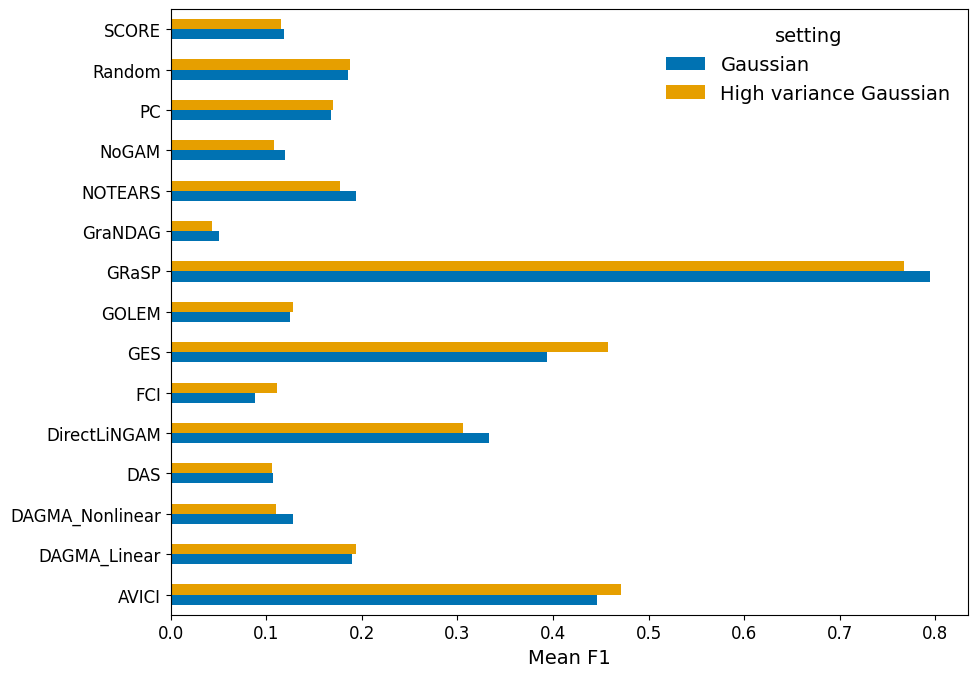

In [19]:
tables = pd.read_pickle(ROOT / "results/analysis/control.pkl")
summary = tables['summary']
wide = tables['wide']
display(summary)
ax = wide.plot.barh(figsize=(10, 7), xlabel='Mean F1', ylabel='')
ax.figure.tight_layout()
display(ax.figure)
plt.close(ax.figure)


## Detailed results by family

The same saved final measurements are used throughout. By default, this section displays every available family. Set `family` to one of the printed names to focus the presentation. Sortability panels are shown only when enough observations are available; missing raw-data measures remain unavailable.


In [20]:
sources = th.load_final_results()
family_fits = sources['benchmark_with_biological']
family_tables = pd.read_pickle(ROOT / "results/analysis/families.pkl")
sort_tables = pd.read_pickle(ROOT / "results/analysis/sortability.pkl")
family = None  # None displays every available family; set a name to focus on one.
available_families = sorted(family_fits.dataset.unique())
selected_families = available_families if family is None else [family]
print('Available families:')
for name in available_families:
    print(' -', name)


Available families:
 - 20nodes_ER_obsconf0_latconf0_Gaussian_Linear
 - 20nodes_ER_obsconf0_latconf0_Gaussian_Mixed
 - 20nodes_ER_obsconf0_latconf0_HighGaussian_Mixed
 - 20nodes_ER_obsconf0_latconf0_NonGaussian_Linear
 - 20nodes_ER_obsconf0_latconf0_Non_Gaussian_Mixed
 - 20nodes_ER_obsconf0_latconf6_Gaussian_Linear
 - 20nodes_ER_obsconf4_latconf4_Gaussian_Linear
 - 20nodes_ER_obsconf6_latconf0_Gaussian_Linear
 - 20nodes_ModMultiOmics_obsconf0_latconf0_Laplace_Mixed
 - 20nodes_ModOncogene_obsconf0_latconf0_Gaussian_Mixed



20nodes_ER_obsconf0_latconf0_Gaussian_Linear

20nodes_ER_obsconf0_latconf0_Gaussian_Mixed

20nodes_ER_obsconf0_latconf0_HighGaussian_Mixed

20nodes_ER_obsconf0_latconf0_NonGaussian_Linear

20nodes_ER_obsconf0_latconf0_Non_Gaussian_Mixed

20nodes_ER_obsconf0_latconf6_Gaussian_Linear

20nodes_ER_obsconf4_latconf4_Gaussian_Linear

20nodes_ER_obsconf6_latconf0_Gaussian_Linear

20nodes_ModMultiOmics_obsconf0_latconf0_Laplace_Mixed

20nodes_ModOncogene_obsconf0_latconf0_Gaussian_Mixed


,model,mean,std,size
0,AVICI,0.446184,0.113053,15
1,DAGMA_Linear,0.189695,0.088932,15
2,DAGMA_Nonlinear,0.127557,0.061664,15
3,DAS,0.107358,0.056255,15
4,DirectLiNGAM,0.333148,0.089045,15
5,FCI,0.088630,0.063446,15
6,GES,0.393808,0.179204,15
7,GOLEM,0.125411,0.047655,15
8,GRaSP,0.794479,0.098063,15
9,GraNDAG,0.050703,0.033839,15


,model,mean,std,size
0,AVICI,56.400000,10.581655,15
1,DAGMA_Linear,60.266667,8.995766,15
2,DAGMA_Nonlinear,72.853333,10.923433,15
3,DAS,104.666667,12.821114,15
4,DirectLiNGAM,105.600000,17.356761,15
5,FCI,59.875556,9.870297,15
6,GES,89.400000,34.442084,15
7,GOLEM,85.533333,11.831355,15
8,GRaSP,23.168889,14.850383,15
9,GraNDAG,56.533333,6.390469,15


,model,mean,std,size
0,AVICI,0.476502,0.110435,15
1,DAGMA_Linear,0.245147,0.108341,15
2,DAGMA_Nonlinear,0.148249,0.077491,15
3,DAS,0.086002,0.045346,15
4,DirectLiNGAM,0.238864,0.068792,15
5,FCI,0.612374,0.262024,15
6,GES,0.315706,0.188638,15
7,GOLEM,0.117199,0.045179,15
8,GRaSP,0.790400,0.124021,15
9,GraNDAG,0.453333,0.309133,15


,model,mean,std,size
0,AVICI,0.432627,0.133500,15
1,DAGMA_Linear,0.156707,0.077951,15
2,DAGMA_Nonlinear,0.115402,0.054020,15
3,DAS,0.143574,0.075398,15
4,DirectLiNGAM,0.552912,0.126851,15
5,FCI,0.049363,0.038996,15
6,GES,0.550486,0.150187,15
7,GOLEM,0.136634,0.052642,15
8,GRaSP,0.806818,0.071486,15
9,GraNDAG,0.027249,0.018522,15


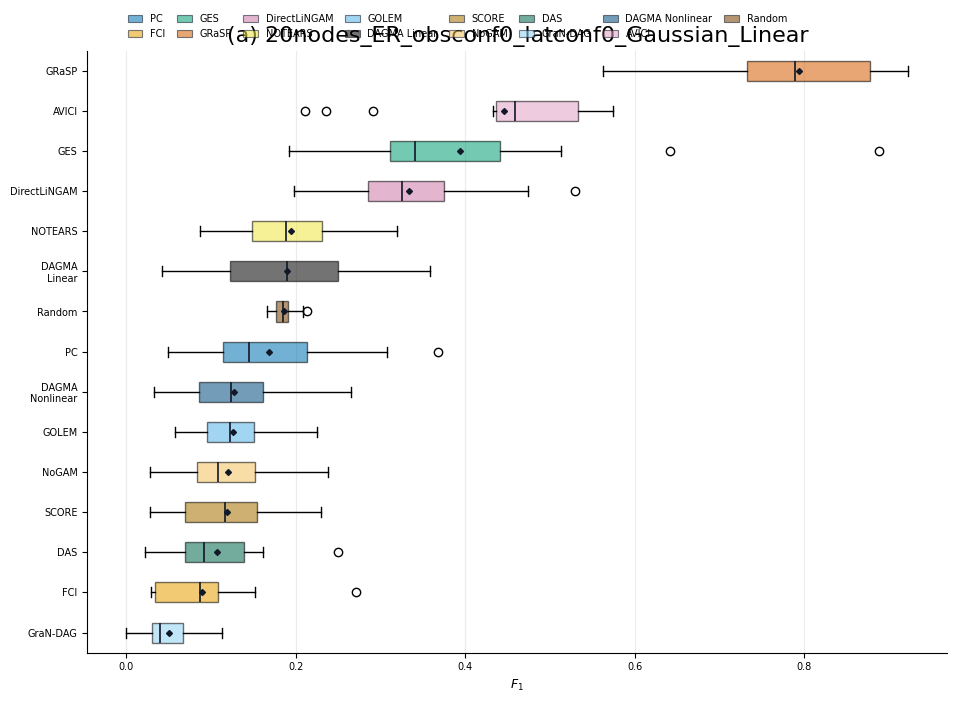

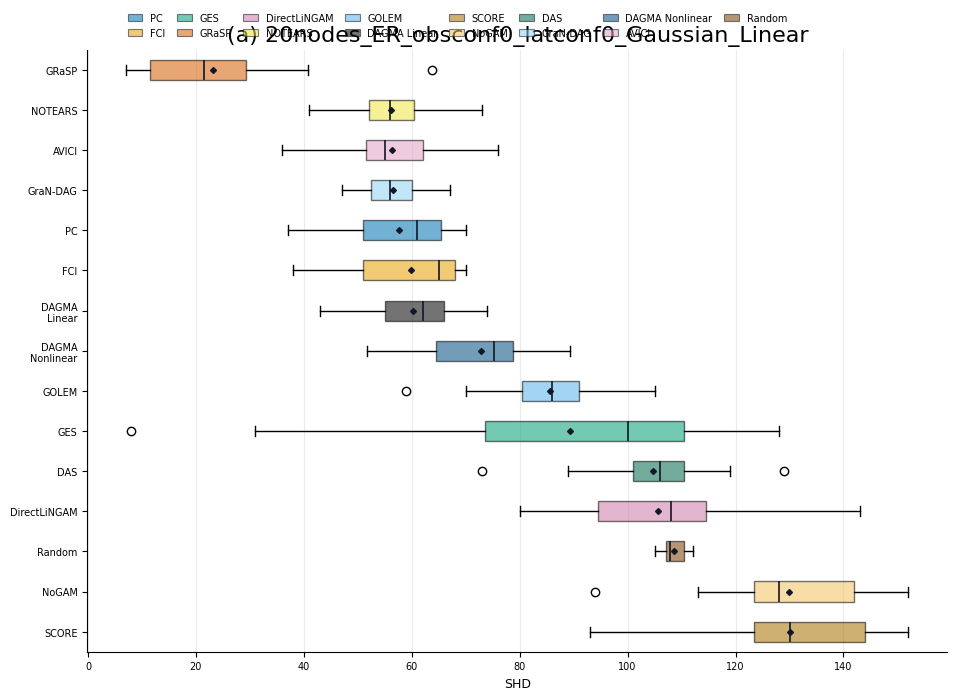

,dataset_seed,model,f1_range
0,11,AVICI,0.000000
1,11,DAGMA_Linear,0.000000
2,11,DAGMA_Nonlinear,0.141954
3,11,DAS,0.000000
4,11,DirectLiNGAM,0.000000
5,11,FCI,0.000000
6,11,GES,0.000000
7,11,GOLEM,0.000000
8,11,GRaSP,0.316327
9,11,GraNDAG,0.000000


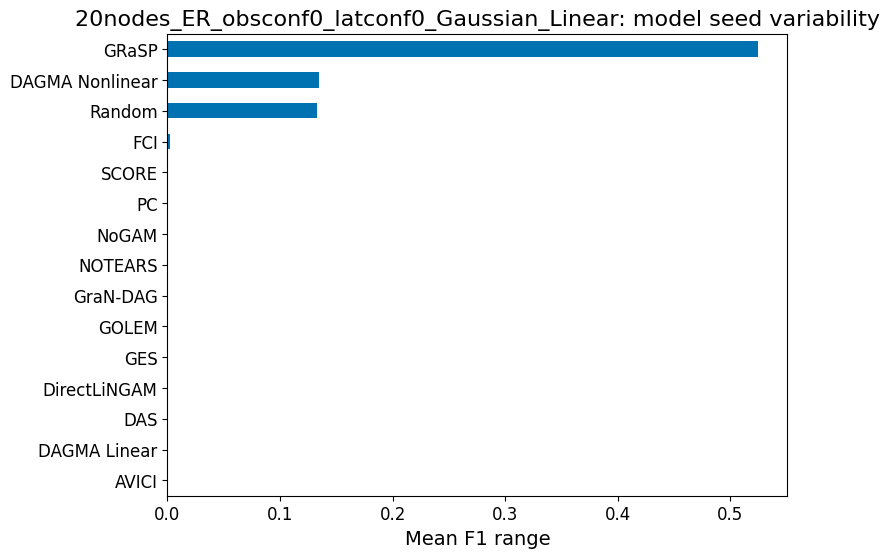

,model_seed,model,f1_range
0,0,AVICI,0.364186
1,0,DAGMA_Linear,0.316228
2,0,DAGMA_Nonlinear,0.295022
3,0,DAS,0.227654
4,0,DirectLiNGAM,0.331980
5,0,FCI,0.242615
6,0,GES,0.696970
7,0,GOLEM,0.168421
8,0,GRaSP,0.728261
9,0,GraNDAG,0.112676


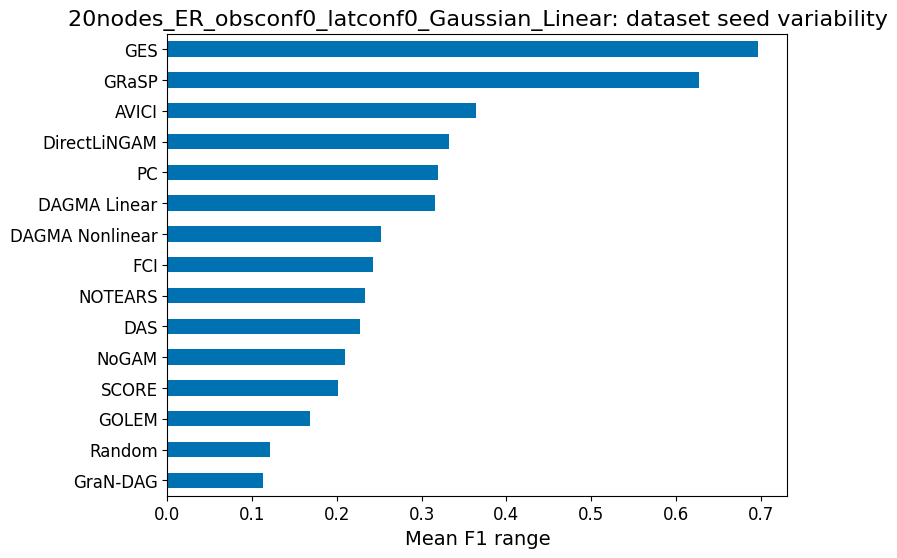

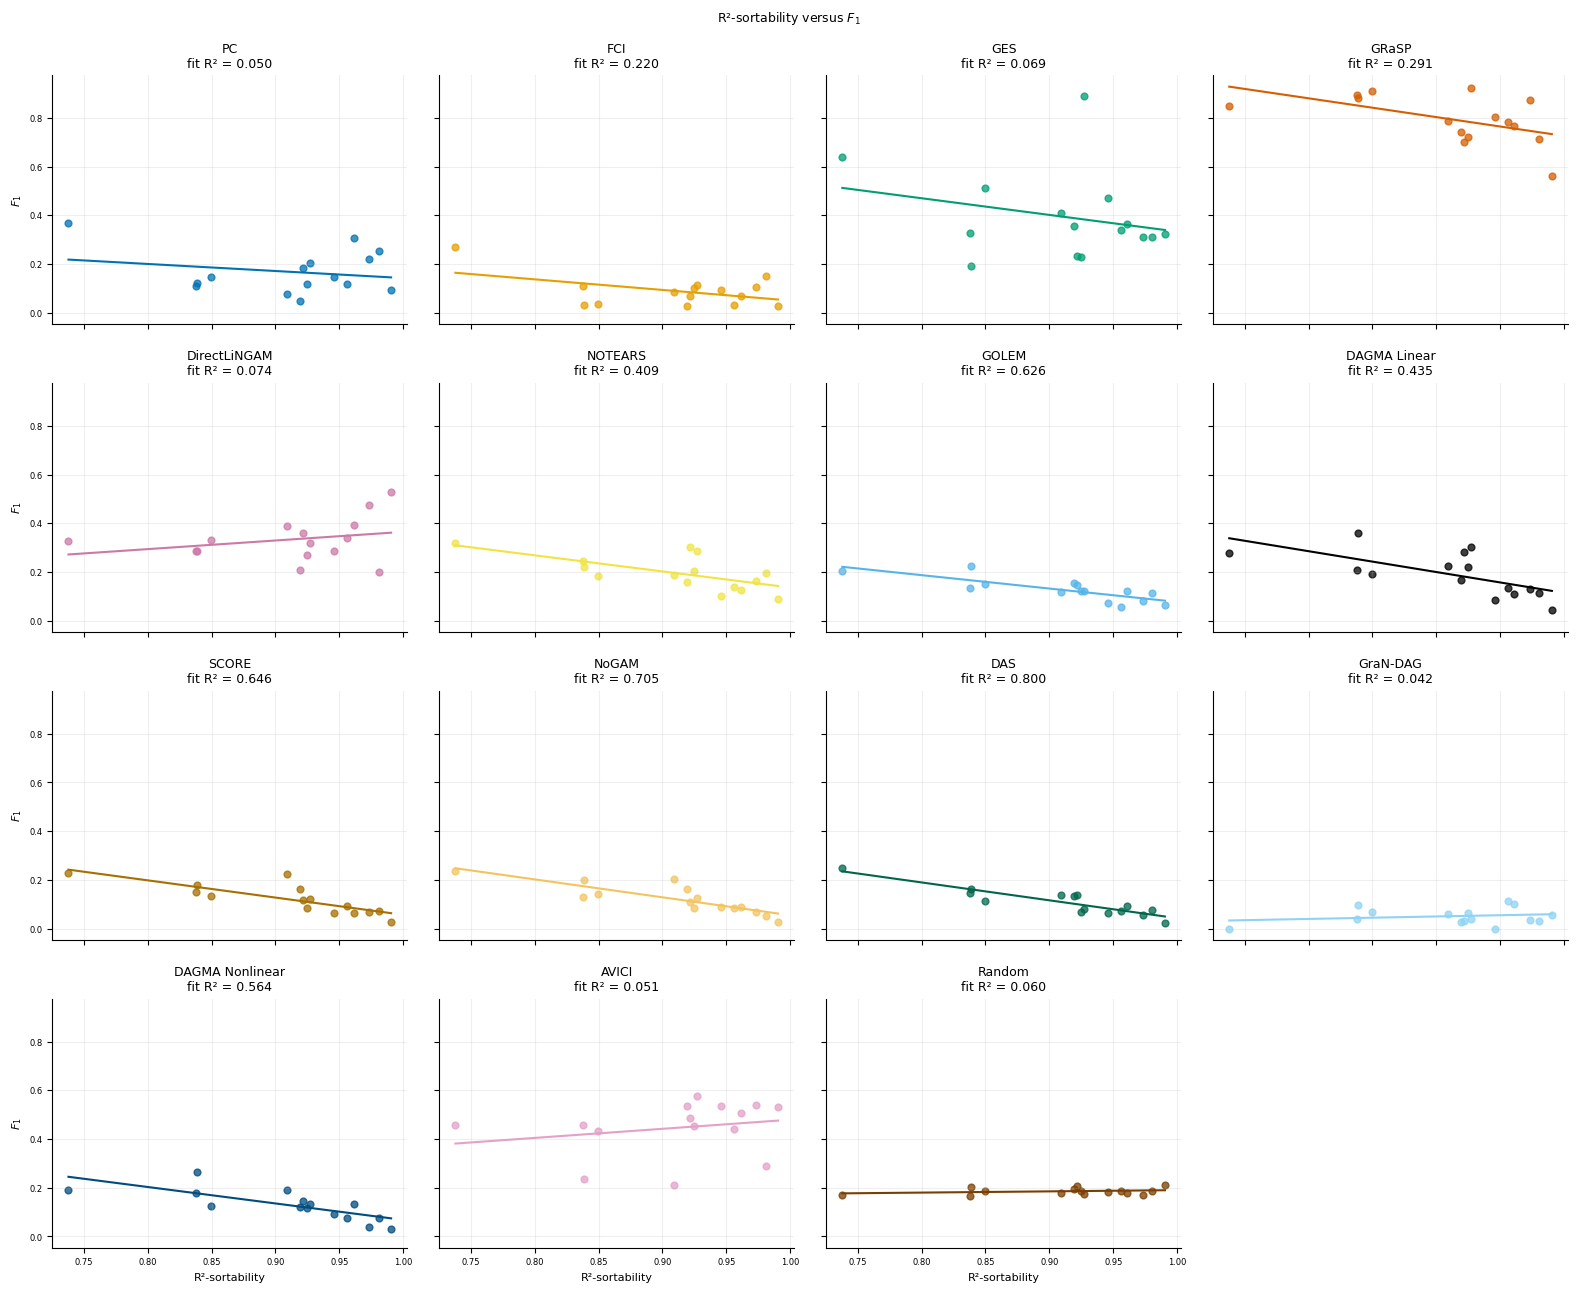

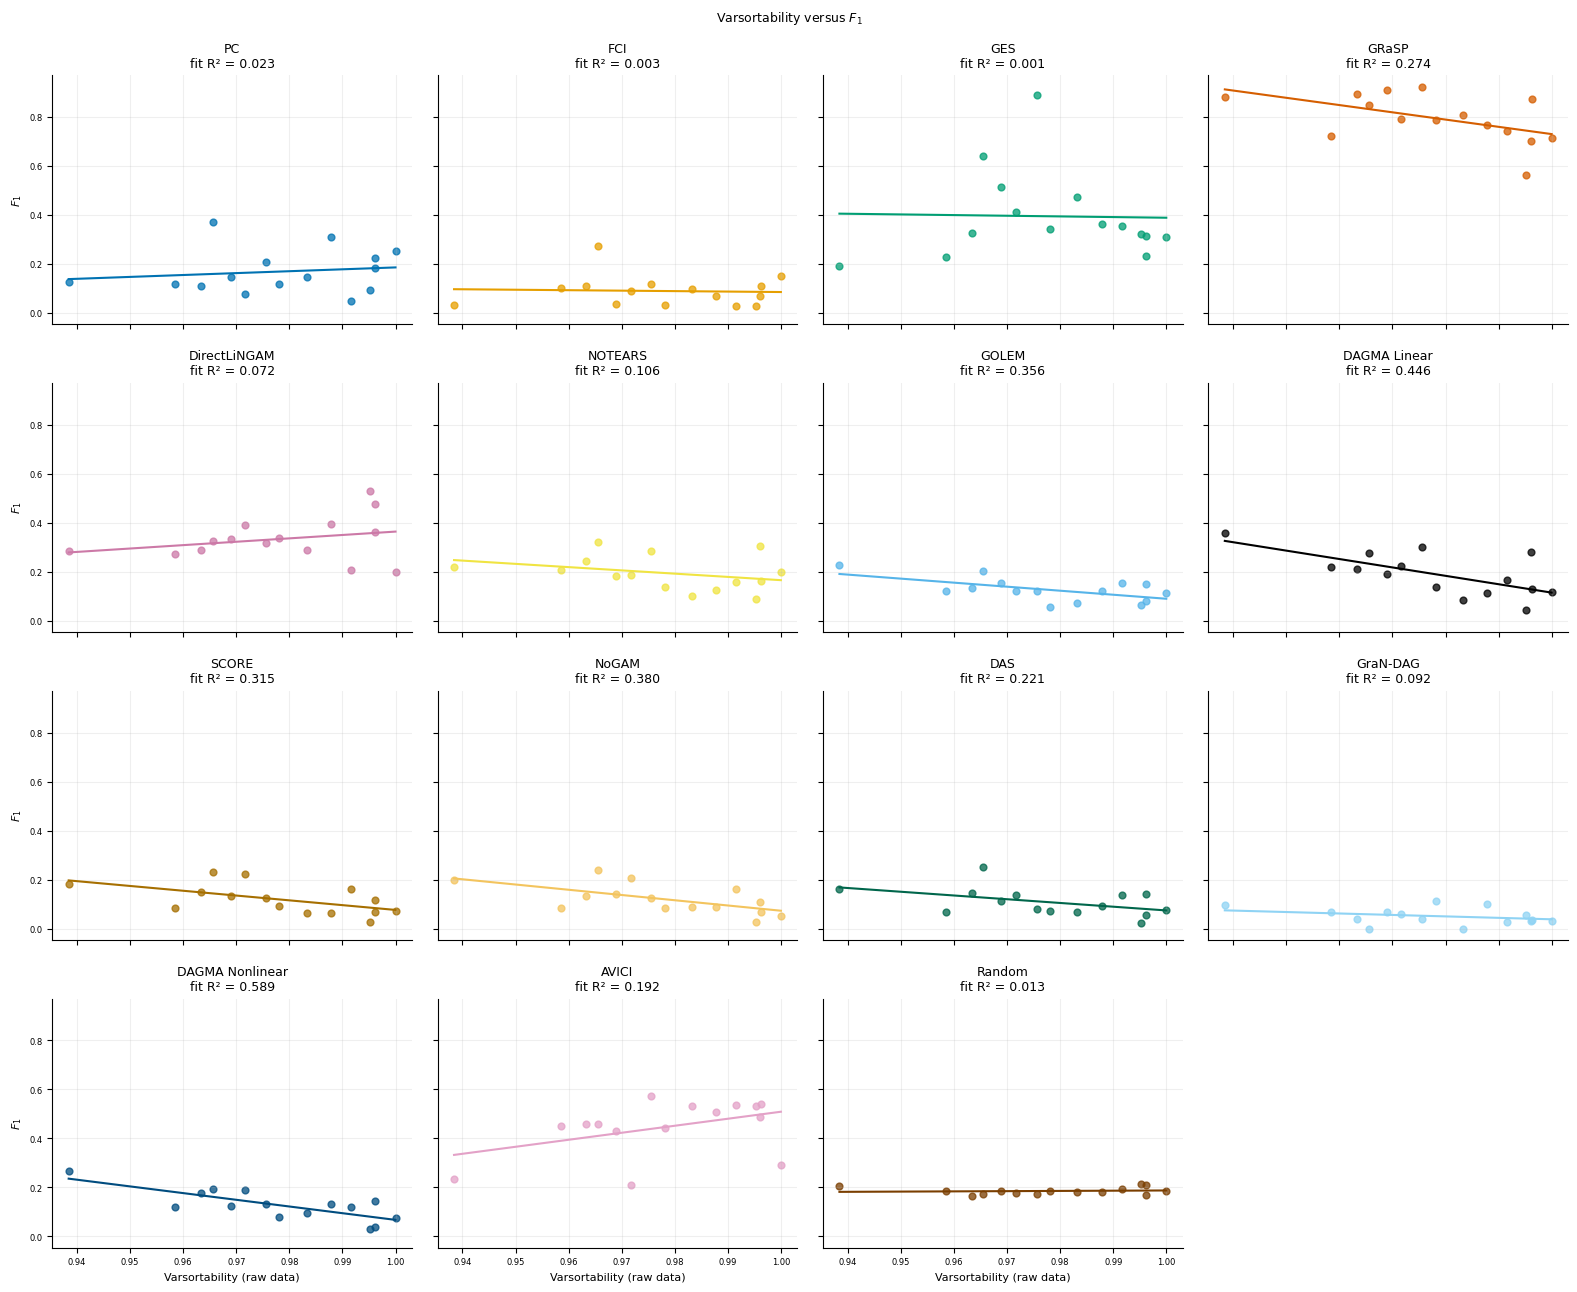

,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
450,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,AVICI,r2_sortability,15,0.350000,0.200945,estimated,1.000000
451,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,AVICI,varsortability,15,0.421429,0.117699,estimated,1.000000
452,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,DAGMA_Linear,r2_sortability,15,-0.717857,0.002581,estimated,1.000000
453,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,DAGMA_Linear,varsortability,15,-0.578571,0.023847,estimated,1.000000
454,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,DAGMA_Nonlinear,r2_sortability,15,-0.839286,0.000091,estimated,0.045136
455,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,DAGMA_Nonlinear,varsortability,15,-0.635714,0.010861,estimated,1.000000
456,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,DAS,r2_sortability,15,-0.860714,0.000038,estimated,0.018913
457,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,DAS,varsortability,15,-0.485714,0.066426,estimated,1.000000
458,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,DirectLiNGAM,r2_sortability,15,0.289286,0.295665,estimated,1.000000
459,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,DirectLiNGAM,varsortability,15,0.275000,0.321211,estimated,1.000000


,model,mean,std,size
0,AVICI,0.480444,0.069760,15
1,DAGMA_Linear,0.138450,0.076816,15
2,DAGMA_Nonlinear,0.297817,0.064166,15
3,DAS,0.294669,0.080694,15
4,DirectLiNGAM,0.207968,0.113600,15
5,FCI,0.154243,0.070595,15
6,GES,0.573463,0.093367,15
7,GOLEM,0.136337,0.069971,15
8,GRaSP,0.586375,0.090946,15
9,GraNDAG,0.059634,0.053318,15


,model,mean,std,size
0,AVICI,44.800000,6.049793,15
1,DAGMA_Linear,57.666667,8.474050,15
2,DAGMA_Nonlinear,51.066667,6.782143,15
3,DAS,67.533333,13.075969,15
4,DirectLiNGAM,82.600000,23.200369,15
5,FCI,51.973333,10.092675,15
6,GES,40.200000,11.742475,15
7,GOLEM,62.666667,8.599557,15
8,GRaSP,34.808889,8.719832,15
9,GraNDAG,56.000000,5.744563,15


,model,mean,std,size
0,AVICI,0.671988,0.082322,15
1,DAGMA_Linear,0.245528,0.131100,15
2,DAGMA_Nonlinear,0.469713,0.081114,15
3,DAS,0.283061,0.079764,15
4,DirectLiNGAM,0.188666,0.117602,15
5,FCI,0.902451,0.175850,15
6,GES,0.619288,0.139448,15
7,GOLEM,0.201055,0.107780,15
8,GRaSP,0.809056,0.103790,15
9,GraNDAG,0.324673,0.245525,15


,model,mean,std,size
0,AVICI,0.382279,0.086409,15
1,DAGMA_Linear,0.097615,0.055842,15
2,DAGMA_Nonlinear,0.222130,0.059690,15
3,DAS,0.309669,0.087064,15
4,DirectLiNGAM,0.236931,0.111407,15
5,FCI,0.086388,0.042567,15
6,GES,0.545541,0.086460,15
7,GOLEM,0.104321,0.053249,15
8,GRaSP,0.465480,0.087634,15
9,GraNDAG,0.034327,0.032845,15


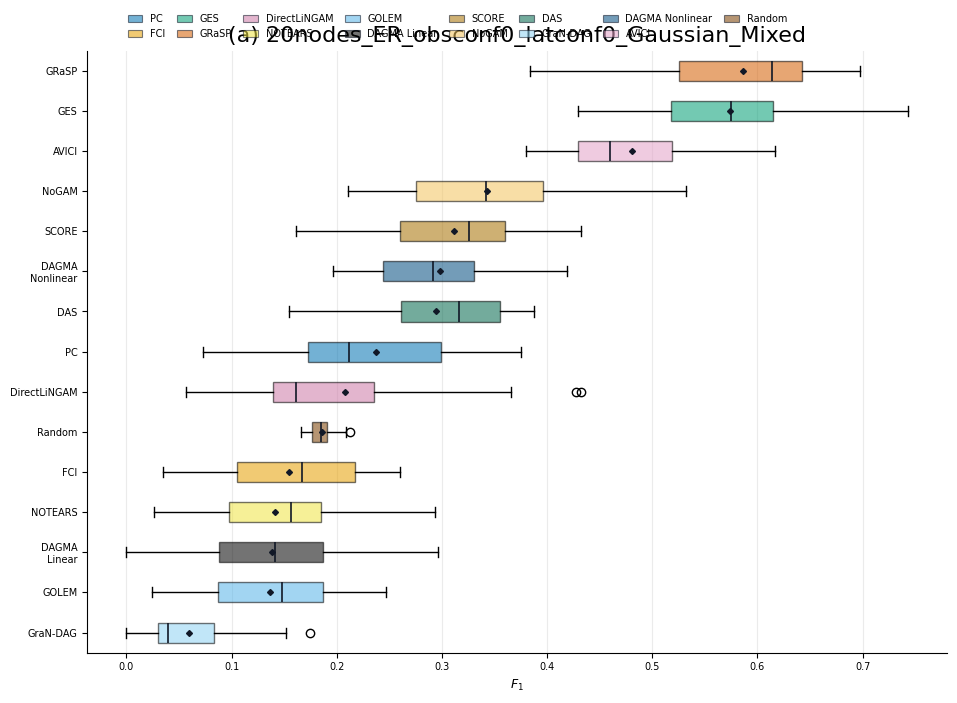

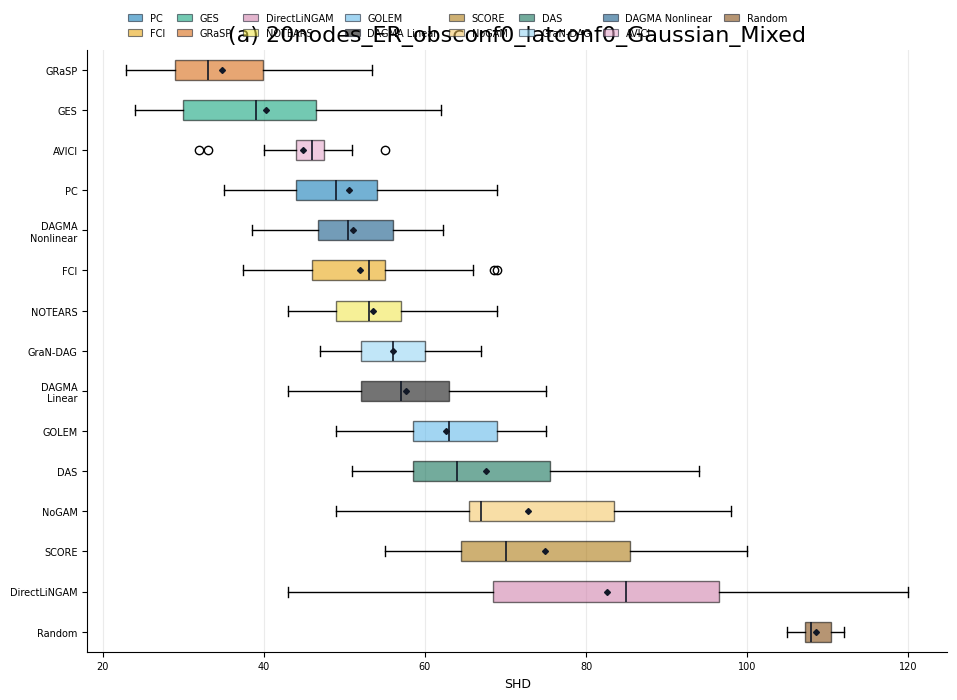

,dataset_seed,model,f1_range
0,11,AVICI,0.000000
1,11,DAGMA_Linear,0.000000
2,11,DAGMA_Nonlinear,0.224158
3,11,DAS,0.000000
4,11,DirectLiNGAM,0.000000
5,11,FCI,0.035639
6,11,GES,0.000000
7,11,GOLEM,0.000000
8,11,GRaSP,0.076923
9,11,GraNDAG,0.000000


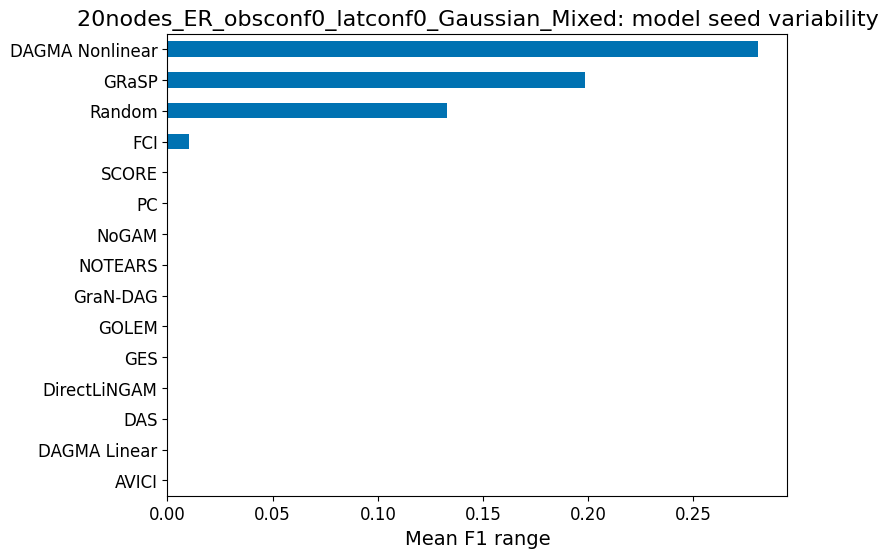

,model_seed,model,f1_range
0,0,AVICI,0.237076
1,0,DAGMA_Linear,0.296296
2,0,DAGMA_Nonlinear,0.354439
3,0,DAS,0.232167
4,0,DirectLiNGAM,0.376253
5,0,FCI,0.287218
6,0,GES,0.313733
7,0,GOLEM,0.223095
8,0,GRaSP,0.288304
9,0,GraNDAG,0.175000


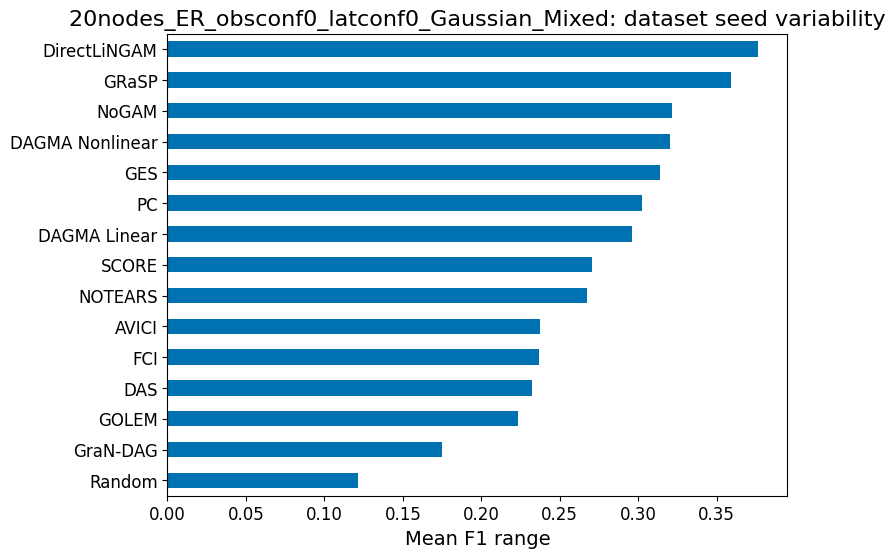

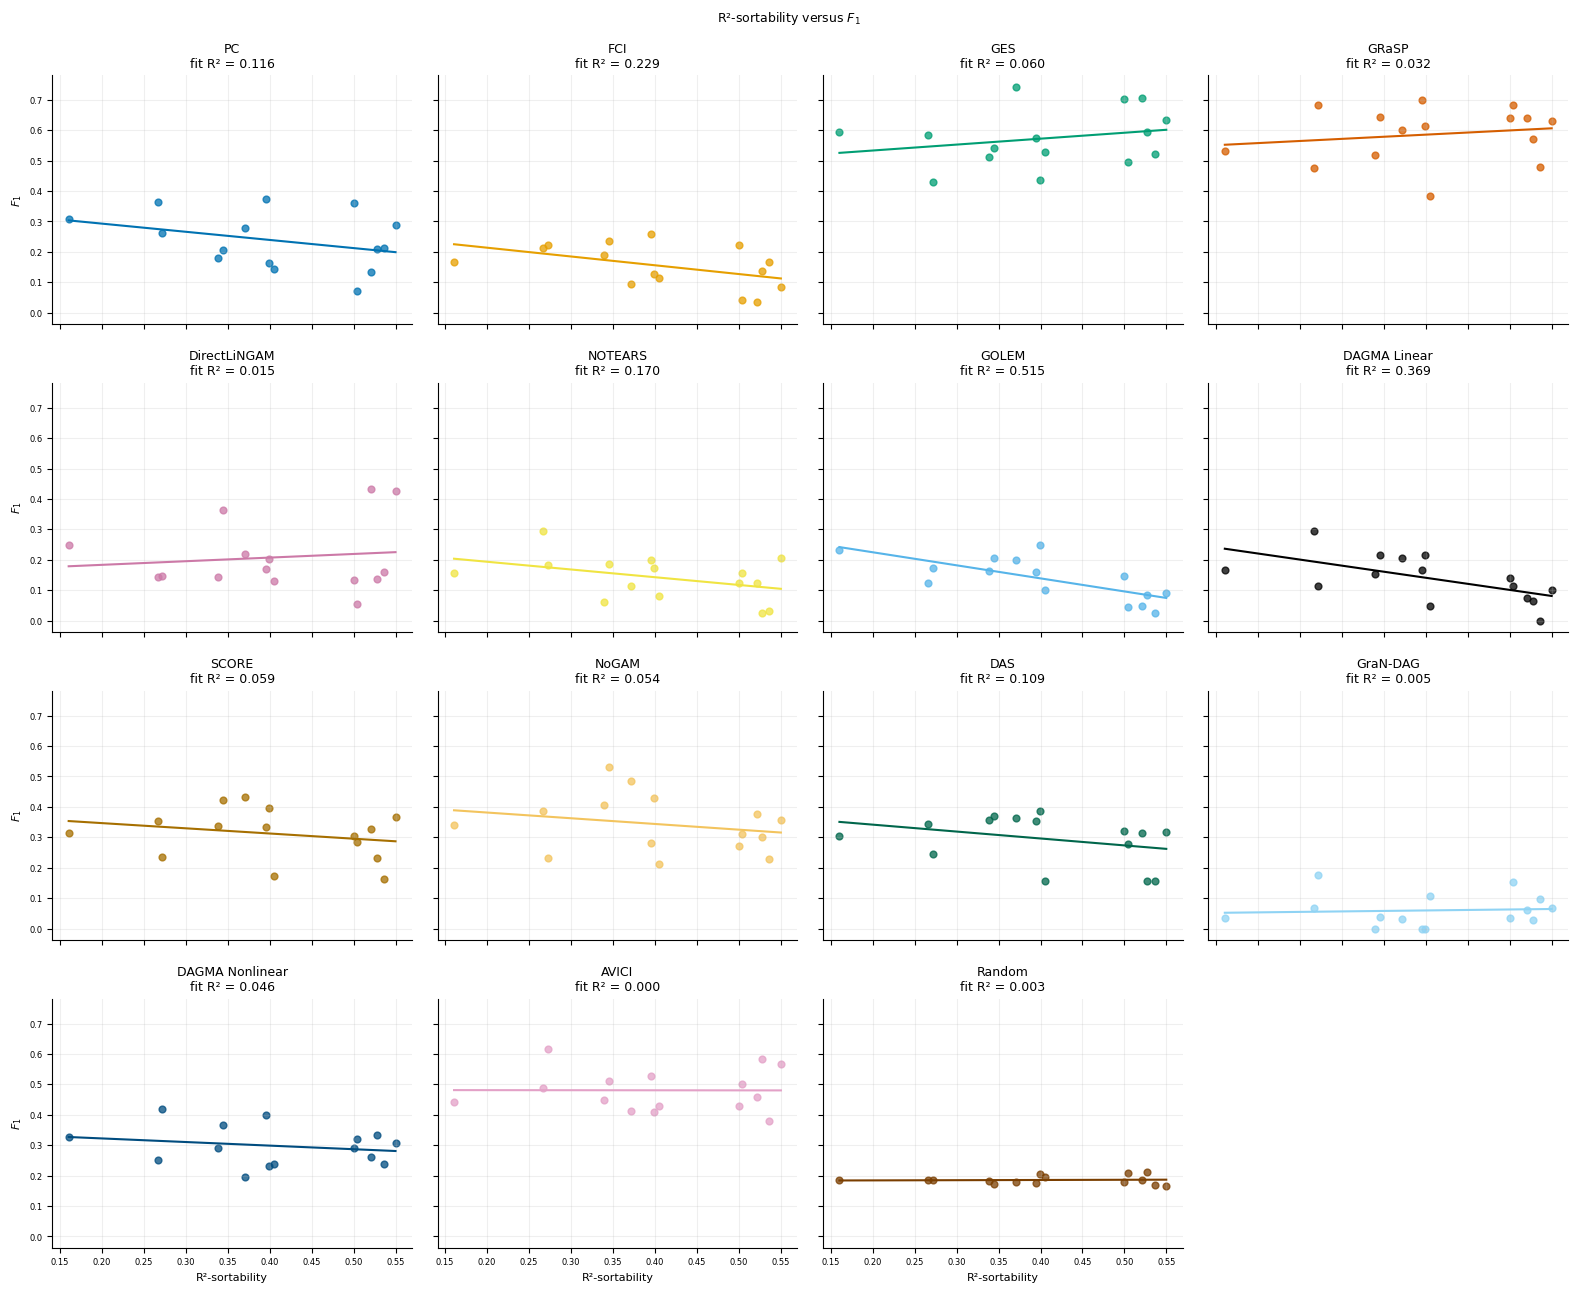

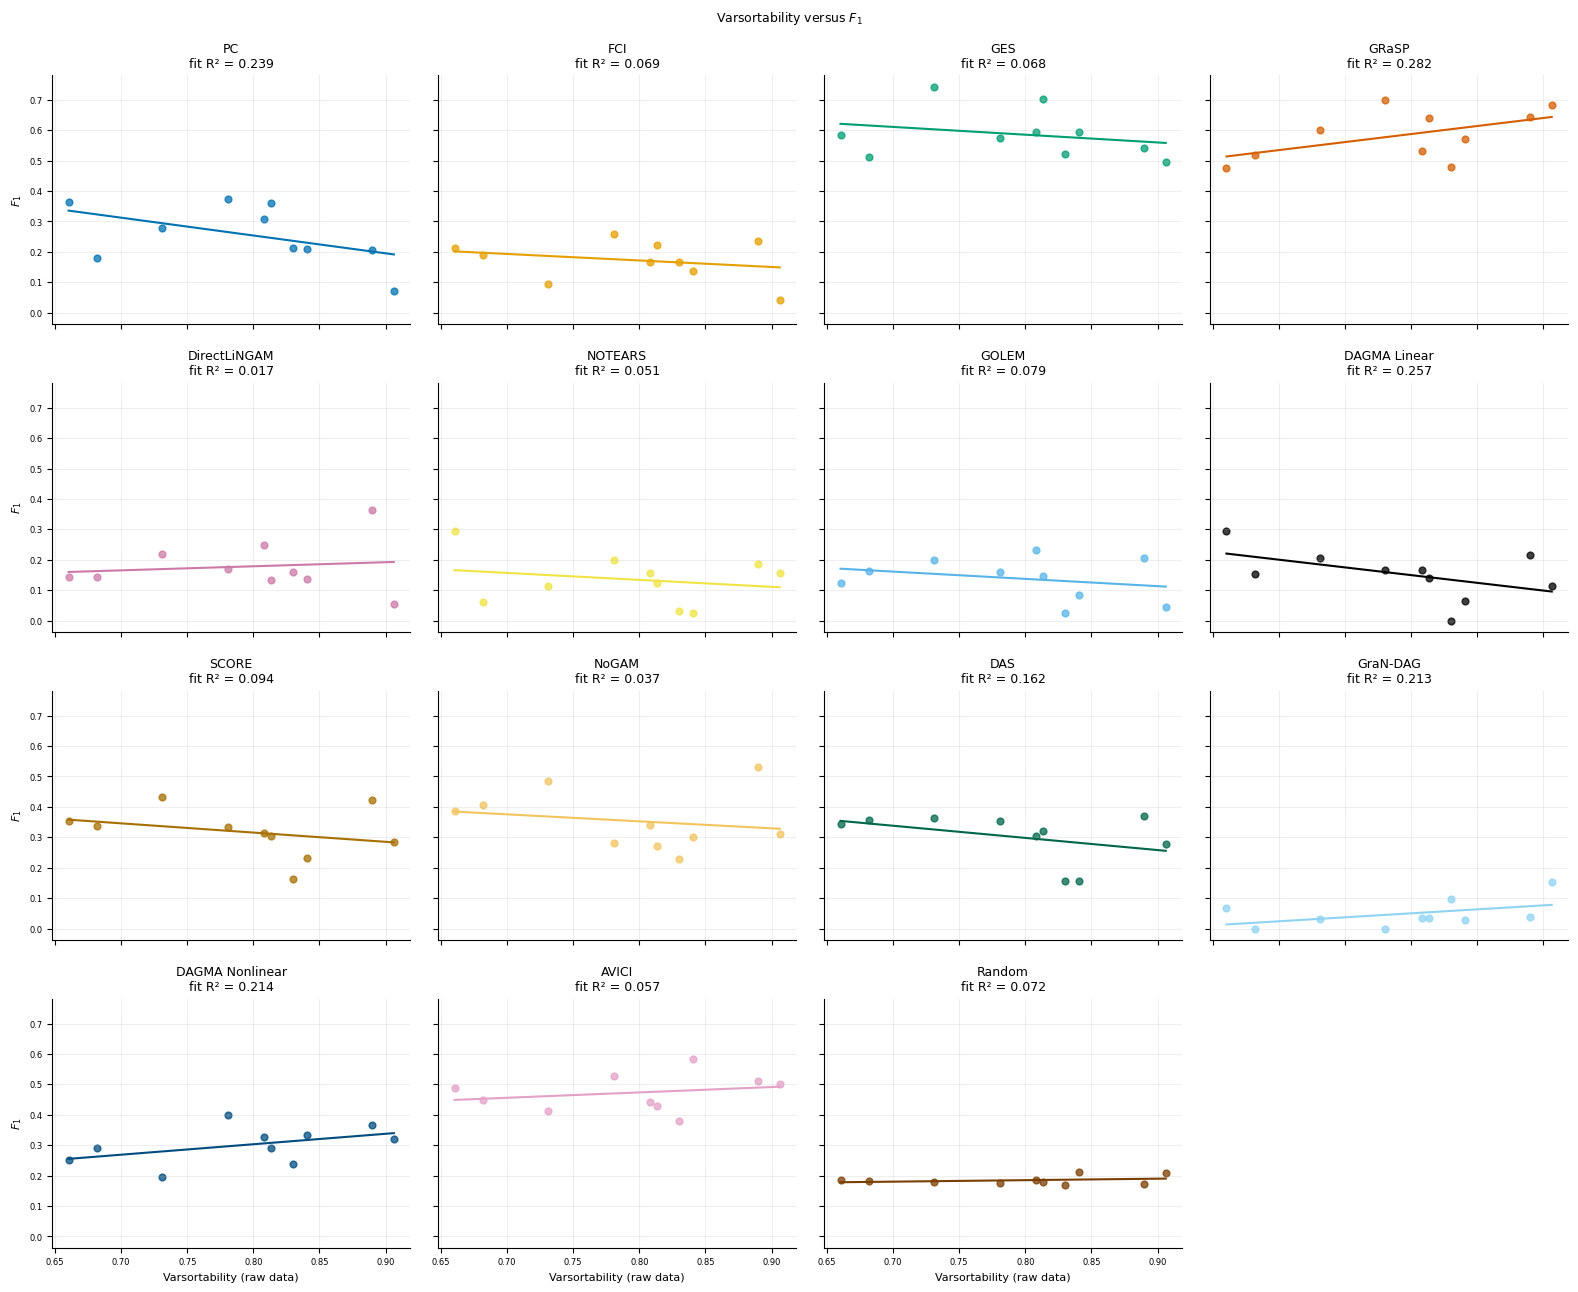

,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
480,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Gaussian_Mixed,AVICI,r2_sortability,15,-0.025000,0.929529,estimated,1.000000
481,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Gaussian_Mixed,AVICI,varsortability,10,0.272727,0.445838,estimated,1.000000
482,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Gaussian_Mixed,DAGMA_Linear,r2_sortability,15,-0.725648,0.002197,estimated,1.000000
483,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Gaussian_Mixed,DAGMA_Linear,varsortability,10,-0.510641,0.131502,estimated,1.000000
484,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Gaussian_Mixed,DAGMA_Nonlinear,r2_sortability,15,-0.178571,0.524284,estimated,1.000000
485,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Gaussian_Mixed,DAGMA_Nonlinear,varsortability,10,0.430303,0.214492,estimated,1.000000
486,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Gaussian_Mixed,DAS,r2_sortability,15,-0.382143,0.159824,estimated,1.000000
487,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Gaussian_Mixed,DAS,varsortability,10,-0.406061,0.244282,estimated,1.000000
488,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Gaussian_Mixed,DirectLiNGAM,r2_sortability,15,-0.021429,0.939578,estimated,1.000000
489,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Gaussian_Mixed,DirectLiNGAM,varsortability,10,-0.163636,0.651477,estimated,1.000000


,model,mean,std,size
0,AVICI,0.472729,0.077122,15
1,DAGMA_Linear,0.107246,0.078030,15
2,DAGMA_Nonlinear,0.275731,0.066922,15
3,DAS,0.209763,0.083171,15
4,DirectLiNGAM,0.198694,0.084622,15
5,FCI,0.131343,0.064557,15
6,GES,0.531893,0.091296,15
7,GOLEM,0.103299,0.067002,15
8,GRaSP,0.470654,0.085475,15
9,GraNDAG,0.045754,0.033599,15


,model,mean,std,size
0,AVICI,44.933333,8.438574,15
1,DAGMA_Linear,58.933333,8.163216,15
2,DAGMA_Nonlinear,51.848889,6.640686,15
3,DAS,71.533333,13.303419,15
4,DirectLiNGAM,77.933333,20.926629,15
5,FCI,53.857778,9.206756,15
6,GES,41.666667,10.997835,15
7,GOLEM,63.133333,10.098562,15
8,GRaSP,42.182222,7.921058,15
9,GraNDAG,56.400000,6.173677,15


,model,mean,std,size
0,AVICI,0.723965,0.137357,15
1,DAGMA_Linear,0.199129,0.126130,15
2,DAGMA_Nonlinear,0.501539,0.106505,15
3,DAS,0.217578,0.087810,15
4,DirectLiNGAM,0.192859,0.087095,15
5,FCI,0.811397,0.273622,15
6,GES,0.671341,0.168710,15
7,GOLEM,0.171592,0.106492,15
8,GRaSP,0.762938,0.130779,15
9,GraNDAG,0.332835,0.253470,15


,model,mean,std,size
0,AVICI,0.361802,0.085278,15
1,DAGMA_Linear,0.074675,0.057119,15
2,DAGMA_Nonlinear,0.194854,0.058376,15
3,DAS,0.205476,0.083107,15
4,DirectLiNGAM,0.208779,0.084146,15
5,FCI,0.072774,0.039218,15
6,GES,0.448462,0.071099,15
7,GOLEM,0.075610,0.051307,15
8,GRaSP,0.345004,0.073980,15
9,GraNDAG,0.025152,0.019069,15


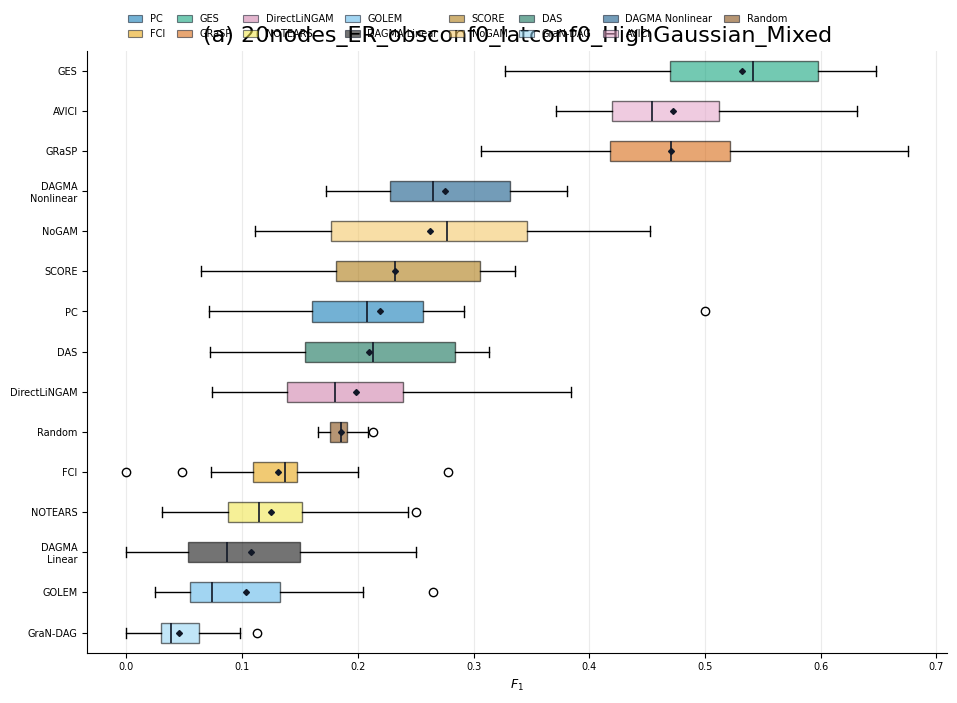

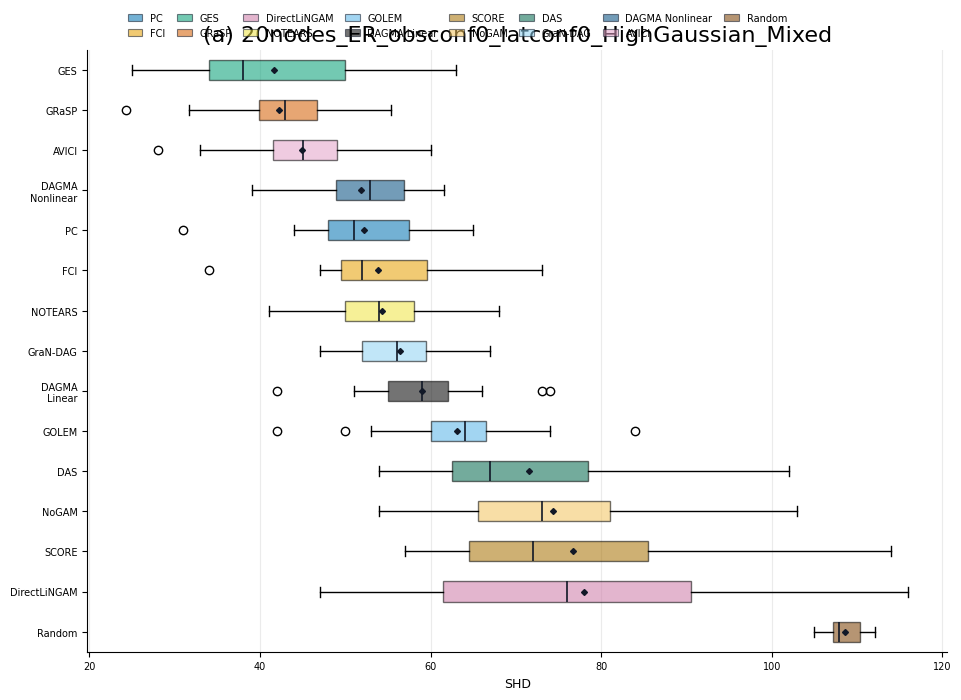

,dataset_seed,model,f1_range
0,11,AVICI,0.000000
1,11,DAGMA_Linear,0.000000
2,11,DAGMA_Nonlinear,0.198830
3,11,DAS,0.000000
4,11,DirectLiNGAM,0.000000
5,11,FCI,0.000000
6,11,GES,0.000000
7,11,GOLEM,0.000000
8,11,GRaSP,0.049398
9,11,GraNDAG,0.000000


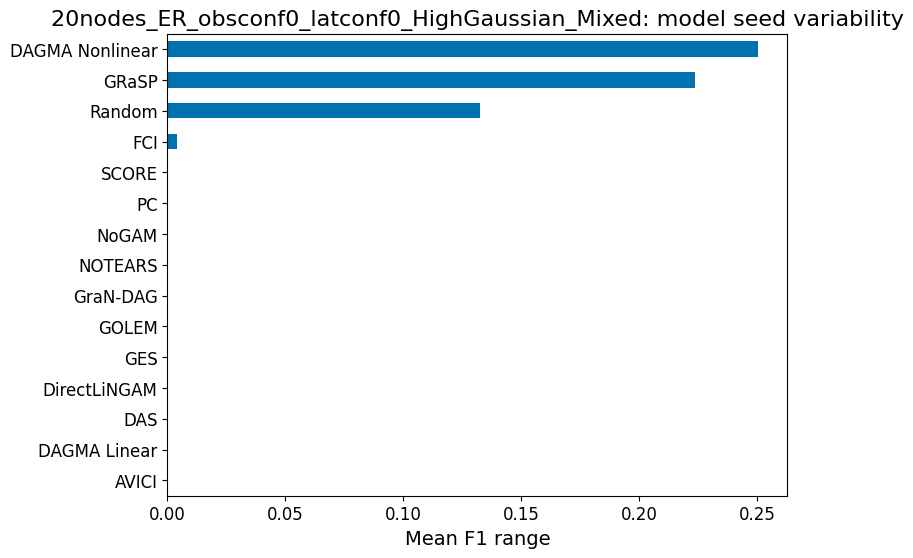

,model_seed,model,f1_range
0,0,AVICI,0.260150
1,0,DAGMA_Linear,0.250000
2,0,DAGMA_Nonlinear,0.397833
3,0,DAS,0.241101
4,0,DirectLiNGAM,0.310996
5,0,FCI,0.277778
6,0,GES,0.320301
7,0,GOLEM,0.240316
8,0,GRaSP,0.446702
9,0,GraNDAG,0.112676


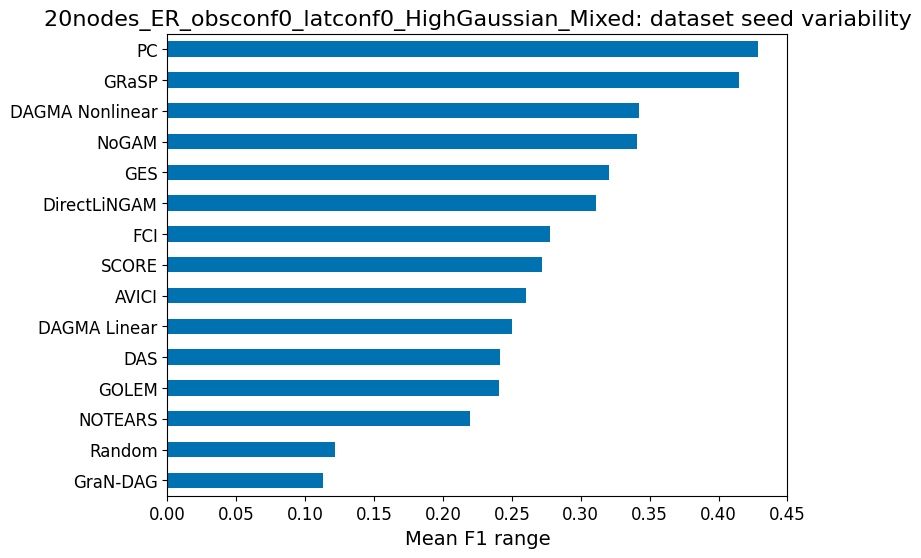

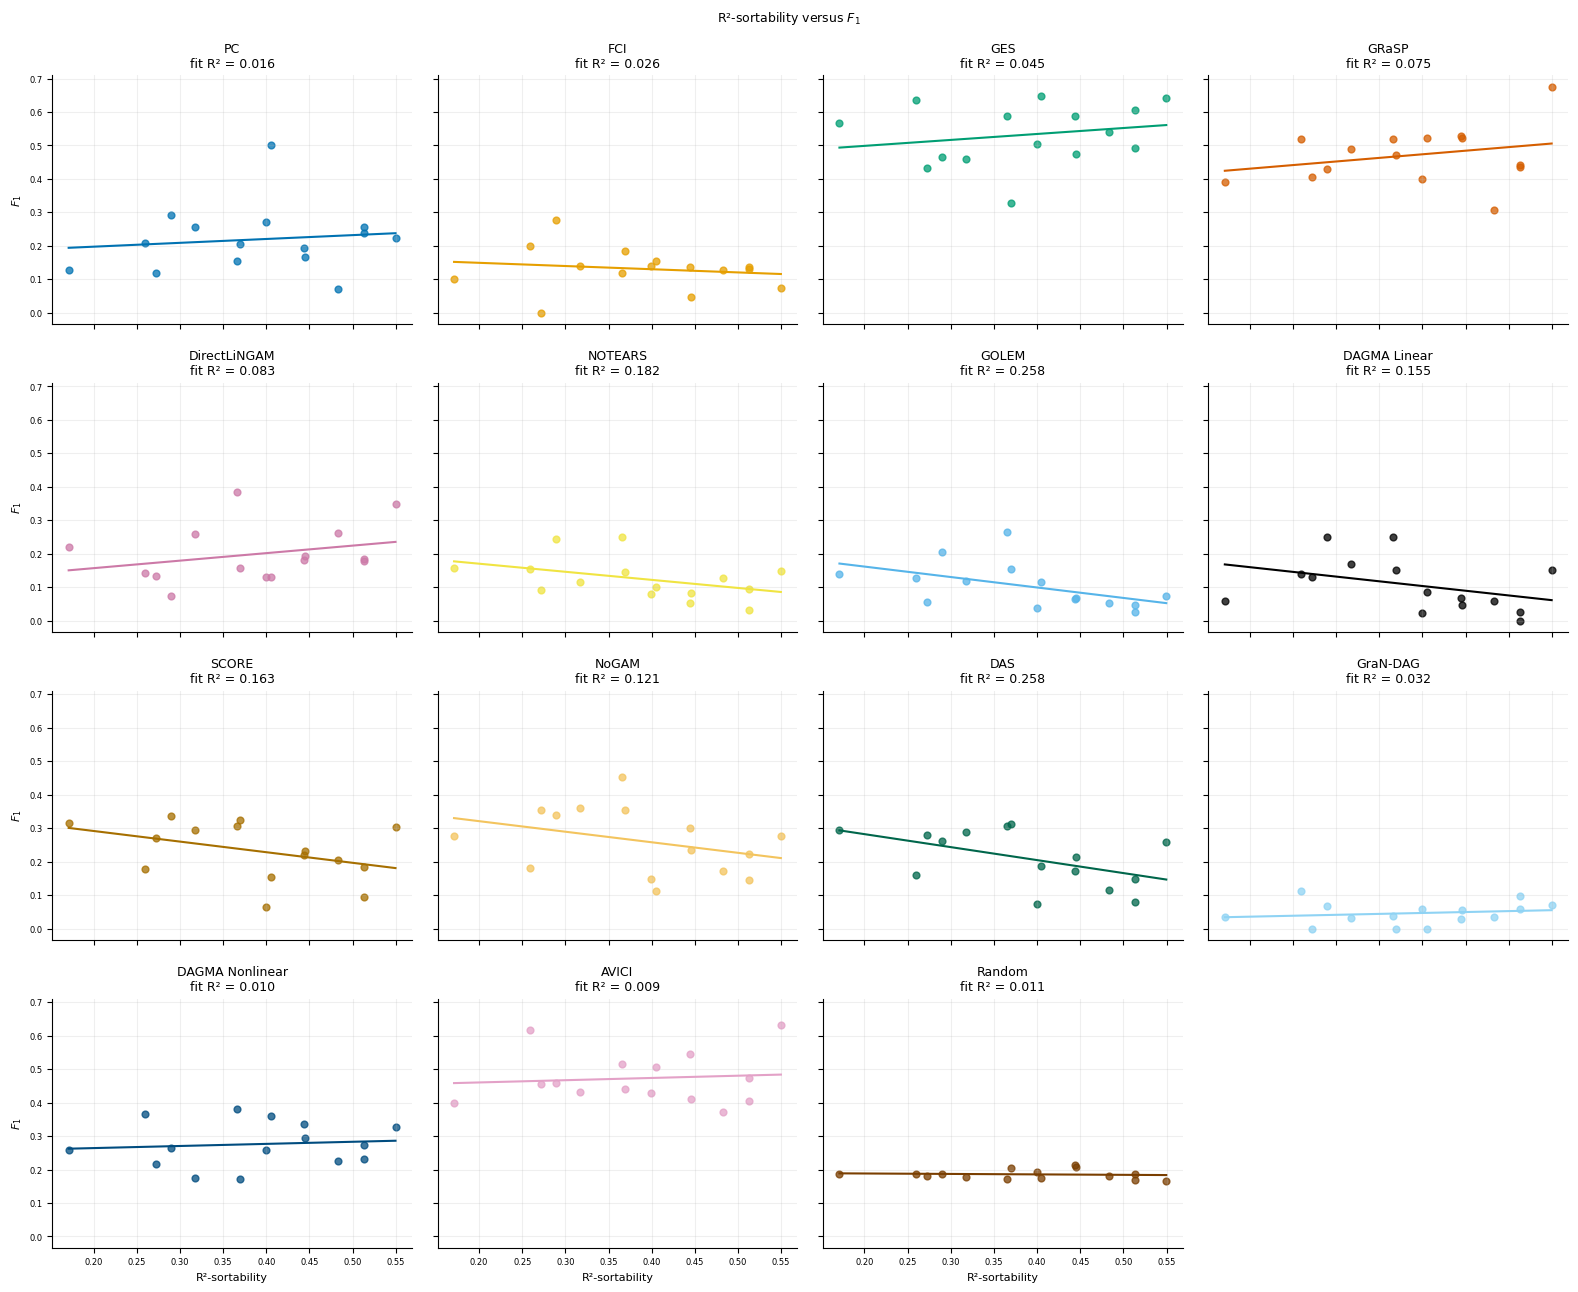

,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
510,benchmark,untuned,20nodes_ER_obsconf0_latconf0_HighGaussian_Mixed,AVICI,r2_sortability,15,0.023235,0.934494,estimated,1.0
511,benchmark,untuned,20nodes_ER_obsconf0_latconf0_HighGaussian_Mixed,DAGMA_Linear,r2_sortability,15,-0.418980,0.120073,estimated,1.0
512,benchmark,untuned,20nodes_ER_obsconf0_latconf0_HighGaussian_Mixed,DAGMA_Nonlinear,r2_sortability,15,0.096515,0.732222,estimated,1.0
513,benchmark,untuned,20nodes_ER_obsconf0_latconf0_HighGaussian_Mixed,DAS,r2_sortability,15,-0.514746,0.049600,estimated,1.0
514,benchmark,untuned,20nodes_ER_obsconf0_latconf0_HighGaussian_Mixed,DirectLiNGAM,r2_sortability,15,0.296694,0.282905,estimated,1.0
515,benchmark,untuned,20nodes_ER_obsconf0_latconf0_HighGaussian_Mixed,FCI,r2_sortability,15,-0.235925,0.397269,estimated,1.0
516,benchmark,untuned,20nodes_ER_obsconf0_latconf0_HighGaussian_Mixed,GES,r2_sortability,15,0.300268,0.276866,estimated,1.0
517,benchmark,untuned,20nodes_ER_obsconf0_latconf0_HighGaussian_Mixed,GOLEM,r2_sortability,15,-0.600536,0.017920,estimated,1.0
518,benchmark,untuned,20nodes_ER_obsconf0_latconf0_HighGaussian_Mixed,GRaSP,r2_sortability,15,0.309205,0.262112,estimated,1.0
519,benchmark,untuned,20nodes_ER_obsconf0_latconf0_HighGaussian_Mixed,GraNDAG,r2_sortability,15,0.213454,0.444956,estimated,1.0


,model,mean,std,size
0,AVICI,0.482147,0.094122,15
1,DAGMA_Linear,0.179834,0.062507,15
2,DAGMA_Nonlinear,0.127936,0.065787,15
3,DAS,0.132329,0.078659,15
4,DirectLiNGAM,0.998338,0.003452,15
5,FCI,0.079064,0.064368,15
6,GES,0.444371,0.152219,15
7,GOLEM,0.150278,0.090959,15
8,GRaSP,0.755768,0.114259,15
9,GraNDAG,0.055841,0.045595,15


,model,mean,std,size
0,AVICI,53.133333,10.802557,15
1,DAGMA_Linear,61.533333,7.558029,15
2,DAGMA_Nonlinear,70.022222,10.394616,15
3,DAS,100.866667,16.012793,15
4,DirectLiNGAM,0.200000,0.414039,15
5,FCI,62.591111,7.203388,15
6,GES,80.266667,27.112113,15
7,GOLEM,84.400000,13.473784,15
8,GRaSP,28.404444,15.397598,15
9,GraNDAG,57.000000,6.425396,15


,model,mean,std,size
0,AVICI,0.520888,0.086642,15
1,DAGMA_Linear,0.254303,0.093185,15
2,DAGMA_Nonlinear,0.168495,0.097562,15
3,DAS,0.108627,0.068075,15
4,DirectLiNGAM,0.996703,0.006847,15
5,FCI,0.474286,0.325010,15
6,GES,0.351642,0.155224,15
7,GOLEM,0.140473,0.084687,15
8,GRaSP,0.742714,0.136278,15
9,GraNDAG,0.327340,0.240293,15


,model,mean,std,size
0,AVICI,0.458163,0.115946,15
1,DAGMA_Linear,0.140966,0.050466,15
2,DAGMA_Nonlinear,0.107426,0.053205,15
3,DAS,0.171941,0.096568,15
4,DirectLiNGAM,1.000000,0.000000,15
5,FCI,0.044149,0.037910,15
6,GES,0.620301,0.137388,15
7,GOLEM,0.162620,0.099699,15
8,GRaSP,0.781451,0.092455,15
9,GraNDAG,0.031899,0.027870,15


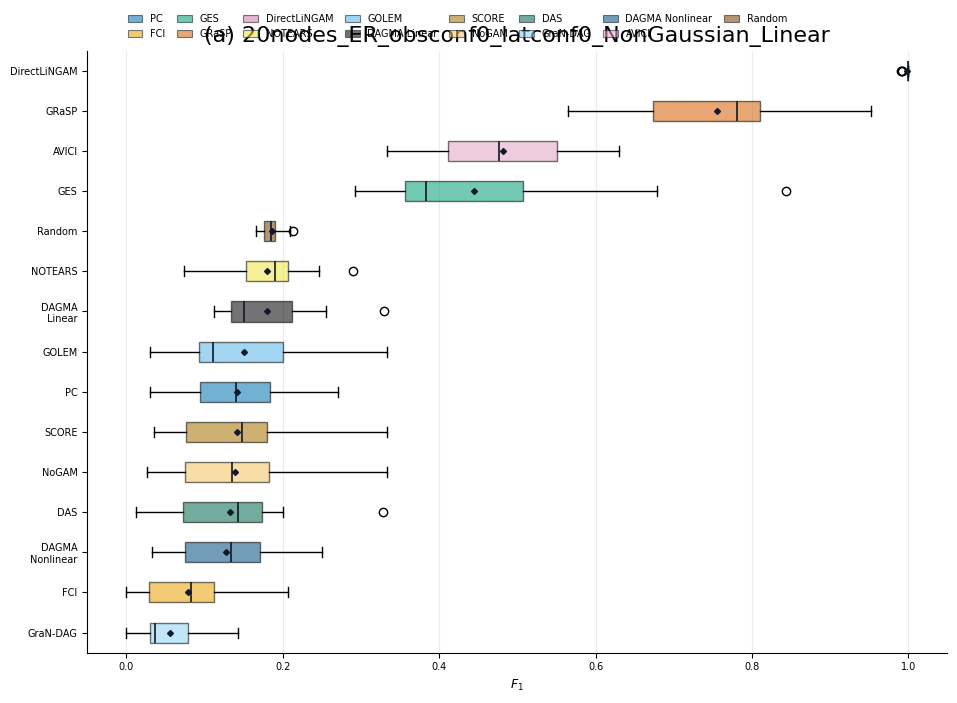

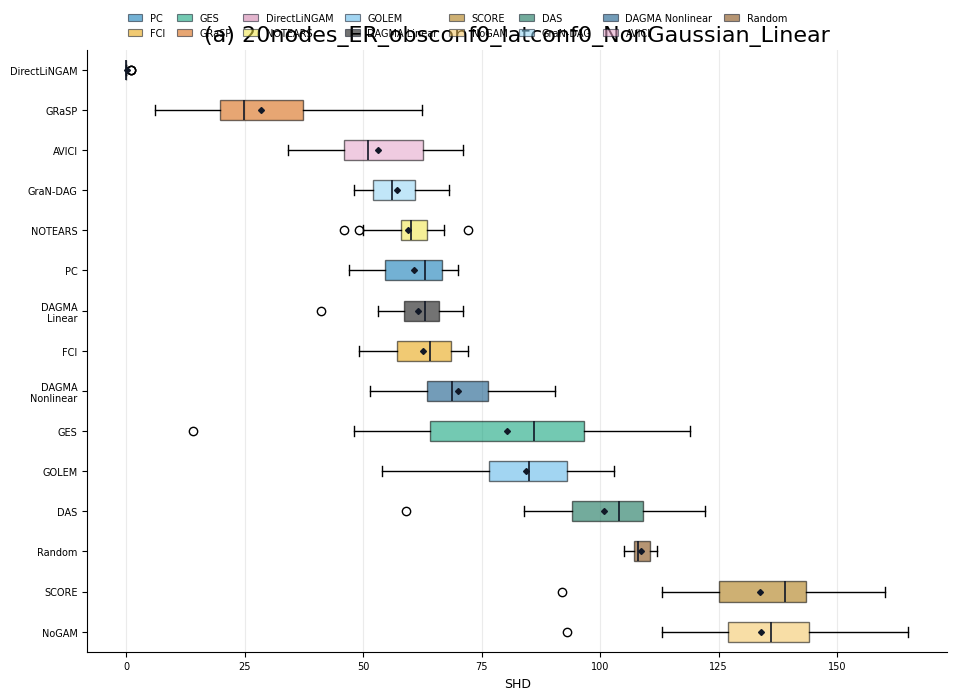

,dataset_seed,model,f1_range
0,11,AVICI,0.000000
1,11,DAGMA_Linear,0.000000
2,11,DAGMA_Nonlinear,0.168217
3,11,DAS,0.000000
4,11,DirectLiNGAM,0.000000
5,11,FCI,0.000000
6,11,GES,0.000000
7,11,GOLEM,0.000000
8,11,GRaSP,0.712608
9,11,GraNDAG,0.000000


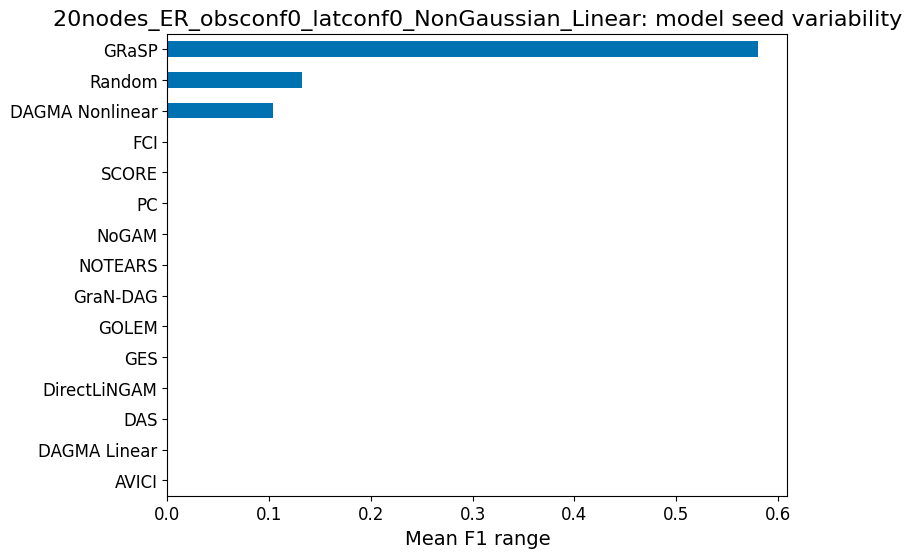

,model_seed,model,f1_range
0,0,AVICI,0.297297
1,0,DAGMA_Linear,0.216754
2,0,DAGMA_Nonlinear,0.282593
3,0,DAS,0.315681
4,0,DirectLiNGAM,0.009009
5,0,FCI,0.206897
6,0,GES,0.550208
7,0,GOLEM,0.302799
8,0,GRaSP,0.743590
9,0,GraNDAG,0.142857


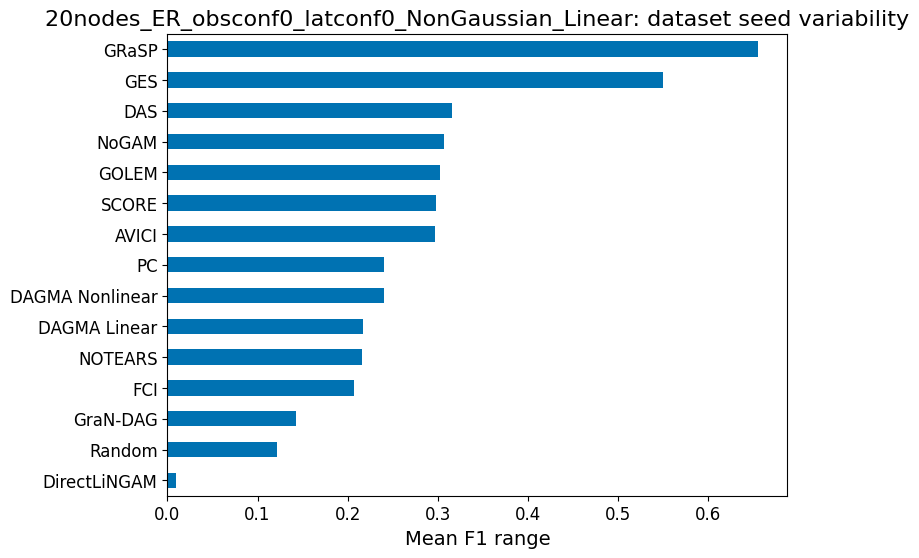

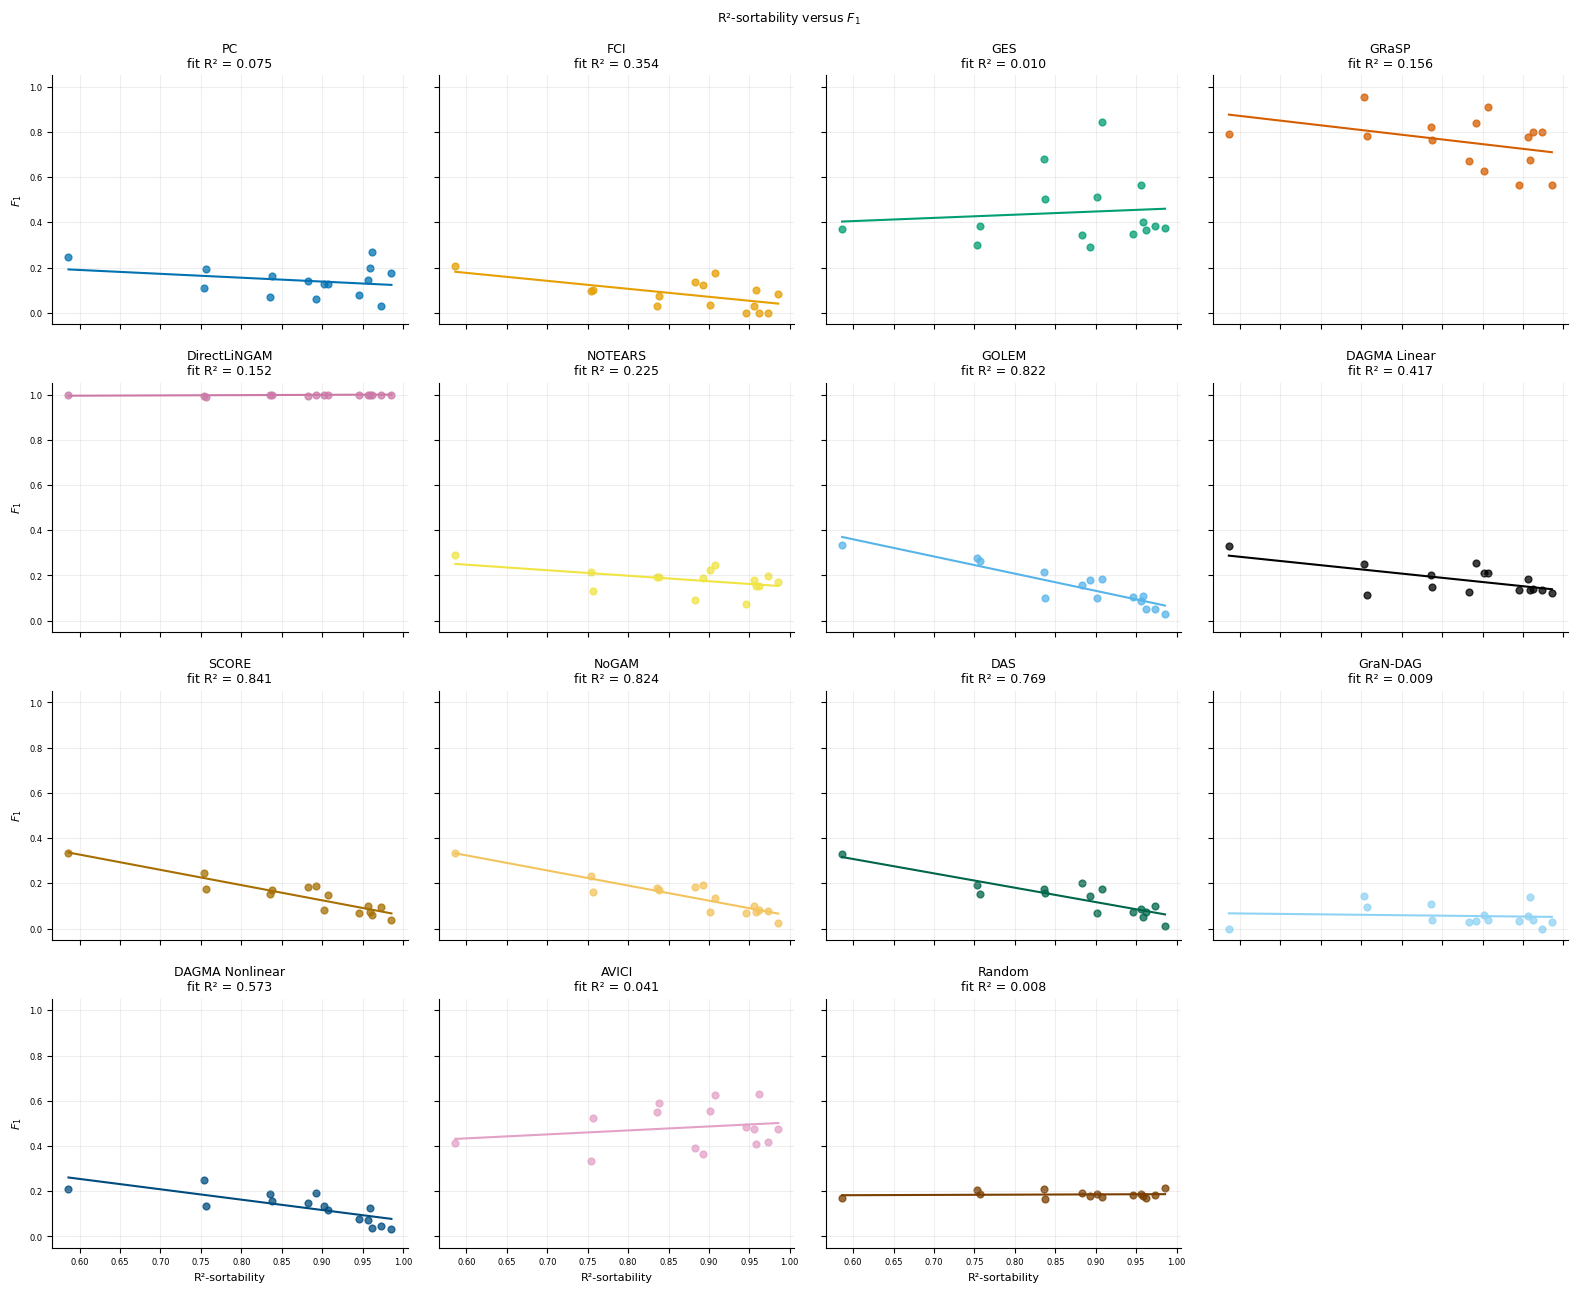

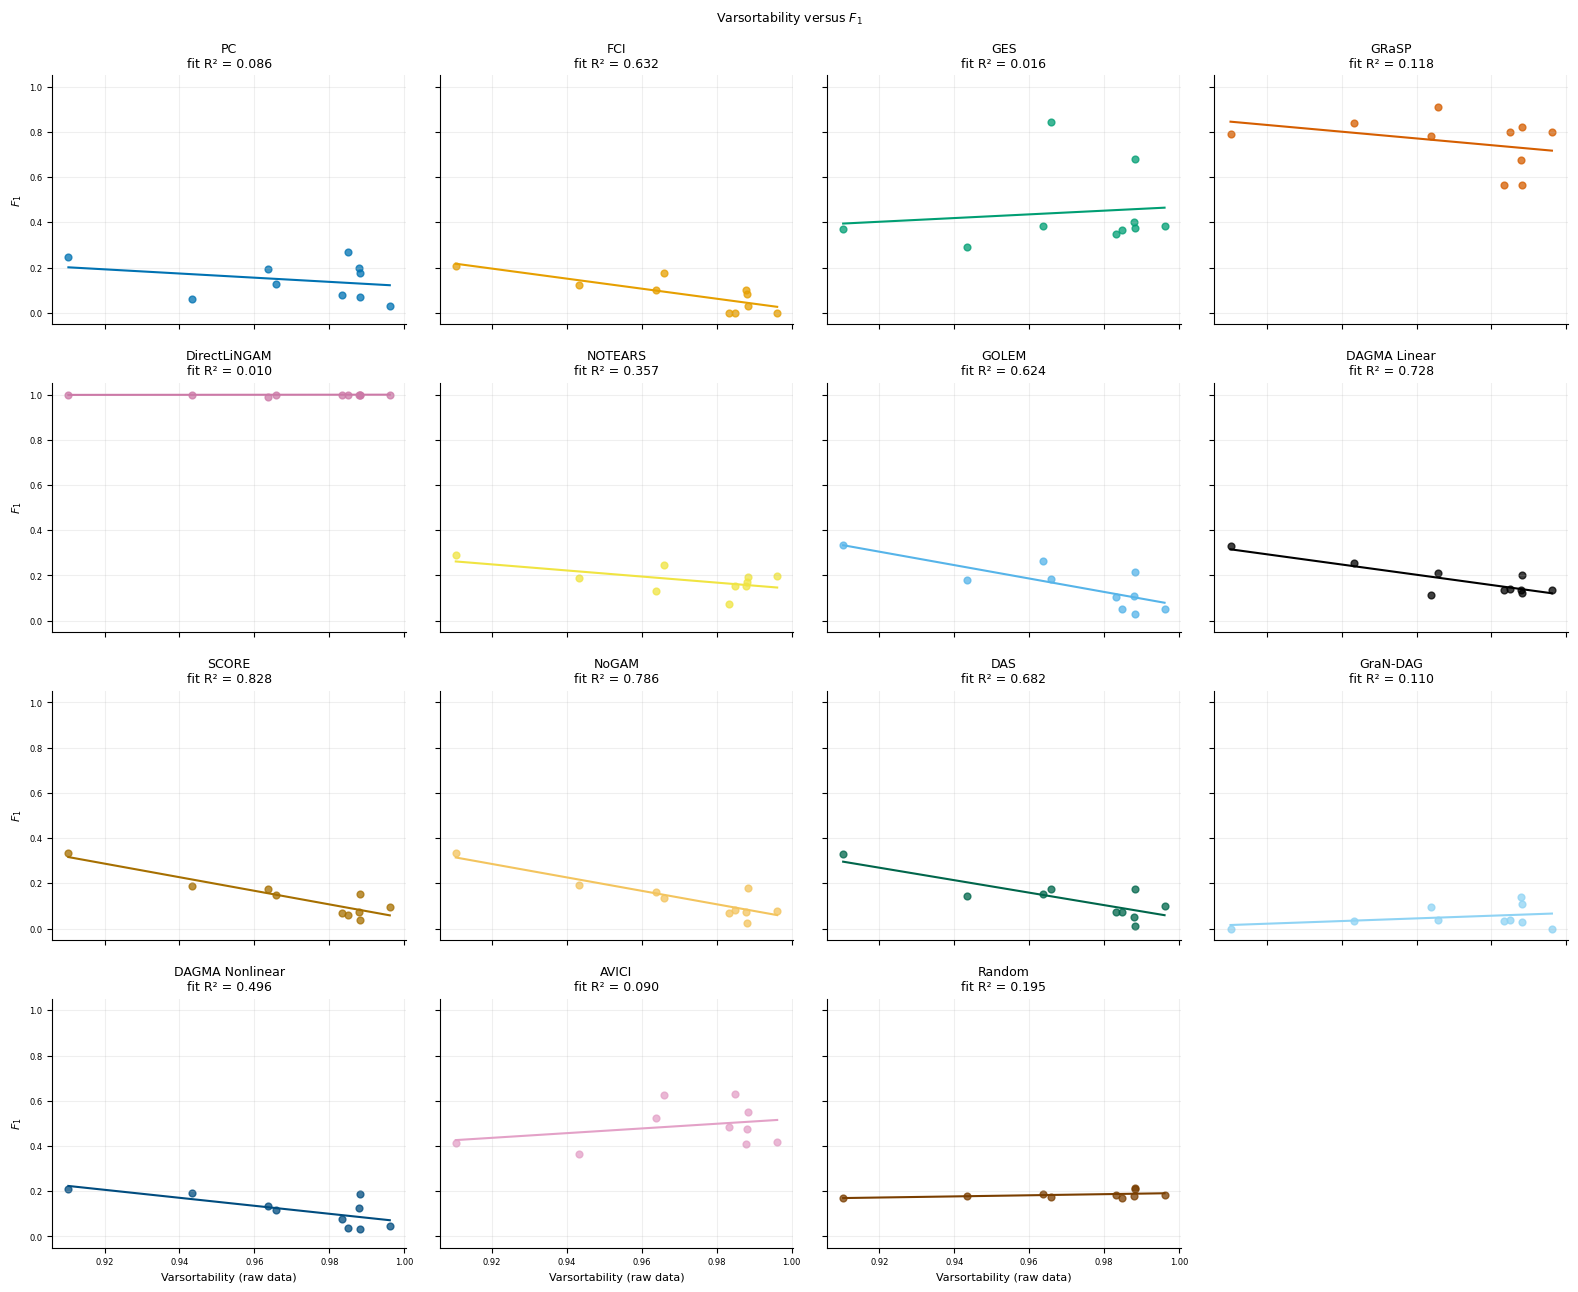

,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
525,benchmark,untuned,20nodes_ER_obsconf0_latconf0_NonGaussian_Linear,AVICI,r2_sortability,15,0.192857,0.491049,estimated,1.000000
526,benchmark,untuned,20nodes_ER_obsconf0_latconf0_NonGaussian_Linear,AVICI,varsortability,10,0.187879,0.603218,estimated,1.000000
527,benchmark,untuned,20nodes_ER_obsconf0_latconf0_NonGaussian_Linear,DAGMA_Linear,r2_sortability,15,-0.437891,0.102576,estimated,1.000000
528,benchmark,untuned,20nodes_ER_obsconf0_latconf0_NonGaussian_Linear,DAGMA_Linear,varsortability,10,-0.406061,0.244282,estimated,1.000000
529,benchmark,untuned,20nodes_ER_obsconf0_latconf0_NonGaussian_Linear,DAGMA_Nonlinear,r2_sortability,15,-0.896429,0.000006,estimated,0.003082
530,benchmark,untuned,20nodes_ER_obsconf0_latconf0_NonGaussian_Linear,DAGMA_Nonlinear,varsortability,10,-0.600000,0.066688,estimated,1.000000
531,benchmark,untuned,20nodes_ER_obsconf0_latconf0_NonGaussian_Linear,DAS,r2_sortability,15,-0.778571,0.000627,estimated,0.302383
532,benchmark,untuned,20nodes_ER_obsconf0_latconf0_NonGaussian_Linear,DAS,varsortability,10,-0.490909,0.149656,estimated,1.000000
533,benchmark,untuned,20nodes_ER_obsconf0_latconf0_NonGaussian_Linear,DirectLiNGAM,r2_sortability,15,0.513129,0.050444,estimated,1.000000
534,benchmark,untuned,20nodes_ER_obsconf0_latconf0_NonGaussian_Linear,DirectLiNGAM,varsortability,10,0.290129,0.416120,estimated,1.000000


,model,mean,std,size
0,AVICI,0.503411,0.042953,15
1,DAGMA_Linear,0.162224,0.063044,15
2,DAGMA_Nonlinear,0.331233,0.046755,15
3,DAS,0.303369,0.060568,15
4,DirectLiNGAM,0.375042,0.092327,15
5,FCI,0.164927,0.065919,15
6,GES,0.536679,0.149021,15
7,GOLEM,0.150139,0.062971,15
8,GRaSP,0.604832,0.095018,15
9,GraNDAG,0.061739,0.041395,15


,model,mean,std,size
0,AVICI,49.066667,10.996536,15
1,DAGMA_Linear,59.400000,8.449852,15
2,DAGMA_Nonlinear,52.213333,7.236512,15
3,DAS,73.200000,12.048711,15
4,DirectLiNGAM,68.333333,18.733723,15
5,FCI,54.262222,10.045214,15
6,GES,46.600000,17.087171,15
7,GOLEM,68.000000,11.850256,15
8,GRaSP,35.702222,9.969027,15
9,GraNDAG,55.933333,6.134989,15


,model,mean,std,size
0,AVICI,0.602429,0.104114,15
1,DAGMA_Linear,0.262201,0.117554,15
2,DAGMA_Nonlinear,0.450869,0.067551,15
3,DAS,0.277402,0.056788,15
4,DirectLiNGAM,0.336051,0.104202,15
5,FCI,0.834391,0.162682,15
6,GES,0.556505,0.178282,15
7,GOLEM,0.198536,0.079336,15
8,GRaSP,0.759608,0.116931,15
9,GraNDAG,0.547302,0.340484,15


,model,mean,std,size
0,AVICI,0.446927,0.071804,15
1,DAGMA_Linear,0.119508,0.045762,15
2,DAGMA_Nonlinear,0.264864,0.043560,15
3,DAS,0.337132,0.071990,15
4,DirectLiNGAM,0.434753,0.086552,15
5,FCI,0.092718,0.040590,15
6,GES,0.526702,0.140411,15
7,GOLEM,0.126996,0.062061,15
8,GRaSP,0.507916,0.091772,15
9,GraNDAG,0.033621,0.023215,15


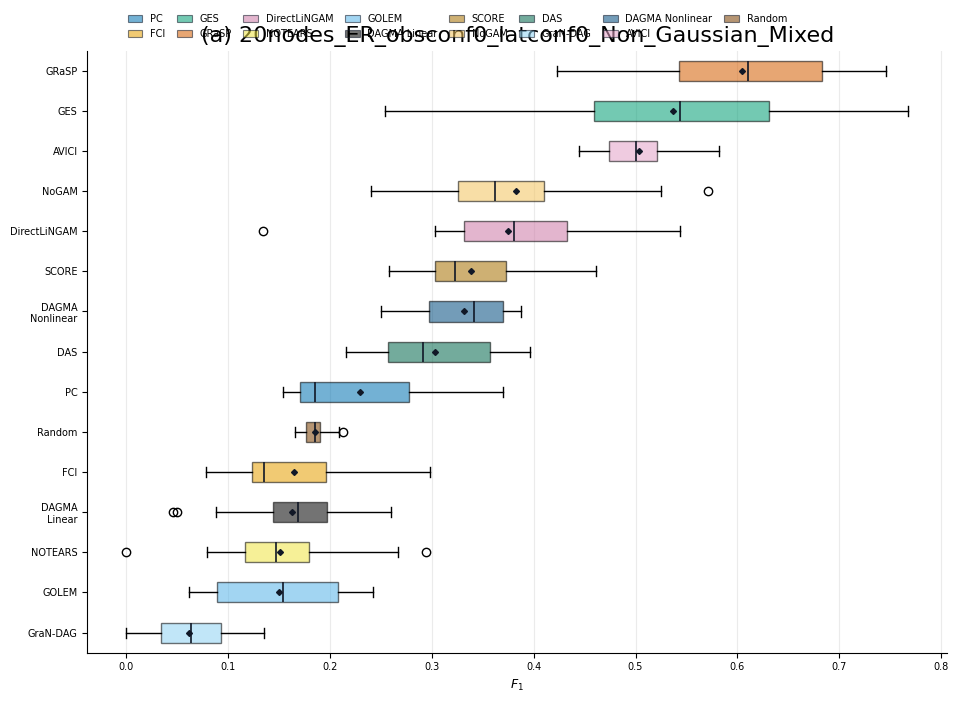

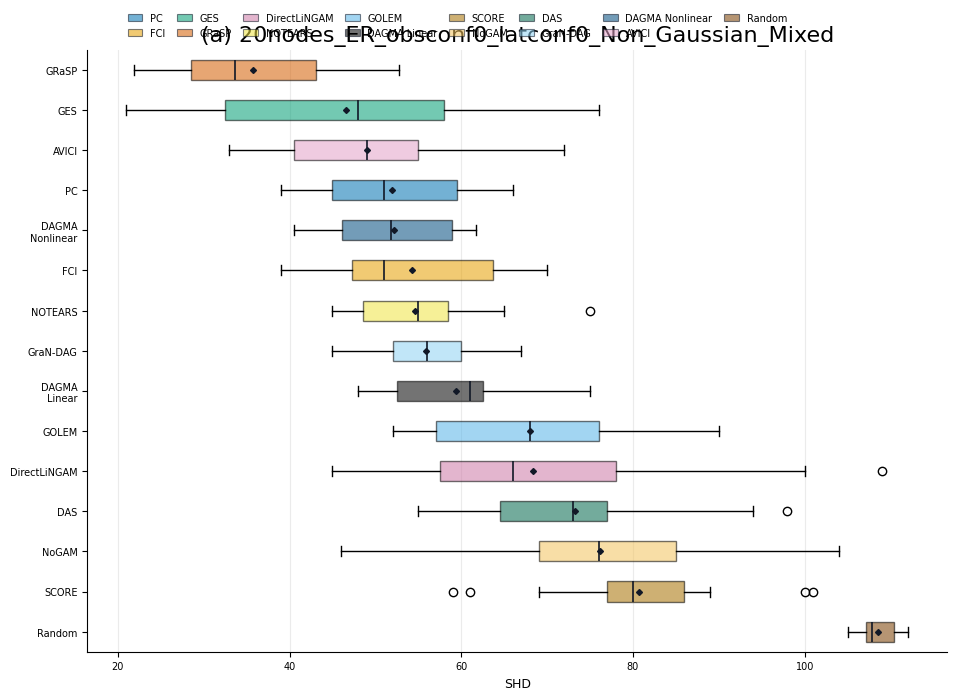

,dataset_seed,model,f1_range
0,11,AVICI,0.000000
1,11,DAGMA_Linear,0.000000
2,11,DAGMA_Nonlinear,0.203463
3,11,DAS,0.000000
4,11,DirectLiNGAM,0.000000
5,11,FCI,0.000000
6,11,GES,0.000000
7,11,GOLEM,0.000000
8,11,GRaSP,0.120716
9,11,GraNDAG,0.000000


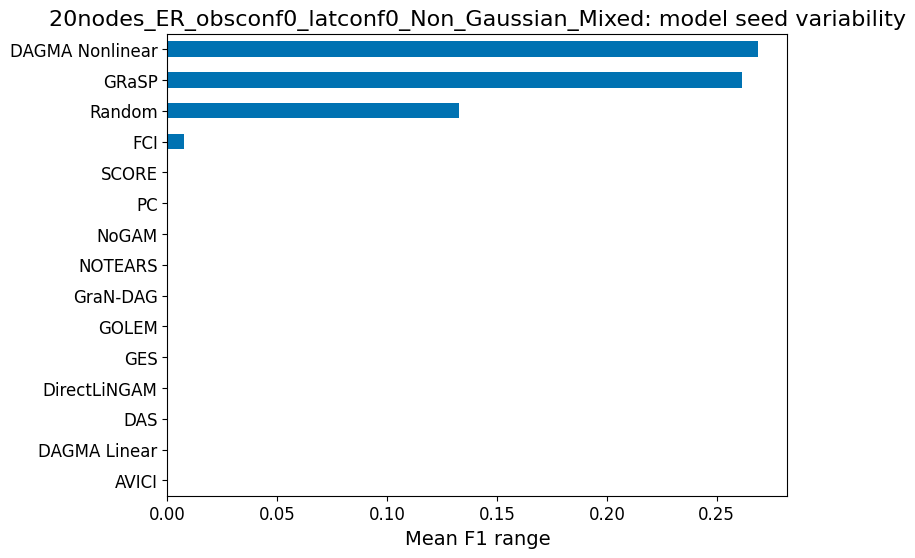

,model_seed,model,f1_range
0,0,AVICI,0.137834
1,0,DAGMA_Linear,0.213763
2,0,DAGMA_Nonlinear,0.255747
3,0,DAS,0.181636
4,0,DirectLiNGAM,0.409713
5,0,FCI,0.220076
6,0,GES,0.513889
7,0,GOLEM,0.180569
8,0,GRaSP,0.429553
9,0,GraNDAG,0.135135


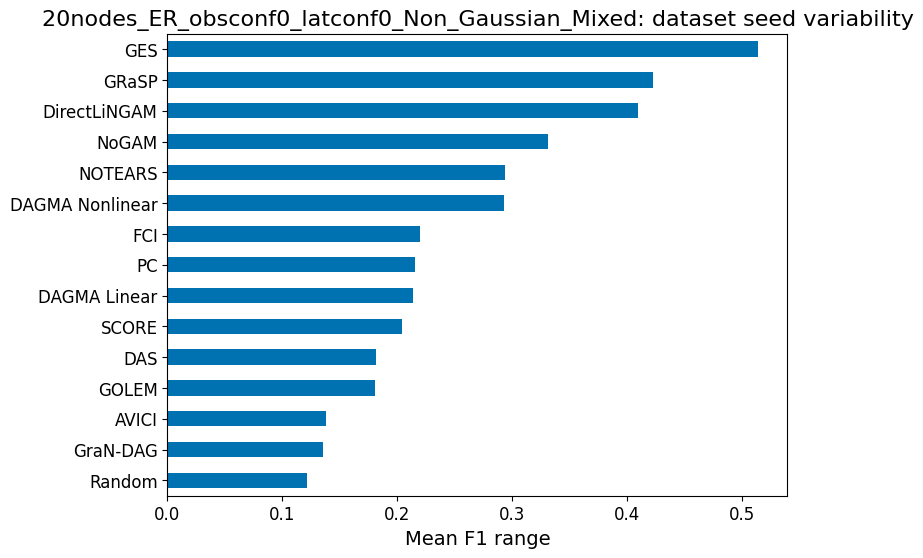

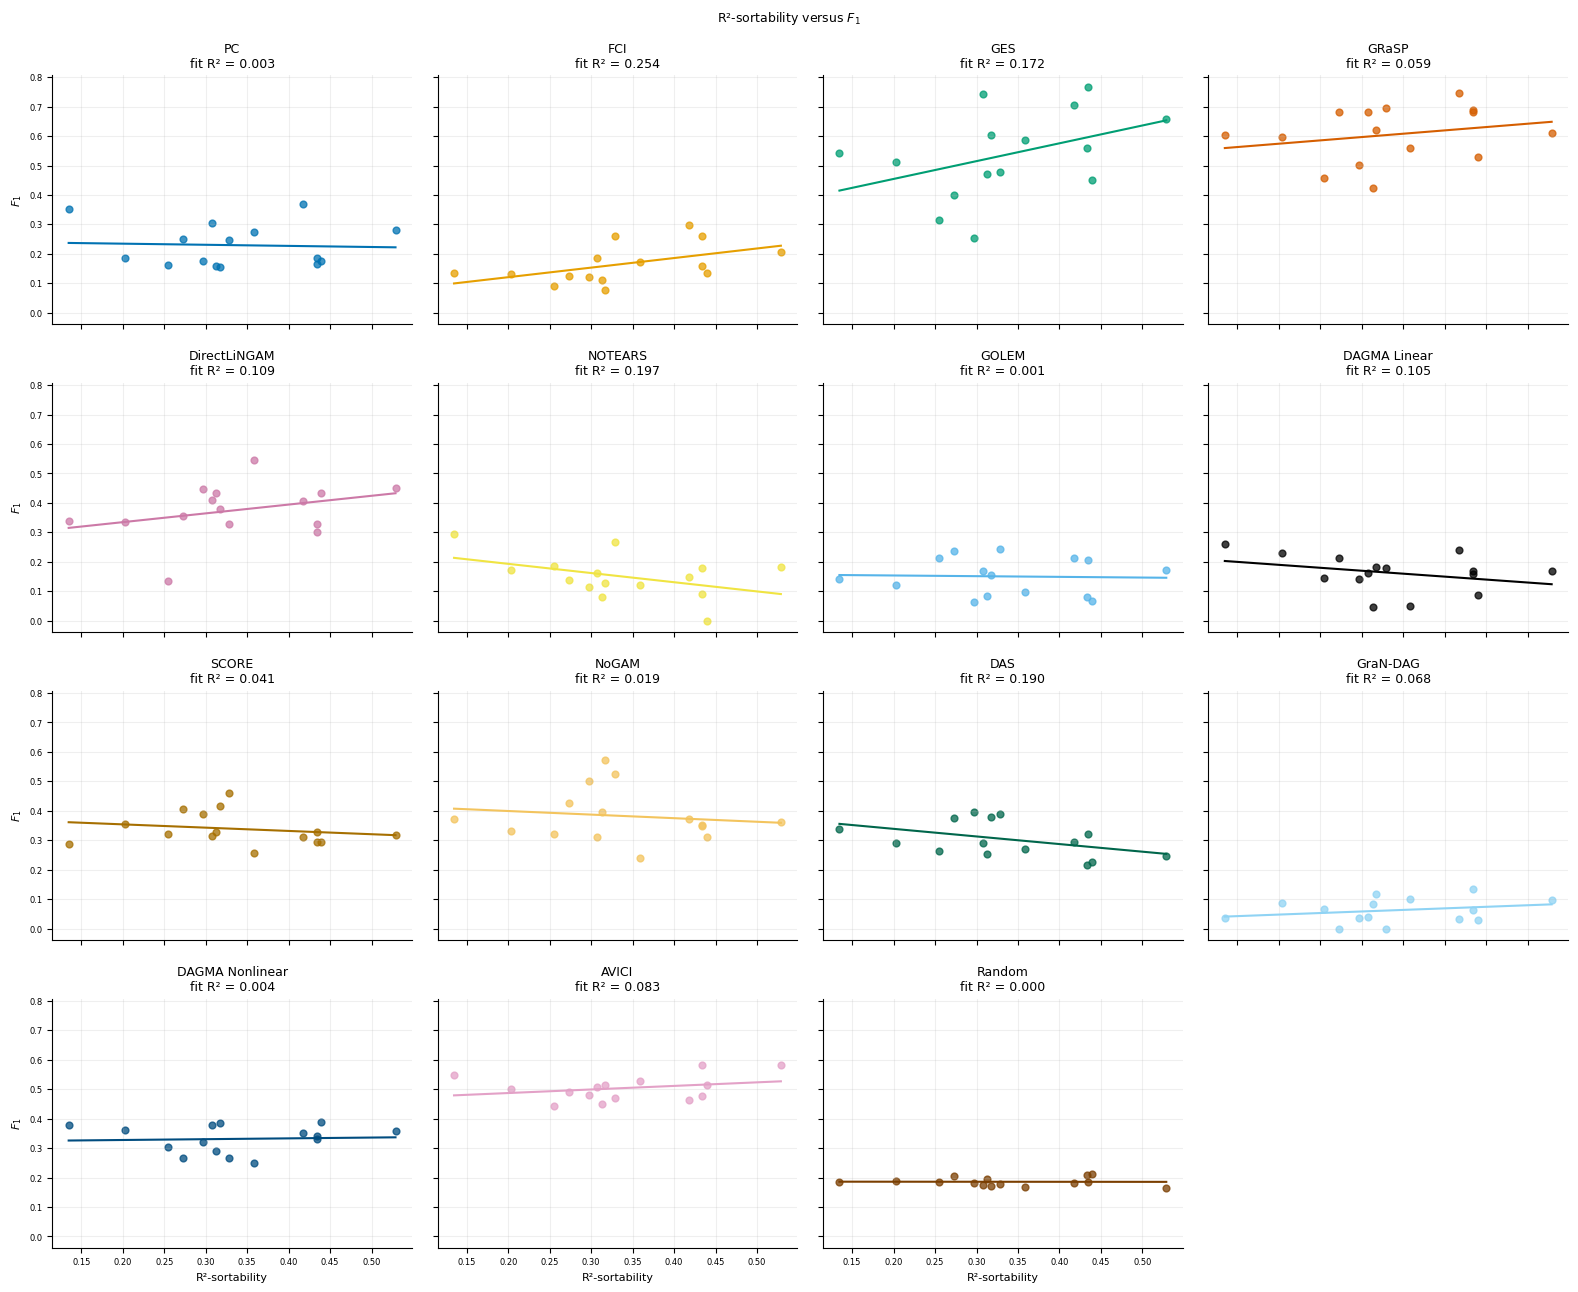

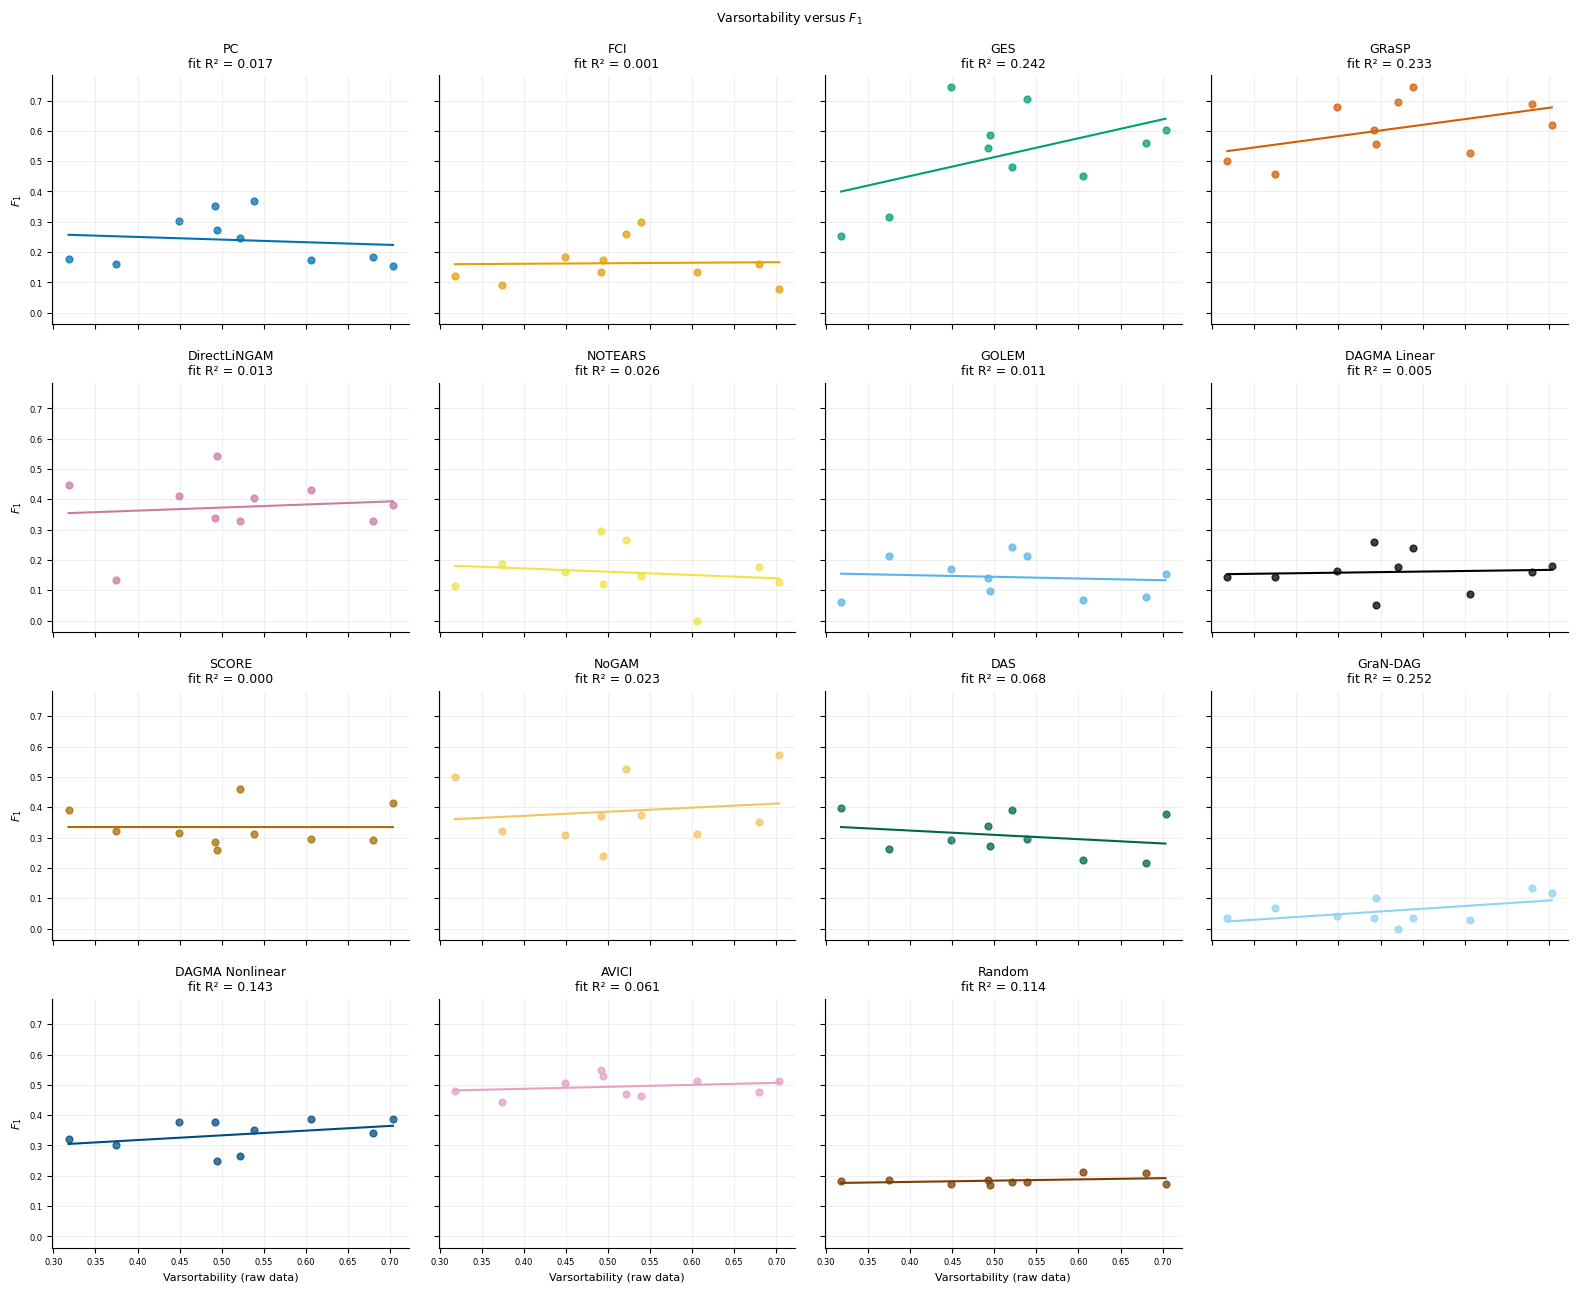

,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
555,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Non_Gaussian_Mixed,AVICI,r2_sortability,15,0.314286,0.253940,estimated,1.0
556,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Non_Gaussian_Mixed,AVICI,varsortability,10,0.115152,0.751420,estimated,1.0
557,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Non_Gaussian_Mixed,DAGMA_Linear,r2_sortability,15,-0.292857,0.289472,estimated,1.0
558,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Non_Gaussian_Mixed,DAGMA_Linear,varsortability,10,0.212121,0.556306,estimated,1.0
559,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Non_Gaussian_Mixed,DAGMA_Nonlinear,r2_sortability,15,0.064286,0.819948,estimated,1.0
560,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Non_Gaussian_Mixed,DAGMA_Nonlinear,varsortability,10,0.418182,0.229113,estimated,1.0
561,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Non_Gaussian_Mixed,DAS,r2_sortability,15,-0.417857,0.121173,estimated,1.0
562,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Non_Gaussian_Mixed,DAS,varsortability,10,-0.272727,0.445838,estimated,1.0
563,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Non_Gaussian_Mixed,DirectLiNGAM,r2_sortability,15,0.264286,0.341174,estimated,1.0
564,benchmark,untuned,20nodes_ER_obsconf0_latconf0_Non_Gaussian_Mixed,DirectLiNGAM,varsortability,10,-0.115152,0.751420,estimated,1.0


,model,mean,std,size
0,AVICI,0.385592,0.077934,15
1,DAGMA_Linear,0.138596,0.053091,15
2,DAGMA_Nonlinear,0.086729,0.041596,15
3,DAS,0.084544,0.048647,15
4,DirectLiNGAM,0.281637,0.072213,15
5,FCI,0.051654,0.042873,15
6,GES,0.329259,0.119339,15
7,GOLEM,0.109300,0.042696,15
8,GRaSP,0.295636,0.041996,15
9,GraNDAG,0.038224,0.036435,15


,model,mean,std,size
0,AVICI,74.200000,16.704148,15
1,DAGMA_Linear,68.533333,4.763952,15
2,DAGMA_Nonlinear,82.973333,7.642438,15
3,DAS,118.400000,7.962412,15
4,DirectLiNGAM,133.866667,16.021711,15
5,FCI,65.657778,8.709960,15
6,GES,116.866667,21.074245,15
7,GOLEM,96.466667,12.437654,15
8,GRaSP,105.942222,10.990439,15
9,GraNDAG,57.666667,5.327378,15


,model,mean,std,size
0,AVICI,0.378145,0.081193,15
1,DAGMA_Linear,0.180164,0.070439,15
2,DAGMA_Nonlinear,0.092637,0.041942,15
3,DAS,0.065666,0.038155,15
4,DirectLiNGAM,0.192220,0.051036,15
5,FCI,0.304938,0.215108,15
6,GES,0.233256,0.087295,15
7,GOLEM,0.096378,0.035129,15
8,GRaSP,0.223506,0.034701,15
9,GraNDAG,0.293333,0.352906,15


,model,mean,std,size
0,AVICI,0.429866,0.136522,15
1,DAGMA_Linear,0.114405,0.045089,15
2,DAGMA_Nonlinear,0.083047,0.043492,15
3,DAS,0.120309,0.071507,15
4,DirectLiNGAM,0.529432,0.126671,15
5,FCI,0.028660,0.024394,15
6,GES,0.562292,0.190811,15
7,GOLEM,0.127546,0.055641,15
8,GRaSP,0.439017,0.056868,15
9,GraNDAG,0.021015,0.019814,15


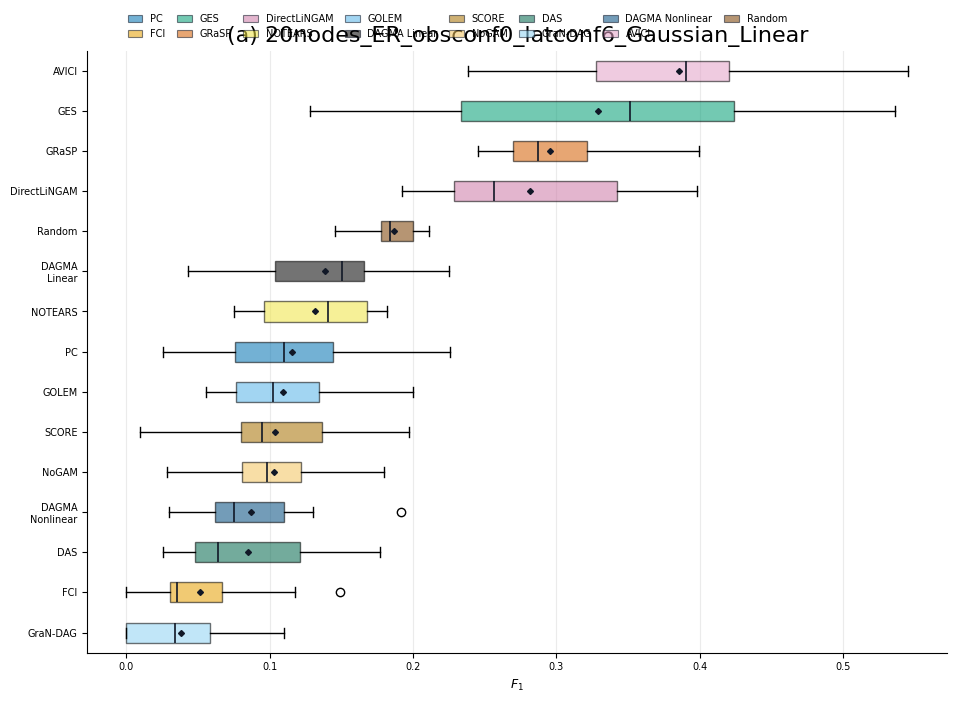

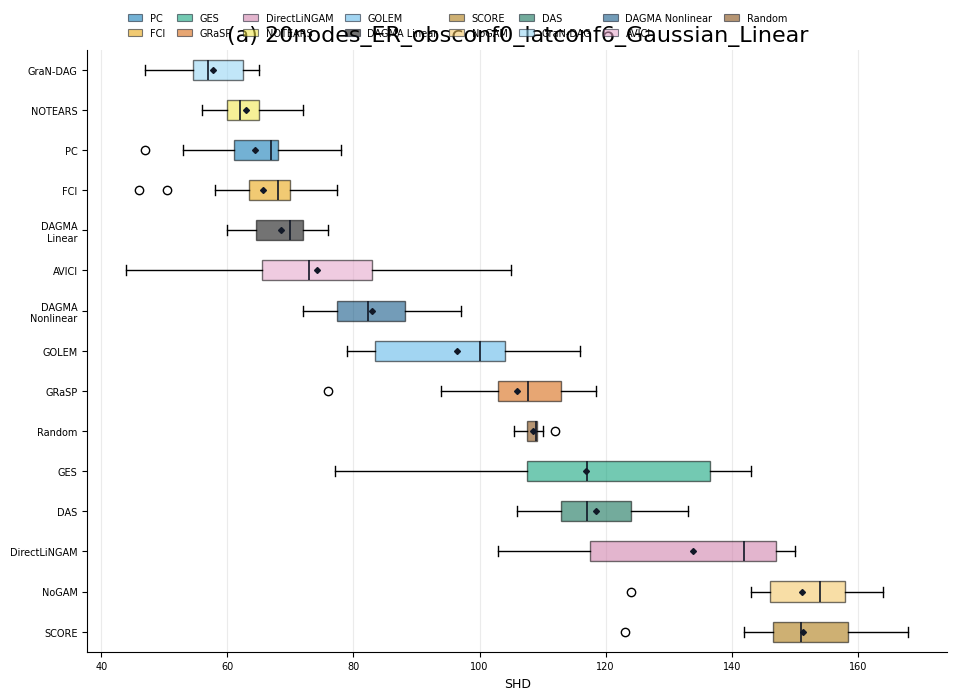

,dataset_seed,model,f1_range
0,11,AVICI,0.000000
1,11,DAGMA_Linear,0.000000
2,11,DAGMA_Nonlinear,0.138889
3,11,DAS,0.000000
4,11,DirectLiNGAM,0.000000
5,11,FCI,0.000000
6,11,GES,0.000000
7,11,GOLEM,0.000000
8,11,GRaSP,0.415534
9,11,GraNDAG,0.000000


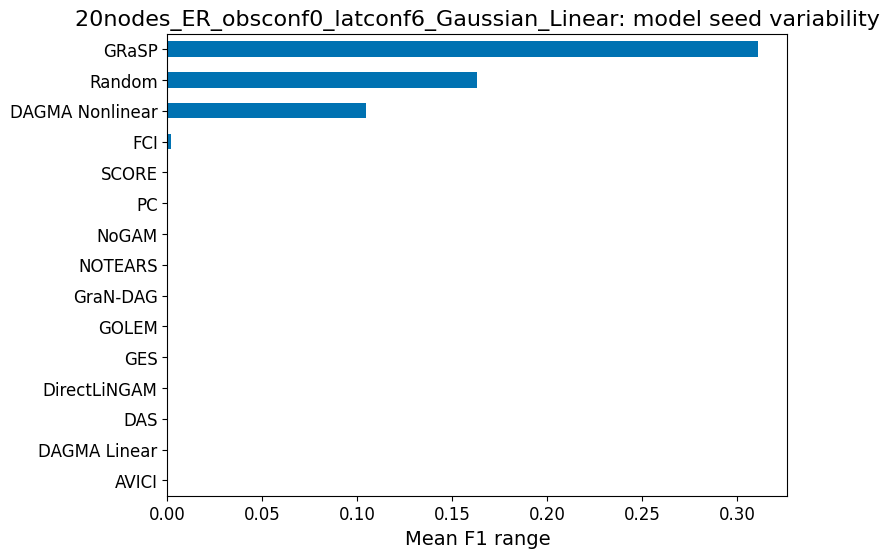

,model_seed,model,f1_range
0,0,AVICI,0.307359
1,0,DAGMA_Linear,0.181708
2,0,DAGMA_Nonlinear,0.131148
3,0,DAS,0.151899
4,0,DirectLiNGAM,0.205965
5,0,FCI,0.161290
6,0,GES,0.408234
7,0,GOLEM,0.144444
8,0,GRaSP,0.323167
9,0,GraNDAG,0.109589


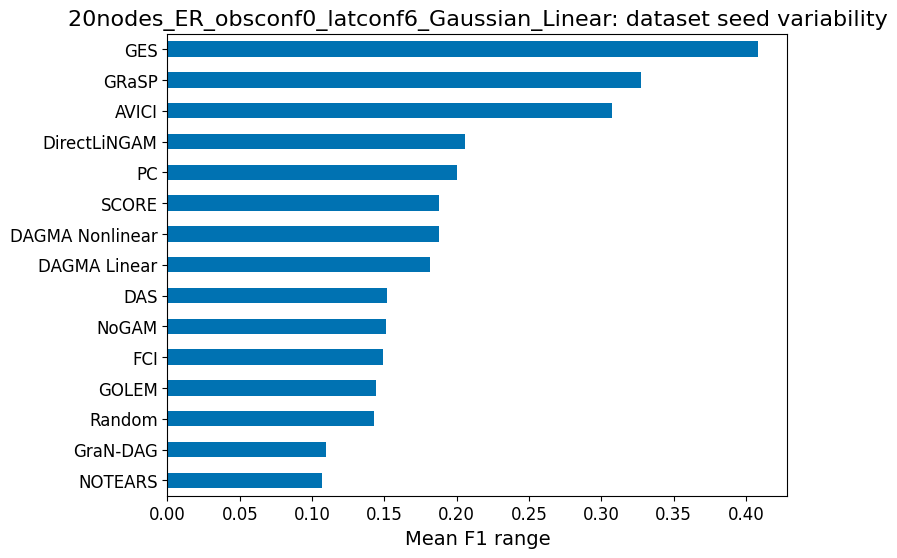

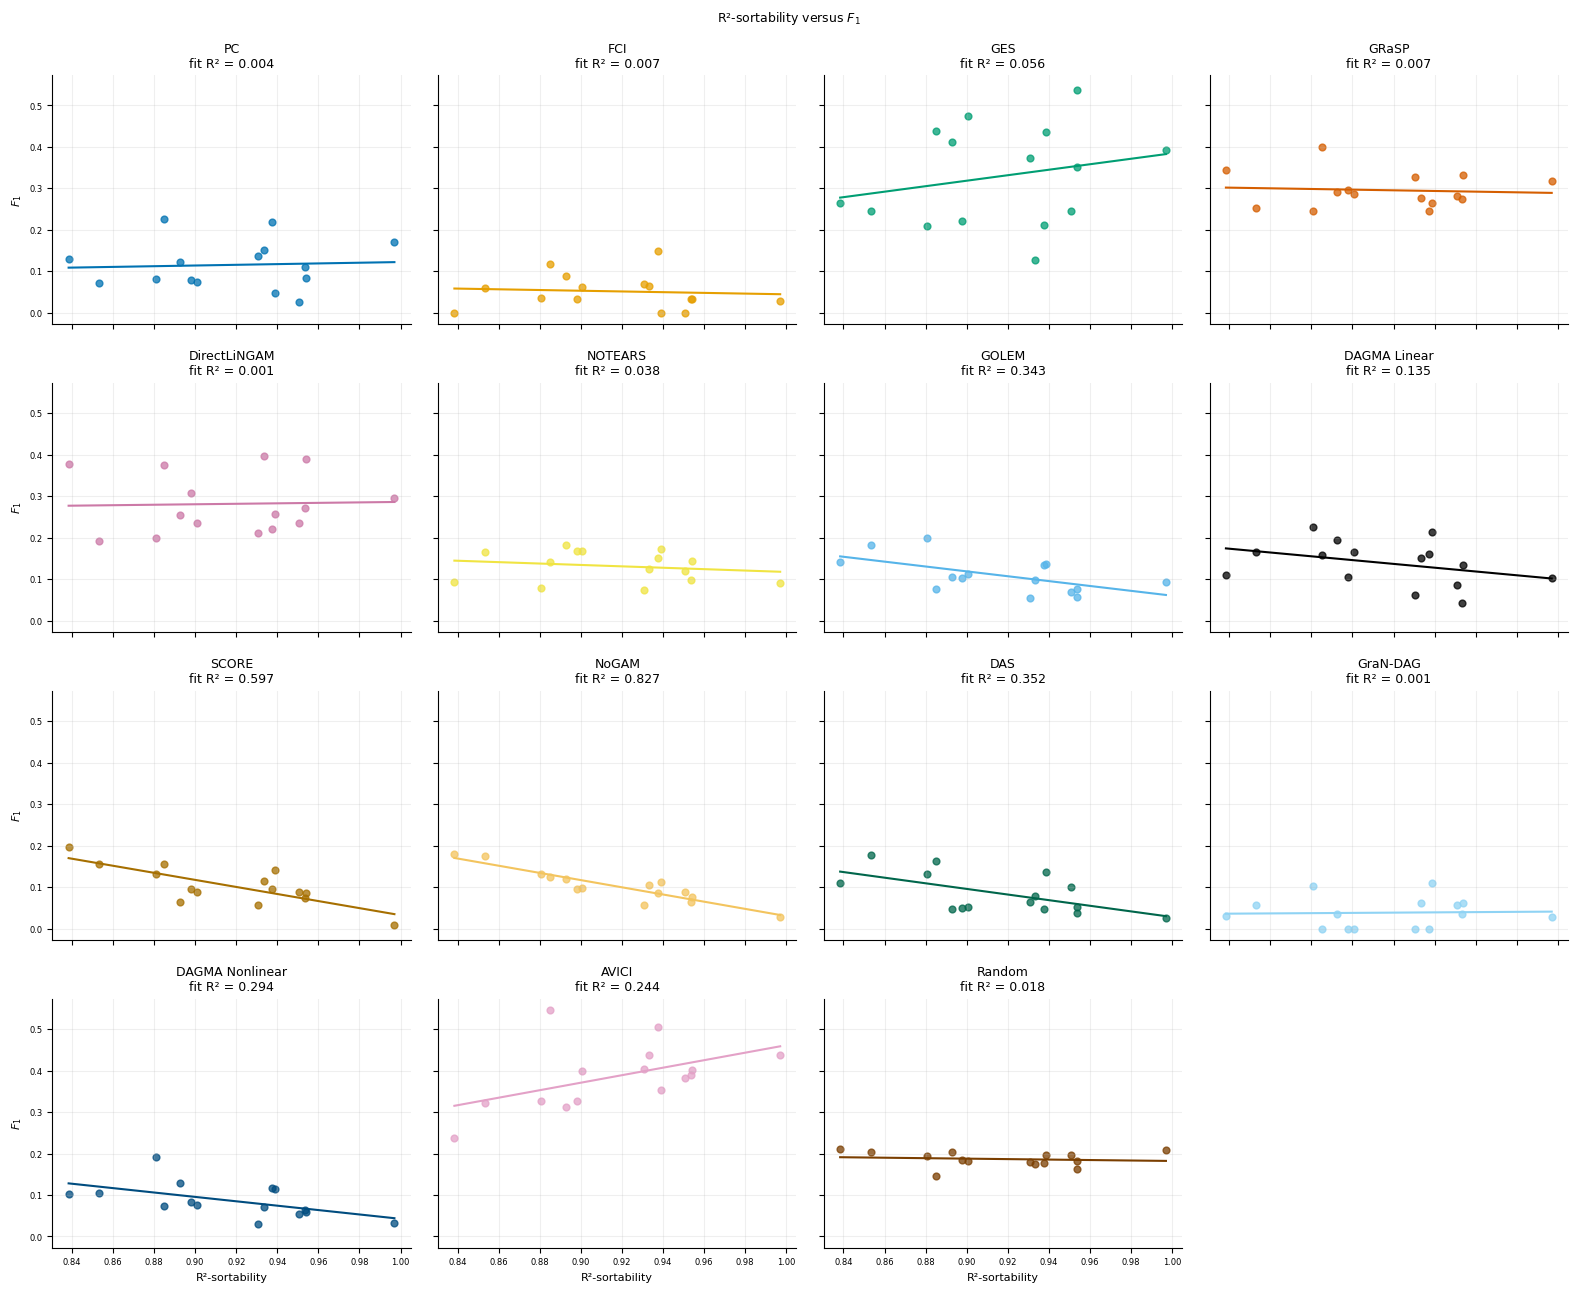

,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
585,benchmark,untuned,20nodes_ER_obsconf0_latconf6_Gaussian_Linear,AVICI,r2_sortability,15,0.503571,0.055655,estimated,1.00000
586,benchmark,untuned,20nodes_ER_obsconf0_latconf6_Gaussian_Linear,DAGMA_Linear,r2_sortability,15,-0.457143,0.086678,estimated,1.00000
587,benchmark,untuned,20nodes_ER_obsconf0_latconf6_Gaussian_Linear,DAGMA_Nonlinear,r2_sortability,15,-0.585714,0.021777,estimated,1.00000
588,benchmark,untuned,20nodes_ER_obsconf0_latconf6_Gaussian_Linear,DAS,r2_sortability,15,-0.573727,0.025334,estimated,1.00000
589,benchmark,untuned,20nodes_ER_obsconf0_latconf6_Gaussian_Linear,DirectLiNGAM,r2_sortability,15,0.221429,0.427714,estimated,1.00000
590,benchmark,untuned,20nodes_ER_obsconf0_latconf6_Gaussian_Linear,FCI,r2_sortability,15,-0.245742,0.377324,estimated,1.00000
591,benchmark,untuned,20nodes_ER_obsconf0_latconf6_Gaussian_Linear,GES,r2_sortability,15,0.228571,0.412566,estimated,1.00000
592,benchmark,untuned,20nodes_ER_obsconf0_latconf6_Gaussian_Linear,GOLEM,r2_sortability,15,-0.614286,0.014834,estimated,1.00000
593,benchmark,untuned,20nodes_ER_obsconf0_latconf6_Gaussian_Linear,GRaSP,r2_sortability,15,-0.021429,0.939578,estimated,1.00000
594,benchmark,untuned,20nodes_ER_obsconf0_latconf6_Gaussian_Linear,GraNDAG,r2_sortability,15,0.127412,0.650905,estimated,1.00000


,model,mean,std,size
0,AVICI,0.375366,0.087754,15
1,DAGMA_Linear,0.169114,0.049360,15
2,DAGMA_Nonlinear,0.106851,0.057187,15
3,DAS,0.105977,0.042190,15
4,DirectLiNGAM,0.268881,0.066722,15
5,FCI,0.062562,0.054086,15
6,GES,0.304107,0.084236,15
7,GOLEM,0.133543,0.066108,15
8,GRaSP,0.387895,0.073469,15
9,GraNDAG,0.049820,0.040129,15


,model,mean,std,size
0,AVICI,68.200000,15.302661,15
1,DAGMA_Linear,66.000000,5.042675,15
2,DAGMA_Nonlinear,77.871111,7.974303,15
3,DAS,115.066667,10.173261,15
4,DirectLiNGAM,135.000000,12.106669,15
5,FCI,66.302222,7.654353,15
6,GES,122.133333,15.051657,15
7,GOLEM,92.733333,8.647598,15
8,GRaSP,86.737778,13.556360,15
9,GraNDAG,57.000000,6.233550,15


,model,mean,std,size
0,AVICI,0.406182,0.117840,15
1,DAGMA_Linear,0.219330,0.069592,15
2,DAGMA_Nonlinear,0.117615,0.061272,15
3,DAS,0.082768,0.035503,15
4,DirectLiNGAM,0.183187,0.048767,15
5,FCI,0.336696,0.252855,15
6,GES,0.213680,0.064067,15
7,GOLEM,0.118207,0.061341,15
8,GRaSP,0.306186,0.067643,15
9,GraNDAG,0.348677,0.295062,15


,model,mean,std,size
0,AVICI,0.376971,0.114147,15
1,DAGMA_Linear,0.139443,0.041317,15
2,DAGMA_Nonlinear,0.099980,0.056104,15
3,DAS,0.148679,0.053466,15
4,DirectLiNGAM,0.507659,0.103529,15
5,FCI,0.034983,0.031041,15
6,GES,0.533680,0.128851,15
7,GOLEM,0.155577,0.074524,15
8,GRaSP,0.536070,0.079338,15
9,GraNDAG,0.027478,0.022399,15


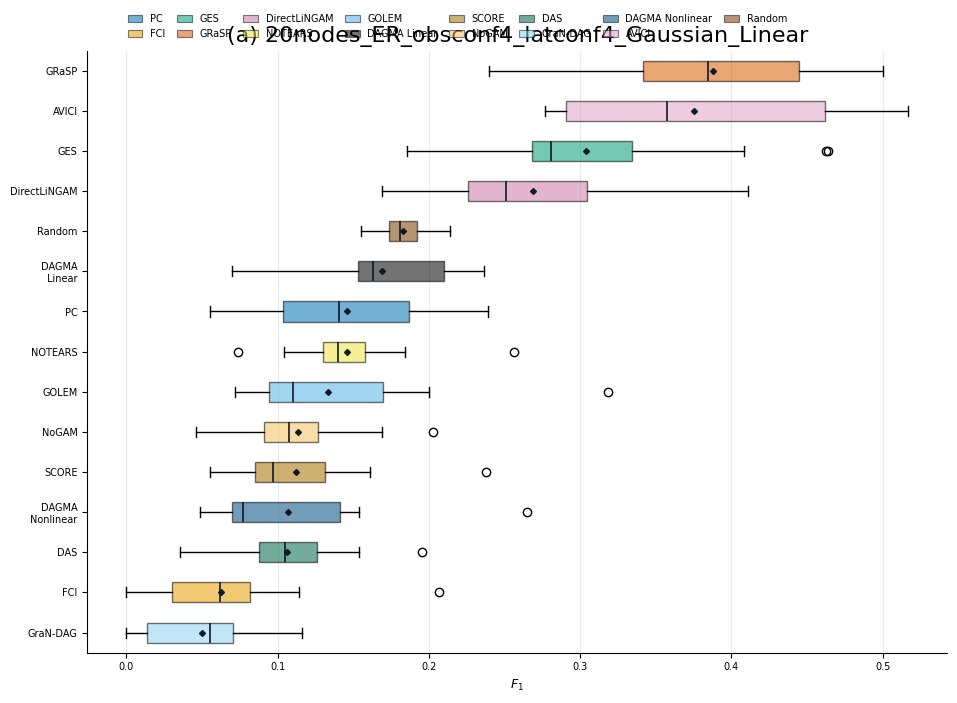

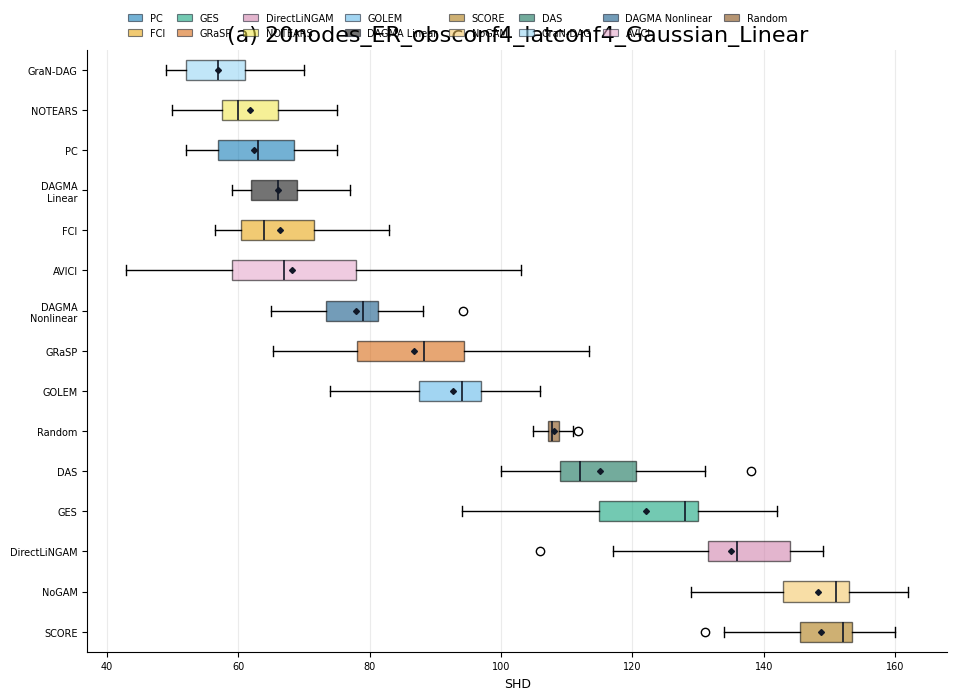

,dataset_seed,model,f1_range
0,11,AVICI,0.000000
1,11,DAGMA_Linear,0.000000
2,11,DAGMA_Nonlinear,0.071894
3,11,DAS,0.000000
4,11,DirectLiNGAM,0.000000
5,11,FCI,0.000000
6,11,GES,0.000000
7,11,GOLEM,0.000000
8,11,GRaSP,0.245064
9,11,GraNDAG,0.000000


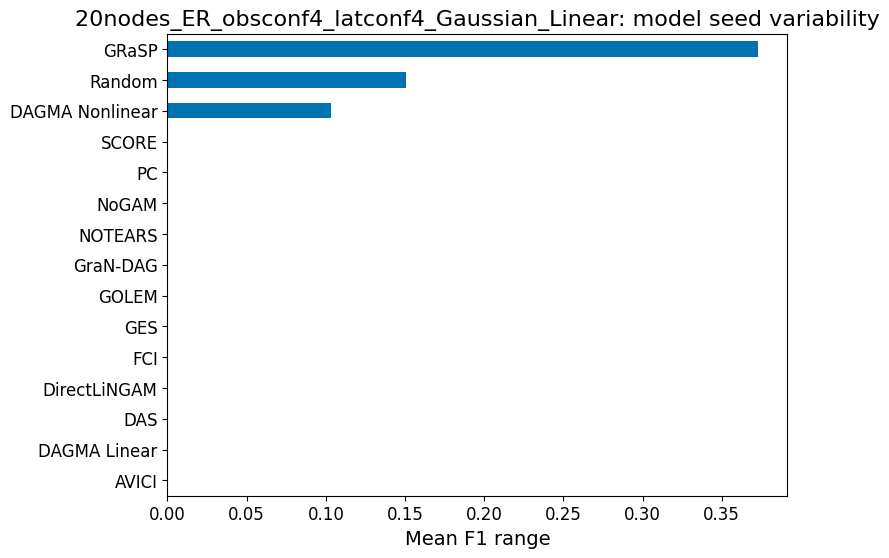

,model_seed,model,f1_range
0,0,AVICI,0.240258
1,0,DAGMA_Linear,0.166596
2,0,DAGMA_Nonlinear,0.190092
3,0,DAS,0.159899
4,0,DirectLiNGAM,0.241700
5,0,FCI,0.206897
6,0,GES,0.278552
7,0,GOLEM,0.246399
8,0,GRaSP,0.523646
9,0,GraNDAG,0.115942


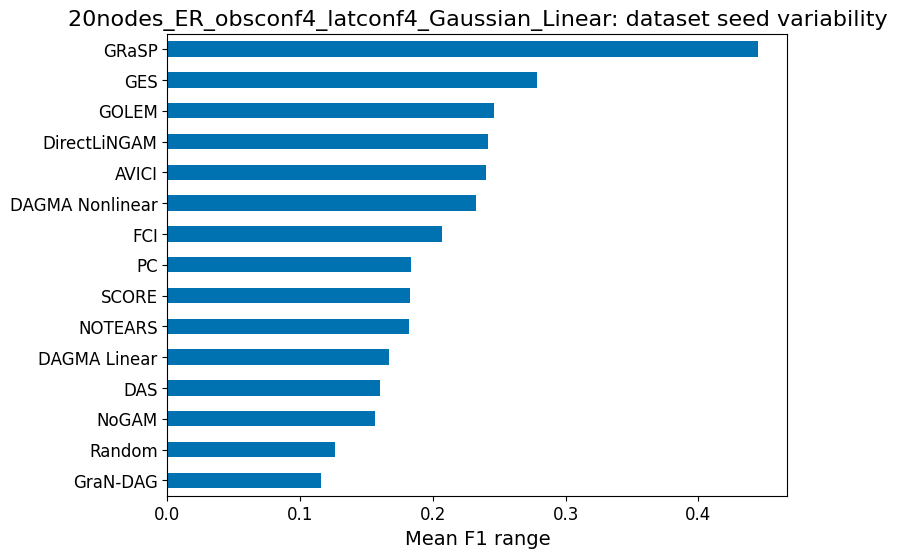

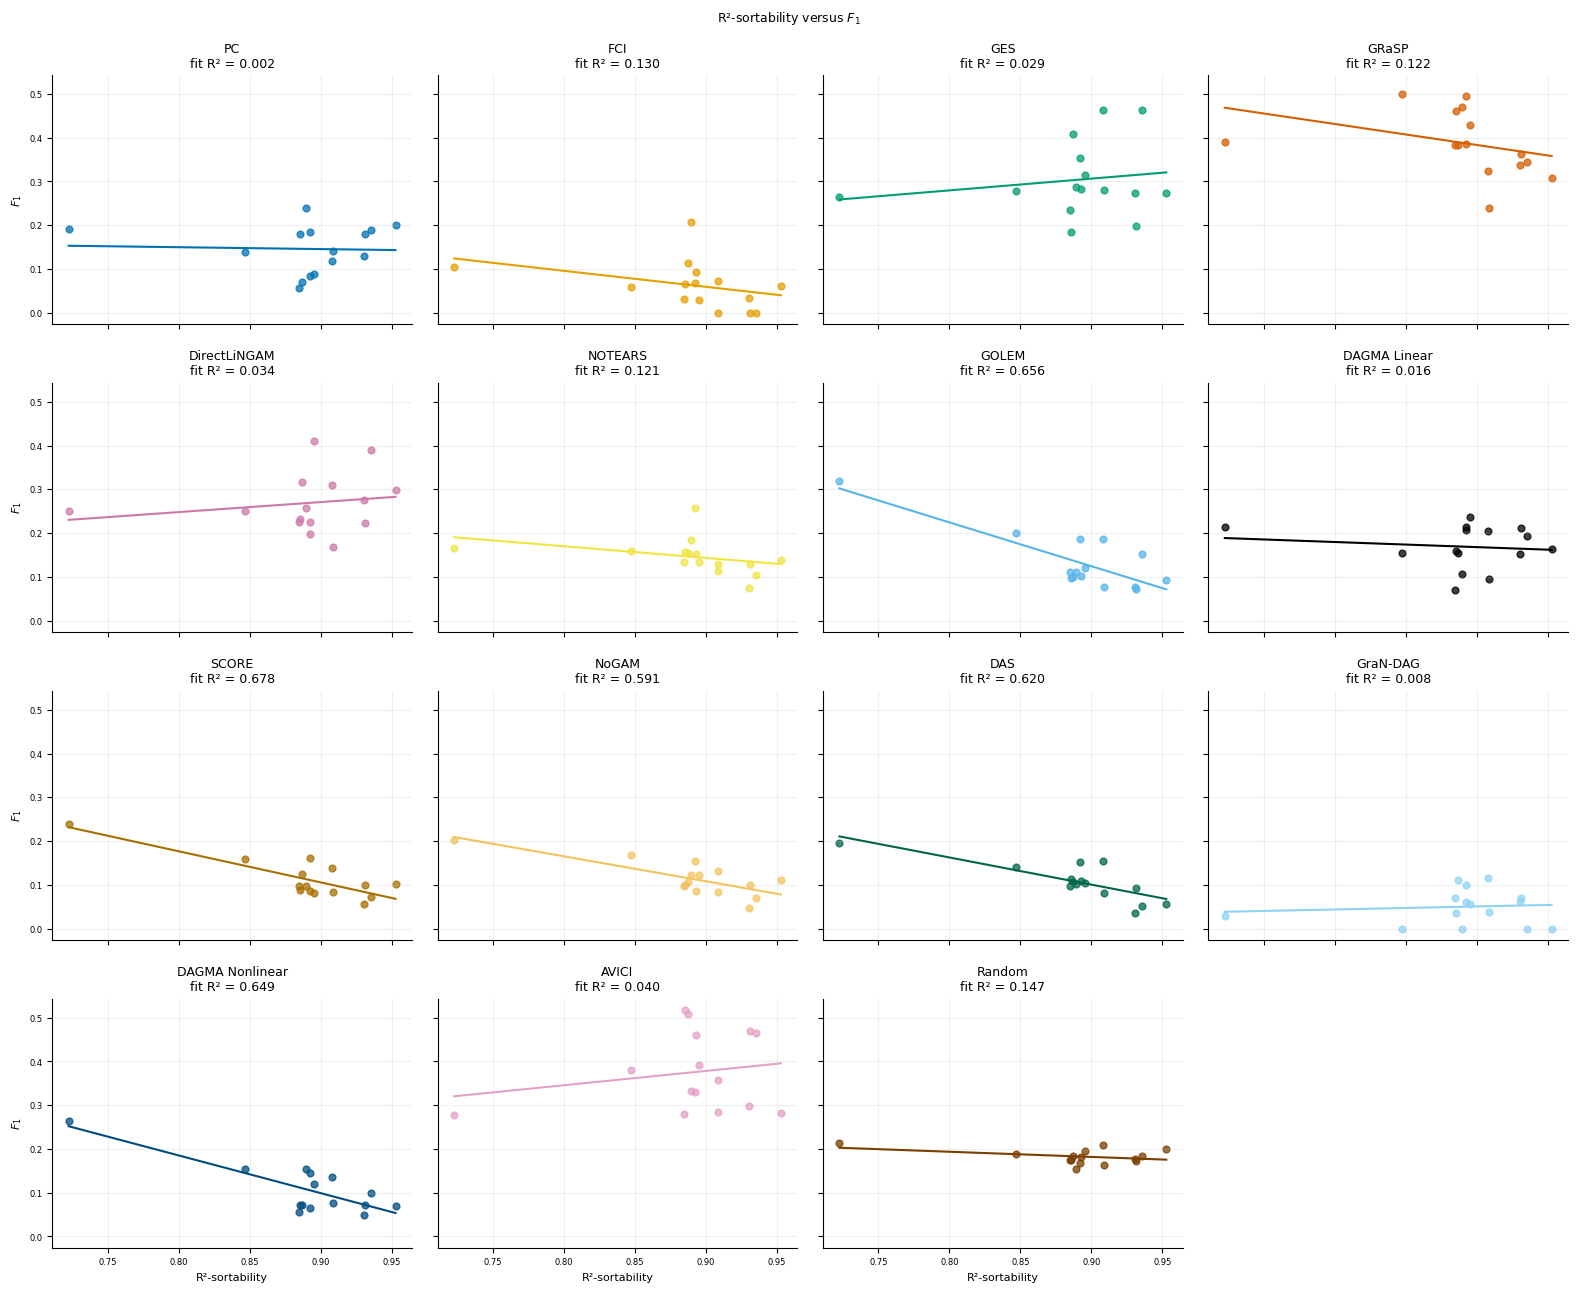

,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
600,benchmark,untuned,20nodes_ER_obsconf4_latconf4_Gaussian_Linear,AVICI,r2_sortability,15,0.096429,0.732453,estimated,1.0
601,benchmark,untuned,20nodes_ER_obsconf4_latconf4_Gaussian_Linear,DAGMA_Linear,r2_sortability,15,0.114286,0.685066,estimated,1.0
602,benchmark,untuned,20nodes_ER_obsconf4_latconf4_Gaussian_Linear,DAGMA_Nonlinear,r2_sortability,15,-0.410714,0.128329,estimated,1.0
603,benchmark,untuned,20nodes_ER_obsconf4_latconf4_Gaussian_Linear,DAS,r2_sortability,15,-0.696429,0.003921,estimated,1.0
604,benchmark,untuned,20nodes_ER_obsconf4_latconf4_Gaussian_Linear,DirectLiNGAM,r2_sortability,15,0.196429,0.482899,estimated,1.0
605,benchmark,untuned,20nodes_ER_obsconf4_latconf4_Gaussian_Linear,FCI,r2_sortability,15,-0.476706,0.072398,estimated,1.0
606,benchmark,untuned,20nodes_ER_obsconf4_latconf4_Gaussian_Linear,GES,r2_sortability,15,0.207143,0.458843,estimated,1.0
607,benchmark,untuned,20nodes_ER_obsconf4_latconf4_Gaussian_Linear,GOLEM,r2_sortability,15,-0.525000,0.044484,estimated,1.0
608,benchmark,untuned,20nodes_ER_obsconf4_latconf4_Gaussian_Linear,GRaSP,r2_sortability,15,-0.685714,0.004772,estimated,1.0
609,benchmark,untuned,20nodes_ER_obsconf4_latconf4_Gaussian_Linear,GraNDAG,r2_sortability,15,-0.009018,0.974556,estimated,1.0


,model,mean,std,size
0,AVICI,0.476564,0.068130,15
1,DAGMA_Linear,0.183086,0.107450,15
2,DAGMA_Nonlinear,0.109549,0.047424,15
3,DAS,0.117891,0.058746,15
4,DirectLiNGAM,0.315920,0.079424,15
5,FCI,0.089455,0.063986,15
6,GES,0.422505,0.201050,14
7,GOLEM,0.124155,0.054924,15
8,GRaSP,0.781358,0.077529,15
9,GraNDAG,0.062104,0.032118,15


,model,mean,std,size
0,AVICI,59.000000,12.878554,15
1,DAGMA_Linear,61.066667,10.031854,15
2,DAGMA_Nonlinear,75.457778,10.233833,15
3,DAS,102.266667,15.831554,15
4,DirectLiNGAM,112.200000,21.474902,15
5,FCI,60.666667,8.607859,15
6,GES,83.000000,36.624918,14
7,GOLEM,86.466667,12.211626,15
8,GRaSP,24.200000,11.000664,15
9,GraNDAG,56.466667,6.875076,15


,model,mean,std,size
0,AVICI,0.479803,0.064308,15
1,DAGMA_Linear,0.239632,0.123192,15
2,DAGMA_Nonlinear,0.119786,0.044337,15
3,DAS,0.095370,0.047870,15
4,DirectLiNGAM,0.225100,0.062203,15
5,FCI,0.522619,0.287280,15
6,GES,0.351680,0.220699,14
7,GOLEM,0.116254,0.054462,15
8,GRaSP,0.773828,0.089674,15
9,GraNDAG,0.554286,0.323379,15


,model,mean,std,size
0,AVICI,0.494908,0.130440,15
1,DAGMA_Linear,0.150277,0.097776,15
2,DAGMA_Nonlinear,0.103405,0.052411,15
3,DAS,0.155515,0.078133,15
4,DirectLiNGAM,0.535167,0.111867,15
5,FCI,0.049809,0.036909,15
6,GES,0.561018,0.162089,14
7,GOLEM,0.134982,0.058106,15
8,GRaSP,0.797347,0.071760,15
9,GraNDAG,0.034062,0.018590,15


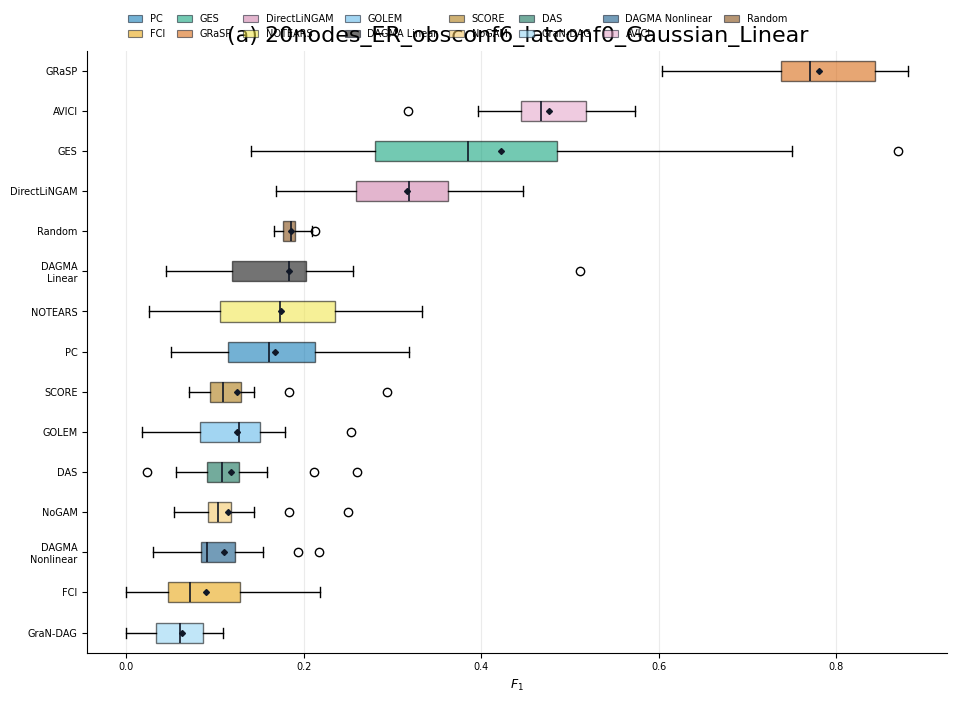

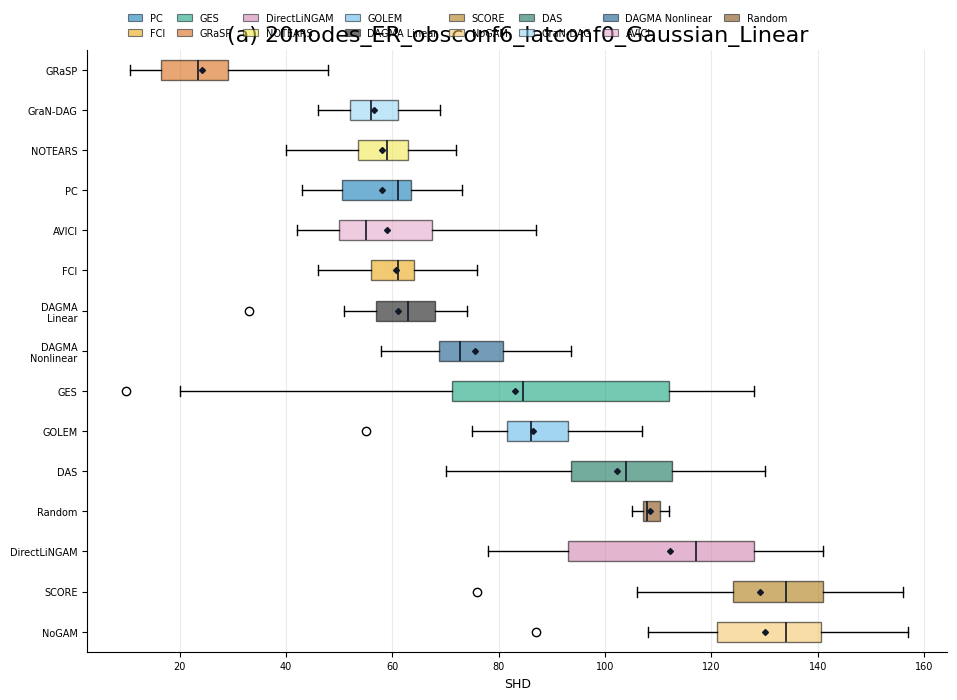

,dataset_seed,model,f1_range
0,11,AVICI,0.000000
1,11,DAGMA_Linear,0.000000
2,11,DAGMA_Nonlinear,0.212940
3,11,DAS,0.000000
4,11,DirectLiNGAM,0.000000
5,11,FCI,0.000000
6,11,GES,0.000000
7,11,GOLEM,0.000000
8,11,GRaSP,0.567879
9,11,GraNDAG,0.000000


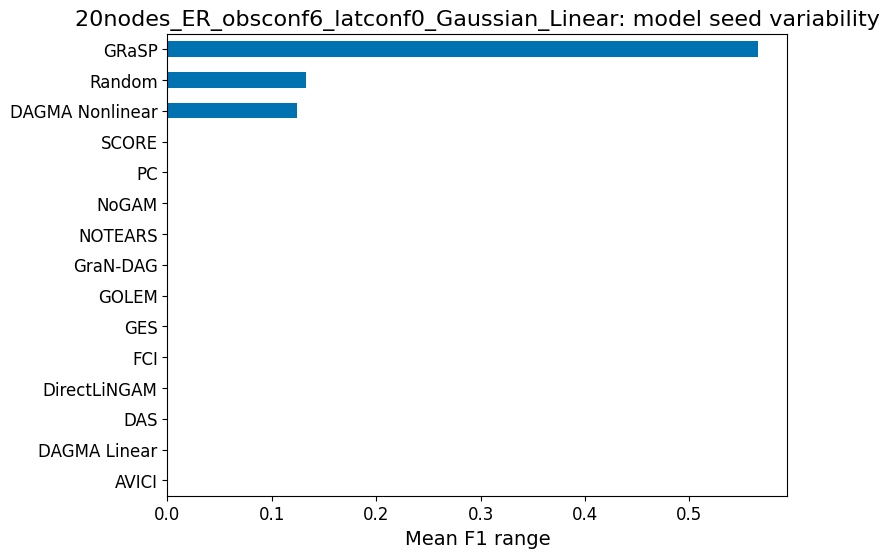

,model_seed,model,f1_range
0,0,AVICI,0.256156
1,0,DAGMA_Linear,0.467183
2,0,DAGMA_Nonlinear,0.235897
3,0,DAS,0.237305
4,0,DirectLiNGAM,0.278045
5,0,FCI,0.218182
6,0,GES,0.729025
7,0,GOLEM,0.235240
8,0,GRaSP,0.415830
9,0,GraNDAG,0.109091


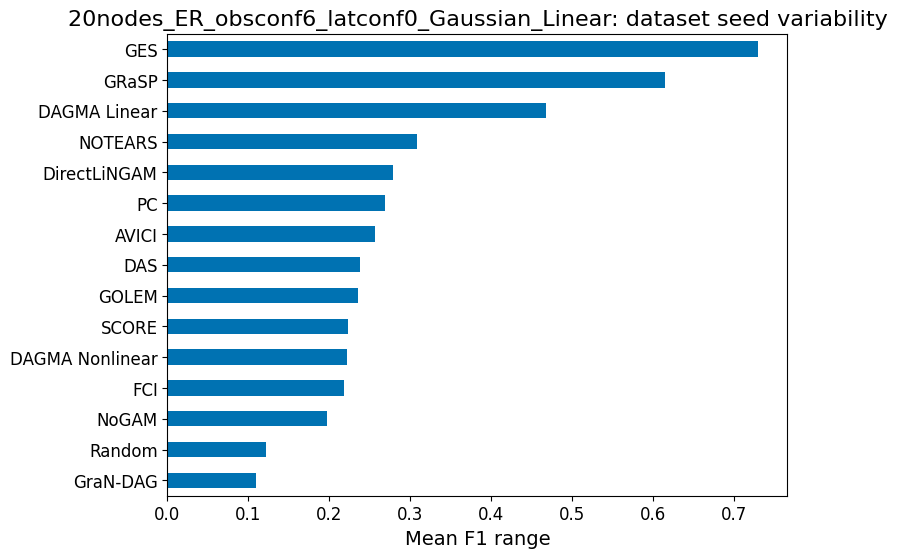

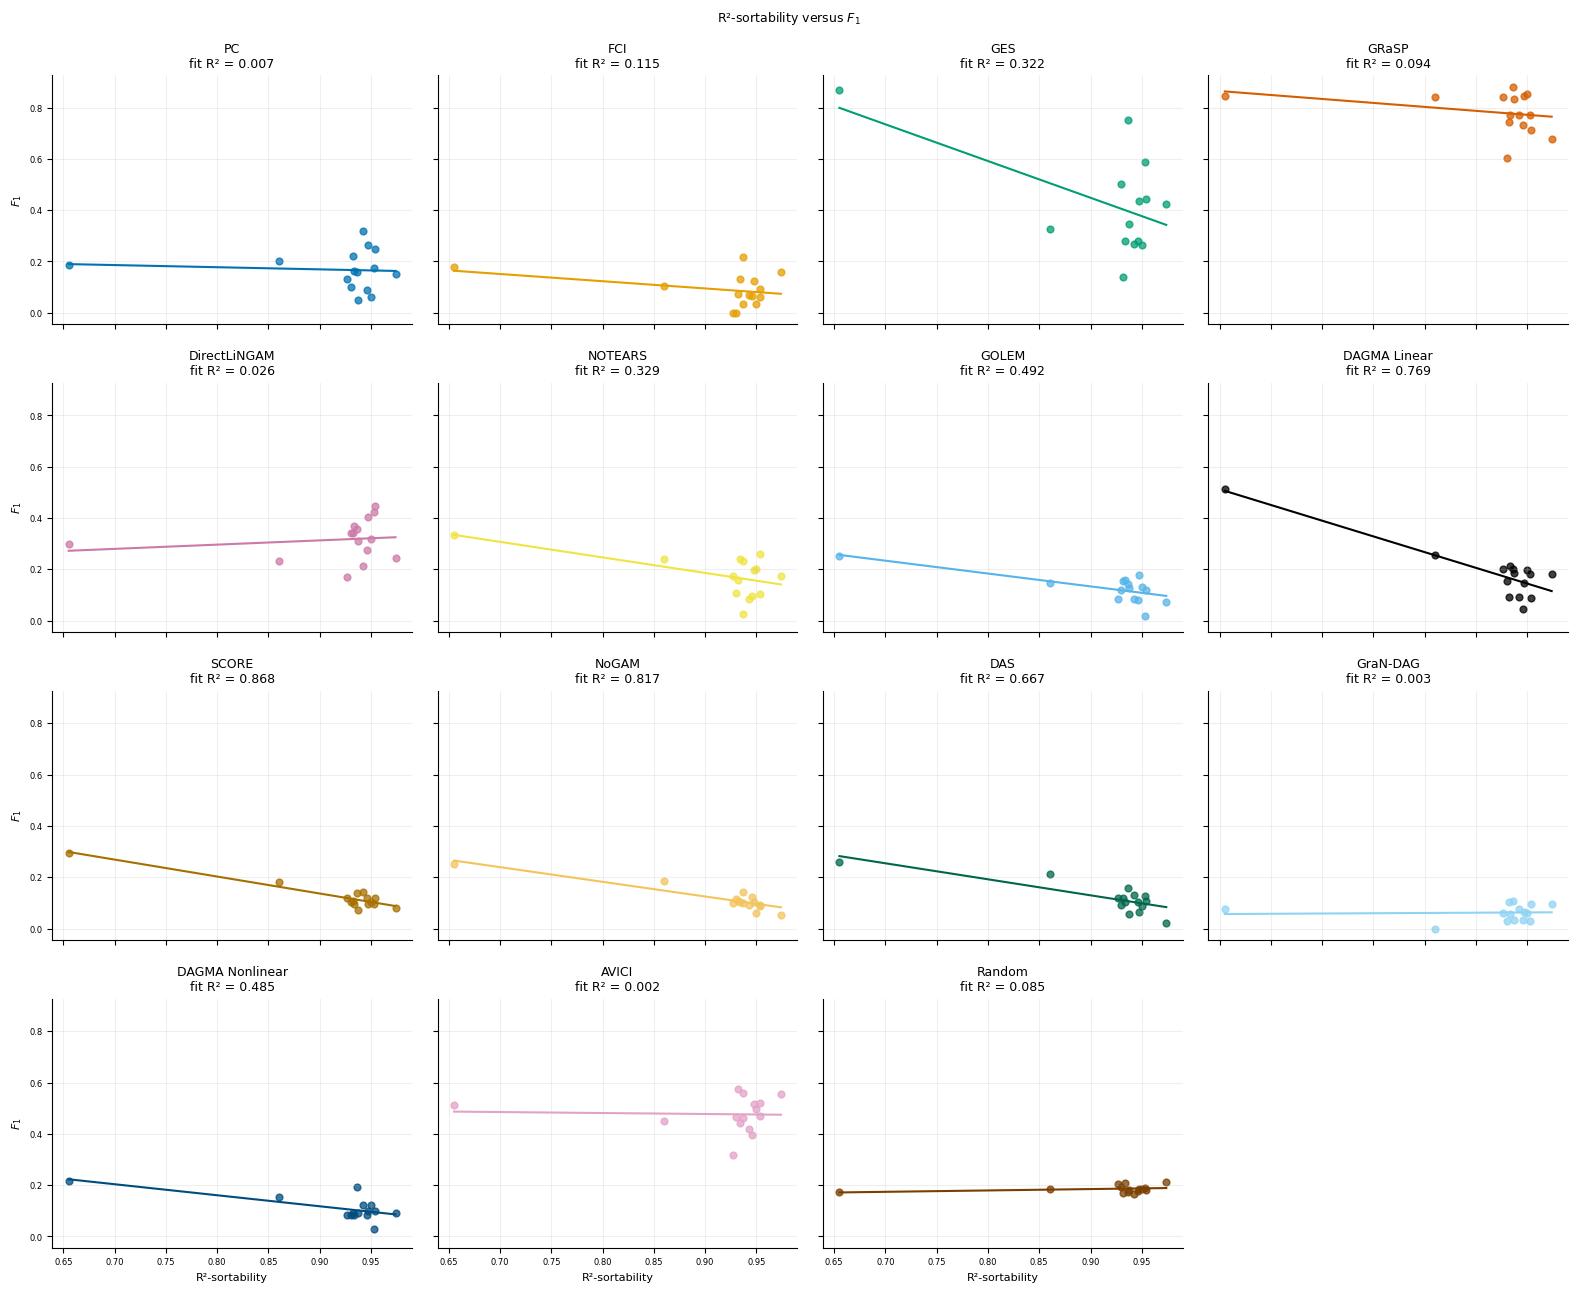

,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
615,benchmark,untuned,20nodes_ER_obsconf6_latconf0_Gaussian_Linear,AVICI,r2_sortability,15,0.282143,0.308284,estimated,1.000000
616,benchmark,untuned,20nodes_ER_obsconf6_latconf0_Gaussian_Linear,DAGMA_Linear,r2_sortability,15,-0.561216,0.029499,estimated,1.000000
617,benchmark,untuned,20nodes_ER_obsconf6_latconf0_Gaussian_Linear,DAGMA_Nonlinear,r2_sortability,15,-0.260714,0.347979,estimated,1.000000
618,benchmark,untuned,20nodes_ER_obsconf6_latconf0_Gaussian_Linear,DAS,r2_sortability,15,-0.550000,0.033655,estimated,1.000000
619,benchmark,untuned,20nodes_ER_obsconf6_latconf0_Gaussian_Linear,DirectLiNGAM,r2_sortability,15,0.375000,0.168433,estimated,1.000000
620,benchmark,untuned,20nodes_ER_obsconf6_latconf0_Gaussian_Linear,FCI,r2_sortability,15,0.005367,0.984855,estimated,1.000000
621,benchmark,untuned,20nodes_ER_obsconf6_latconf0_Gaussian_Linear,GES,r2_sortability,14,-0.063736,0.828626,estimated,1.000000
622,benchmark,untuned,20nodes_ER_obsconf6_latconf0_Gaussian_Linear,GOLEM,r2_sortability,15,-0.525000,0.044484,estimated,1.000000
623,benchmark,untuned,20nodes_ER_obsconf6_latconf0_Gaussian_Linear,GRaSP,r2_sortability,15,-0.300000,0.277317,estimated,1.000000
624,benchmark,untuned,20nodes_ER_obsconf6_latconf0_Gaussian_Linear,GraNDAG,r2_sortability,15,0.210714,0.450958,estimated,1.000000


,model,mean,std,size
0,AVICI,0.583749,0.104799,15
1,DAGMA_Linear,0.297902,0.125217,15
2,DAGMA_Nonlinear,0.364061,0.040671,15
3,DAS,0.456641,0.112567,15
4,DirectLiNGAM,0.306594,0.084000,15
5,FCI,0.166515,0.096268,15
6,GES,0.434051,0.143125,15
7,GOLEM,0.317772,0.150289,15
8,GRaSP,0.437429,0.110207,15
9,GraNDAG,0.138309,0.154783,15


,model,mean,std,size
0,AVICI,21.666667,6.410557,15
1,DAGMA_Linear,25.400000,4.968472,15
2,DAGMA_Nonlinear,25.200000,2.455315,15
3,DAS,30.933333,7.215724,15
4,DirectLiNGAM,37.600000,6.822233,15
5,FCI,31.466667,6.501282,15
6,GES,30.066667,6.922702,15
7,GOLEM,29.600000,7.641989,15
8,GRaSP,26.511111,5.200163,15
9,GraNDAG,26.800000,3.098387,15


,model,mean,std,size
0,AVICI,0.601844,0.118098,15
1,DAGMA_Linear,0.389026,0.149065,15
2,DAGMA_Nonlinear,0.421004,0.045562,15
3,DAS,0.386906,0.107395,15
4,DirectLiNGAM,0.253698,0.071177,15
5,FCI,0.486809,0.290764,15
6,GES,0.421379,0.146195,15
7,GOLEM,0.370434,0.192622,15
8,GRaSP,0.523779,0.117999,15
9,GraNDAG,0.541282,0.432552,15


,model,mean,std,size
0,AVICI,0.578773,0.118910,15
1,DAGMA_Linear,0.245926,0.115467,15
2,DAGMA_Nonlinear,0.325881,0.052106,15
3,DAS,0.561543,0.119628,15
4,DirectLiNGAM,0.390813,0.111183,15
5,FCI,0.102797,0.061452,15
6,GES,0.453867,0.153310,15
7,GOLEM,0.288168,0.140084,15
8,GRaSP,0.379022,0.104848,15
9,GraNDAG,0.085786,0.106612,15


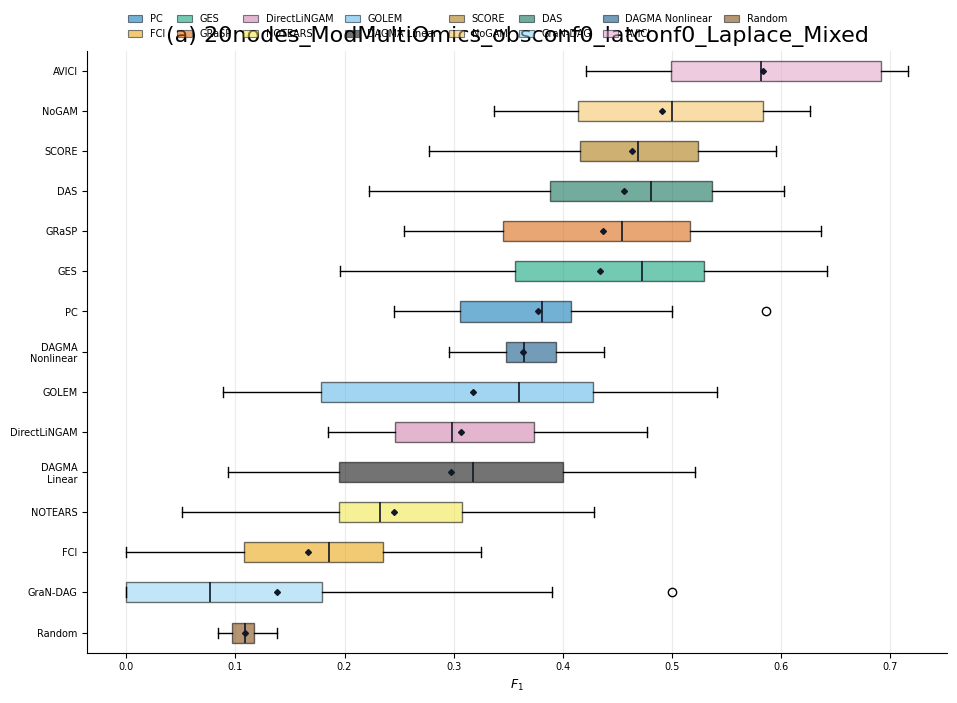

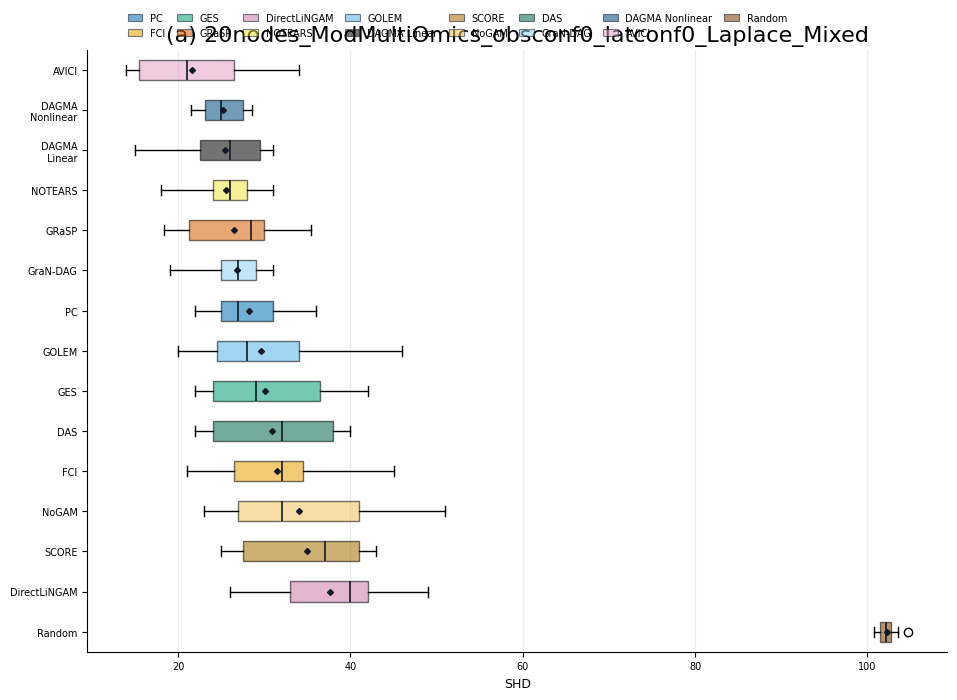

,dataset_seed,model,f1_range
0,11,AVICI,0.000000
1,11,DAGMA_Linear,0.000000
2,11,DAGMA_Nonlinear,0.452242
3,11,DAS,0.000000
4,11,DirectLiNGAM,0.000000
5,11,FCI,0.000000
6,11,GES,0.000000
7,11,GOLEM,0.000000
8,11,GRaSP,0.387518
9,11,GraNDAG,0.000000


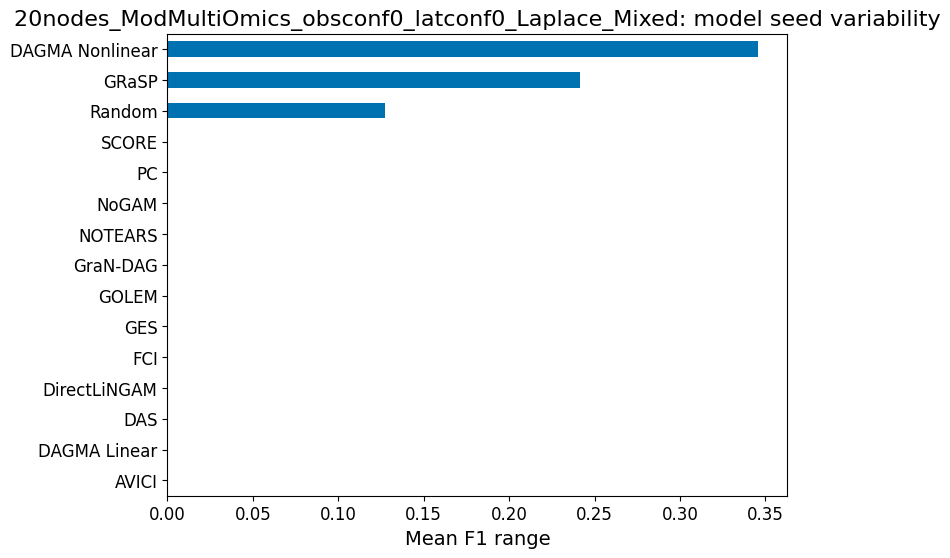

,model_seed,model,f1_range
0,0,AVICI,0.295929
1,0,DAGMA_Linear,0.428716
2,0,DAGMA_Nonlinear,0.367938
3,0,DAS,0.380518
4,0,DirectLiNGAM,0.292997
5,0,FCI,0.325581
6,0,GES,0.446779
7,0,GOLEM,0.452778
8,0,GRaSP,0.462865
9,0,GraNDAG,0.500000


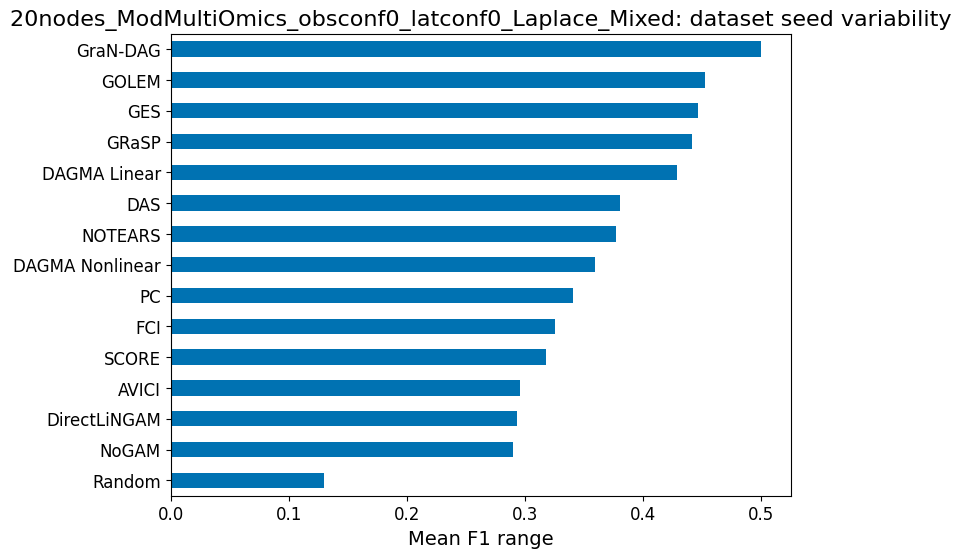

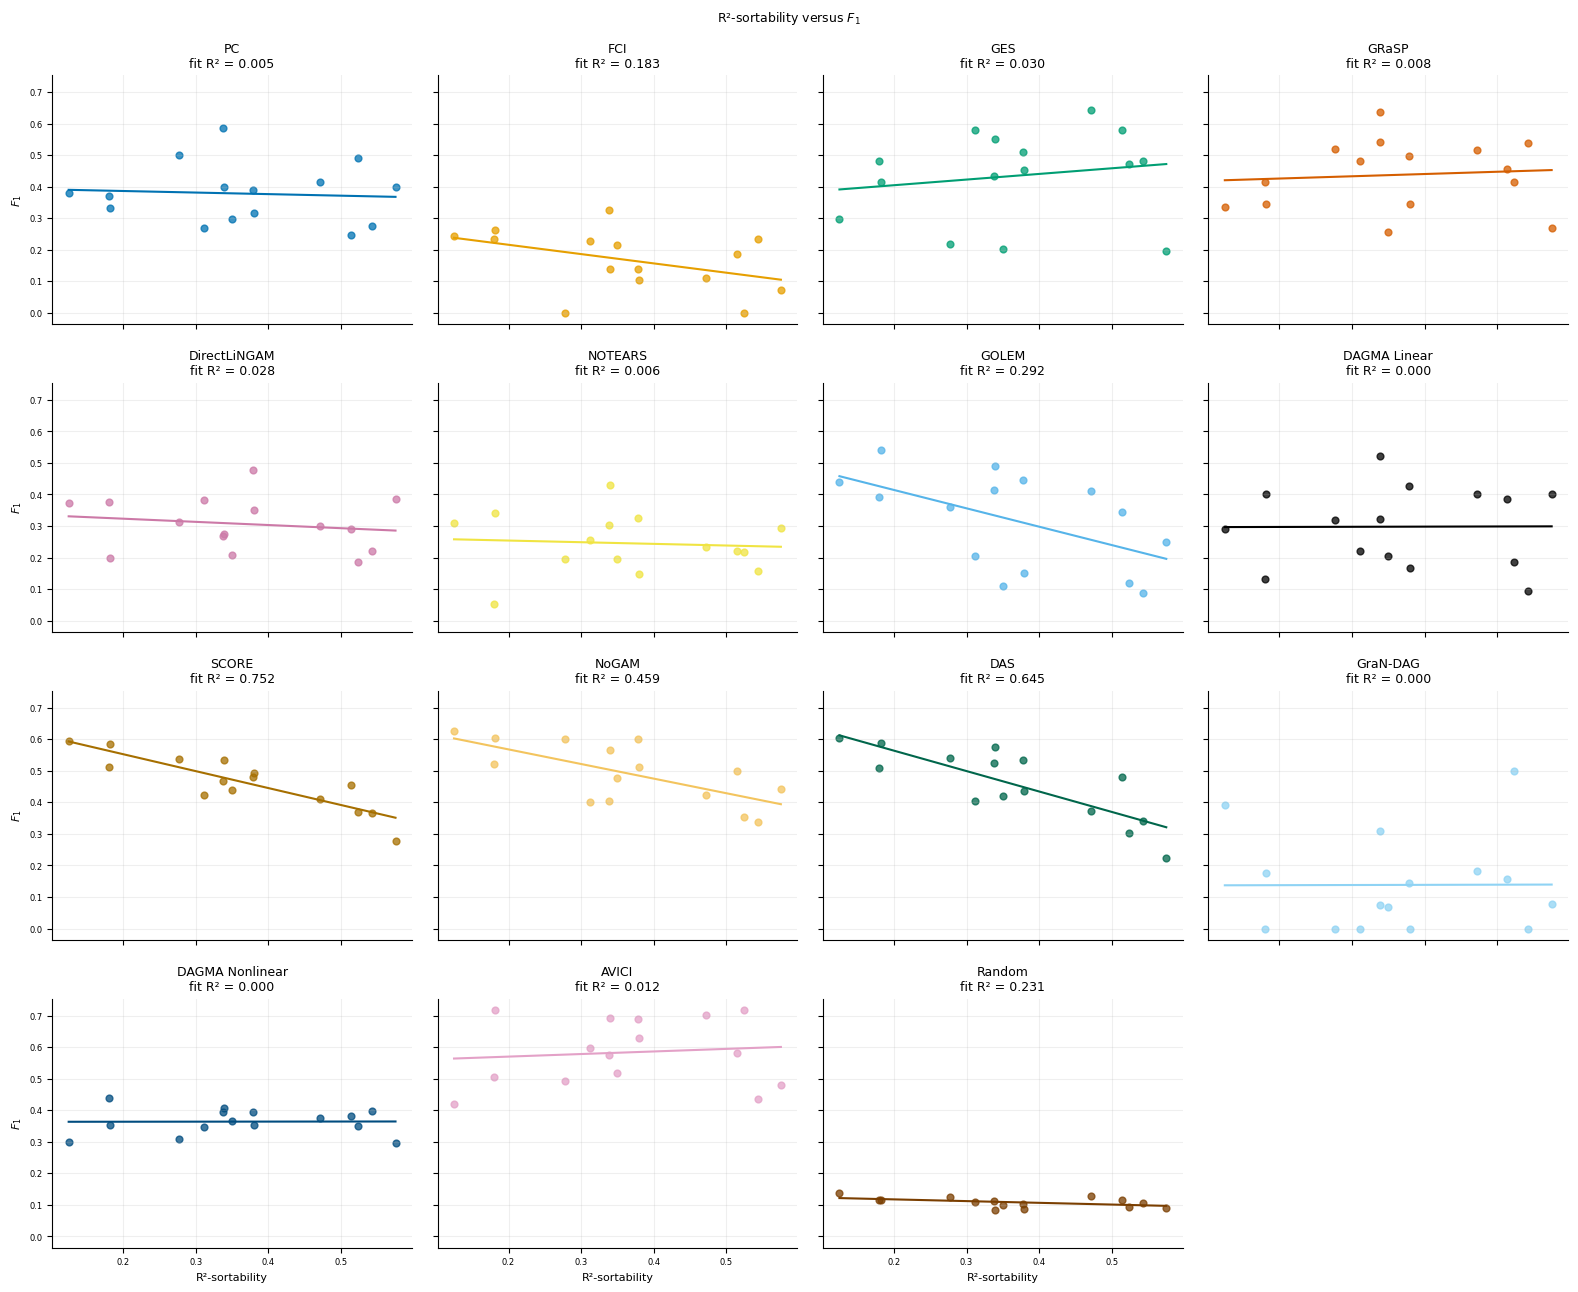

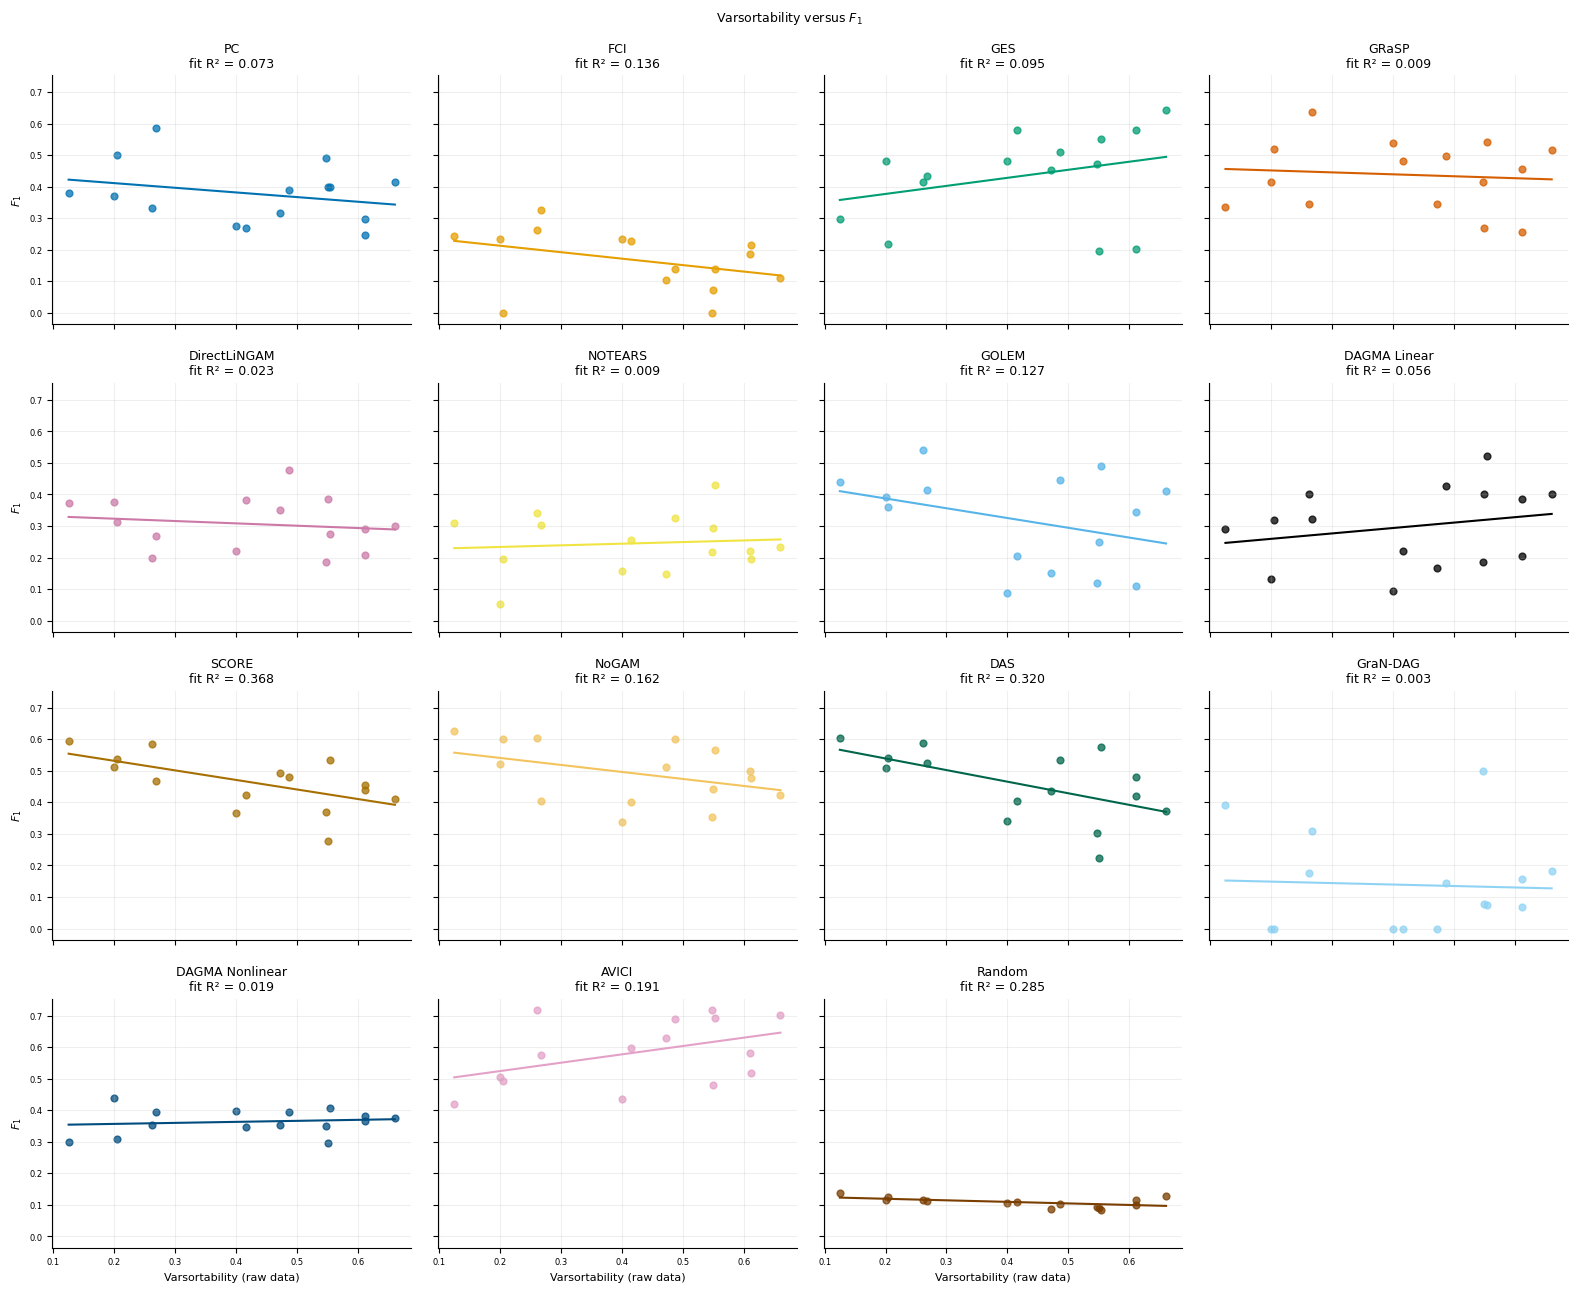

,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
630,benchmark,untuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,AVICI,r2_sortability,15,0.103664,0.713133,estimated,1.000000
631,benchmark,untuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,AVICI,varsortability,15,0.411081,0.127954,estimated,1.000000
632,benchmark,untuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAGMA_Linear,r2_sortability,15,0.007169,0.979772,estimated,1.000000
633,benchmark,untuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAGMA_Linear,varsortability,15,0.351257,0.199222,estimated,1.000000
634,benchmark,untuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAGMA_Nonlinear,r2_sortability,15,-0.003571,0.989921,estimated,1.000000
635,benchmark,untuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAGMA_Nonlinear,varsortability,15,0.100000,0.722897,estimated,1.000000
636,benchmark,untuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAS,r2_sortability,15,-0.789286,0.000467,estimated,0.226653
637,benchmark,untuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAS,varsortability,15,-0.507143,0.053664,estimated,1.000000
638,benchmark,untuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DirectLiNGAM,r2_sortability,15,-0.128571,0.647916,estimated,1.000000
639,benchmark,untuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DirectLiNGAM,varsortability,15,-0.164286,0.558497,estimated,1.000000


,model,mean,std,size
0,AVICI,0.615188,0.043392,15
1,DAGMA_Linear,0.244411,0.096911,15
2,DAGMA_Nonlinear,0.335257,0.058819,15
3,DAS,0.405120,0.074142,15
4,DirectLiNGAM,0.351732,0.063968,15
5,FCI,0.219233,0.117168,15
6,GES,0.485273,0.090578,15
7,GOLEM,0.230780,0.083236,15
8,GRaSP,0.472341,0.095617,15
9,GraNDAG,0.143401,0.154354,15


,model,mean,std,size
0,AVICI,17.933333,4.558613,15
1,DAGMA_Linear,25.466667,4.356713,15
2,DAGMA_Nonlinear,25.164444,3.706011,15
3,DAS,34.800000,6.504943,15
4,DirectLiNGAM,36.000000,10.555973,15
5,FCI,32.960000,6.478183,15
6,GES,27.933333,5.496319,15
7,GOLEM,29.933333,5.311264,15
8,GRaSP,24.186667,4.324768,15
9,GraNDAG,25.133333,3.398879,15


,model,mean,std,size
0,AVICI,0.668837,0.093910,15
1,DAGMA_Linear,0.357443,0.148350,15
2,DAGMA_Nonlinear,0.410465,0.069238,15
3,DAS,0.331030,0.072002,15
4,DirectLiNGAM,0.292690,0.064904,15
5,FCI,0.576763,0.266498,15
6,GES,0.466299,0.084873,15
7,GOLEM,0.284426,0.104228,15
8,GRaSP,0.576078,0.090848,15
9,GraNDAG,0.492650,0.363609,15


,model,mean,std,size
0,AVICI,0.583620,0.077072,15
1,DAGMA_Linear,0.191336,0.083537,15
2,DAGMA_Nonlinear,0.290159,0.062664,15
3,DAS,0.529117,0.090282,15
4,DirectLiNGAM,0.454457,0.095456,15
5,FCI,0.138177,0.079096,15
6,GES,0.518986,0.128148,15
7,GOLEM,0.201896,0.080234,15
8,GRaSP,0.413810,0.112337,15
9,GraNDAG,0.088358,0.104034,15


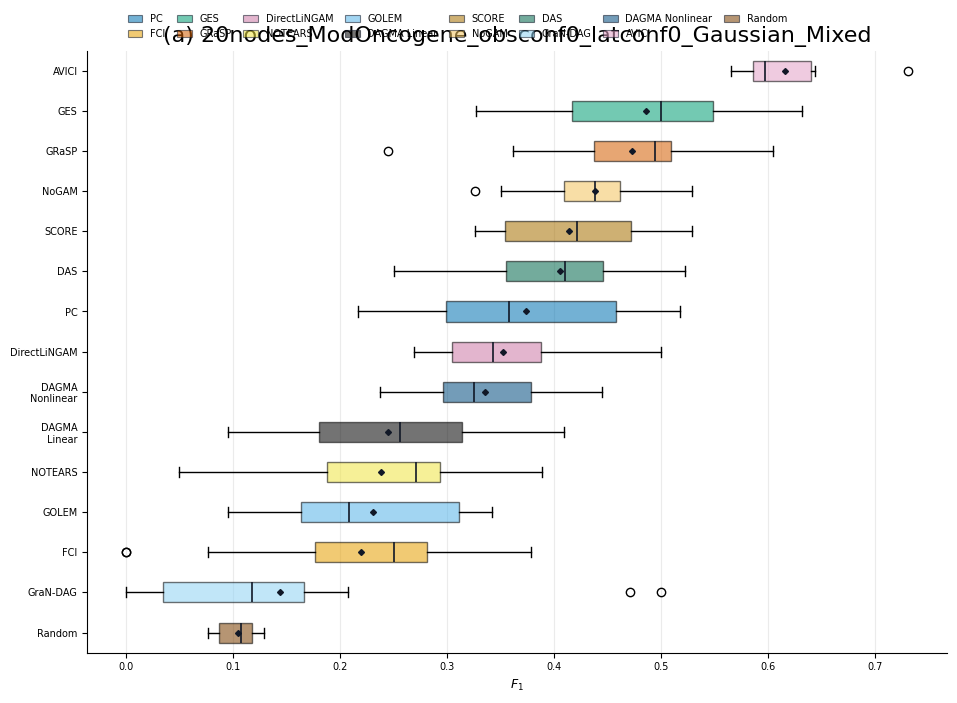

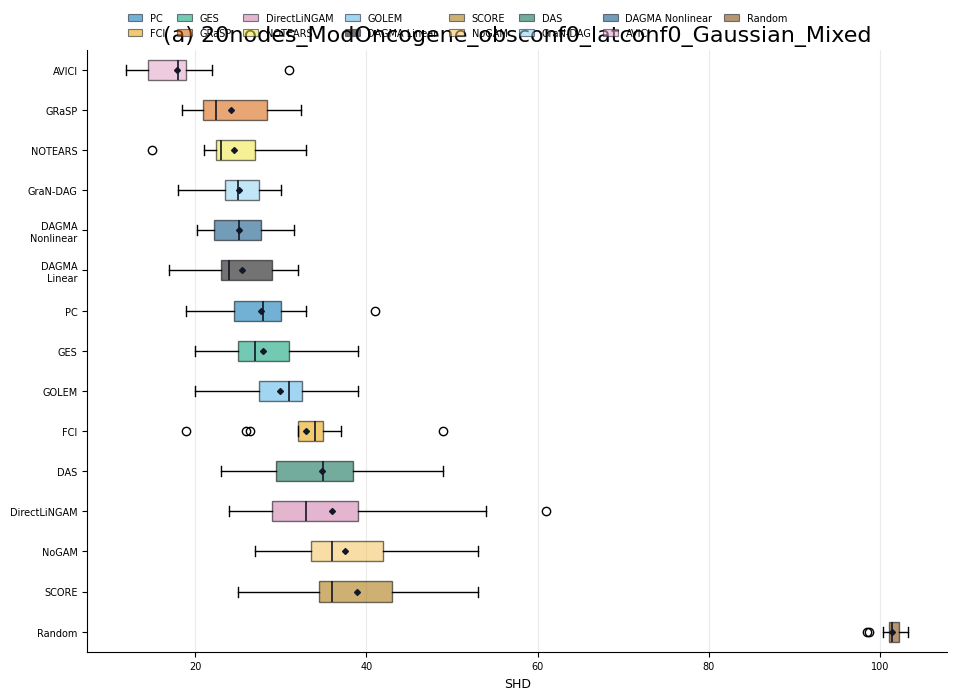

,dataset_seed,model,f1_range
0,11,AVICI,0.000000
1,11,DAGMA_Linear,0.000000
2,11,DAGMA_Nonlinear,0.346952
3,11,DAS,0.000000
4,11,DirectLiNGAM,0.000000
5,11,FCI,0.000000
6,11,GES,0.000000
7,11,GOLEM,0.000000
8,11,GRaSP,0.089575
9,11,GraNDAG,0.000000


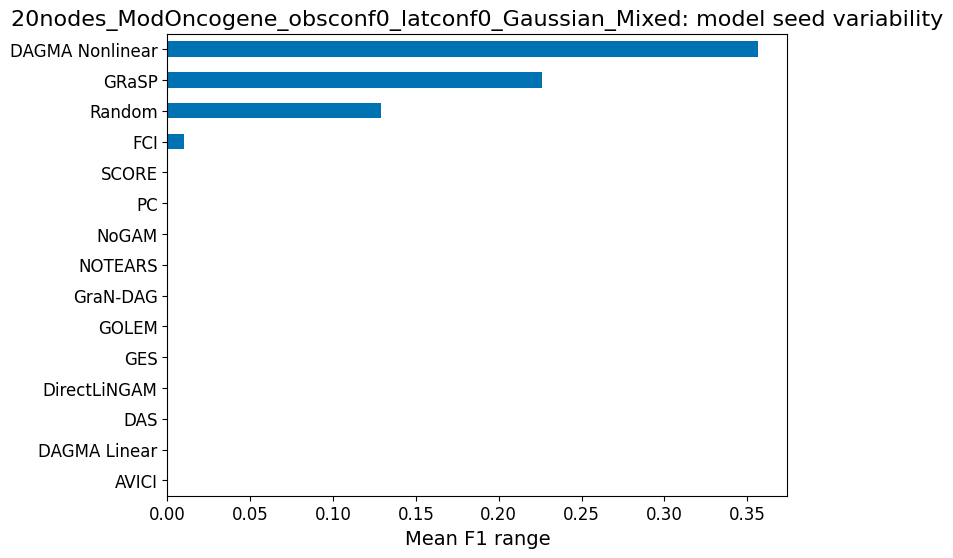

,model_seed,model,f1_range
0,0,AVICI,0.165552
1,0,DAGMA_Linear,0.313853
2,0,DAGMA_Nonlinear,0.400177
3,0,DAS,0.271739
4,0,DirectLiNGAM,0.230769
5,0,FCI,0.378378
6,0,GES,0.305048
7,0,GOLEM,0.246225
8,0,GRaSP,0.559307
9,0,GraNDAG,0.500000


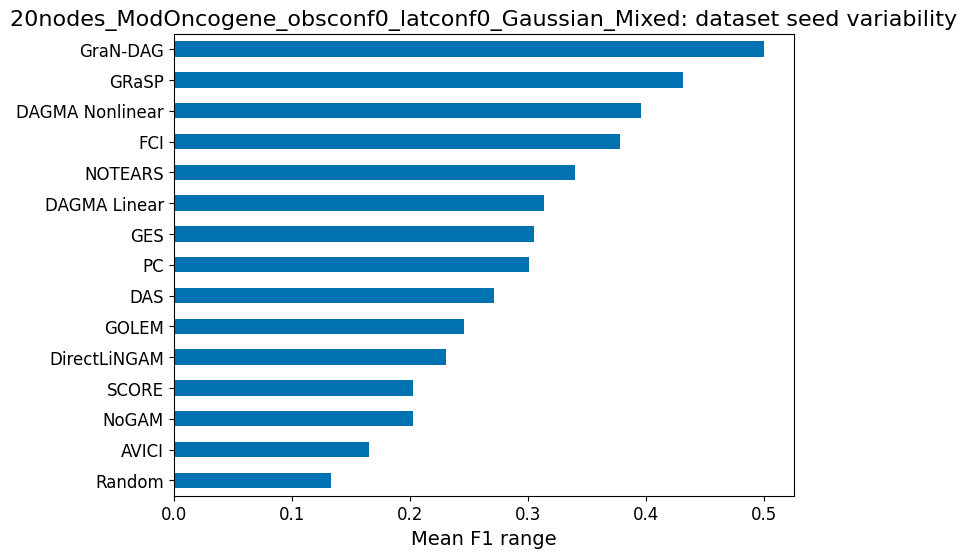

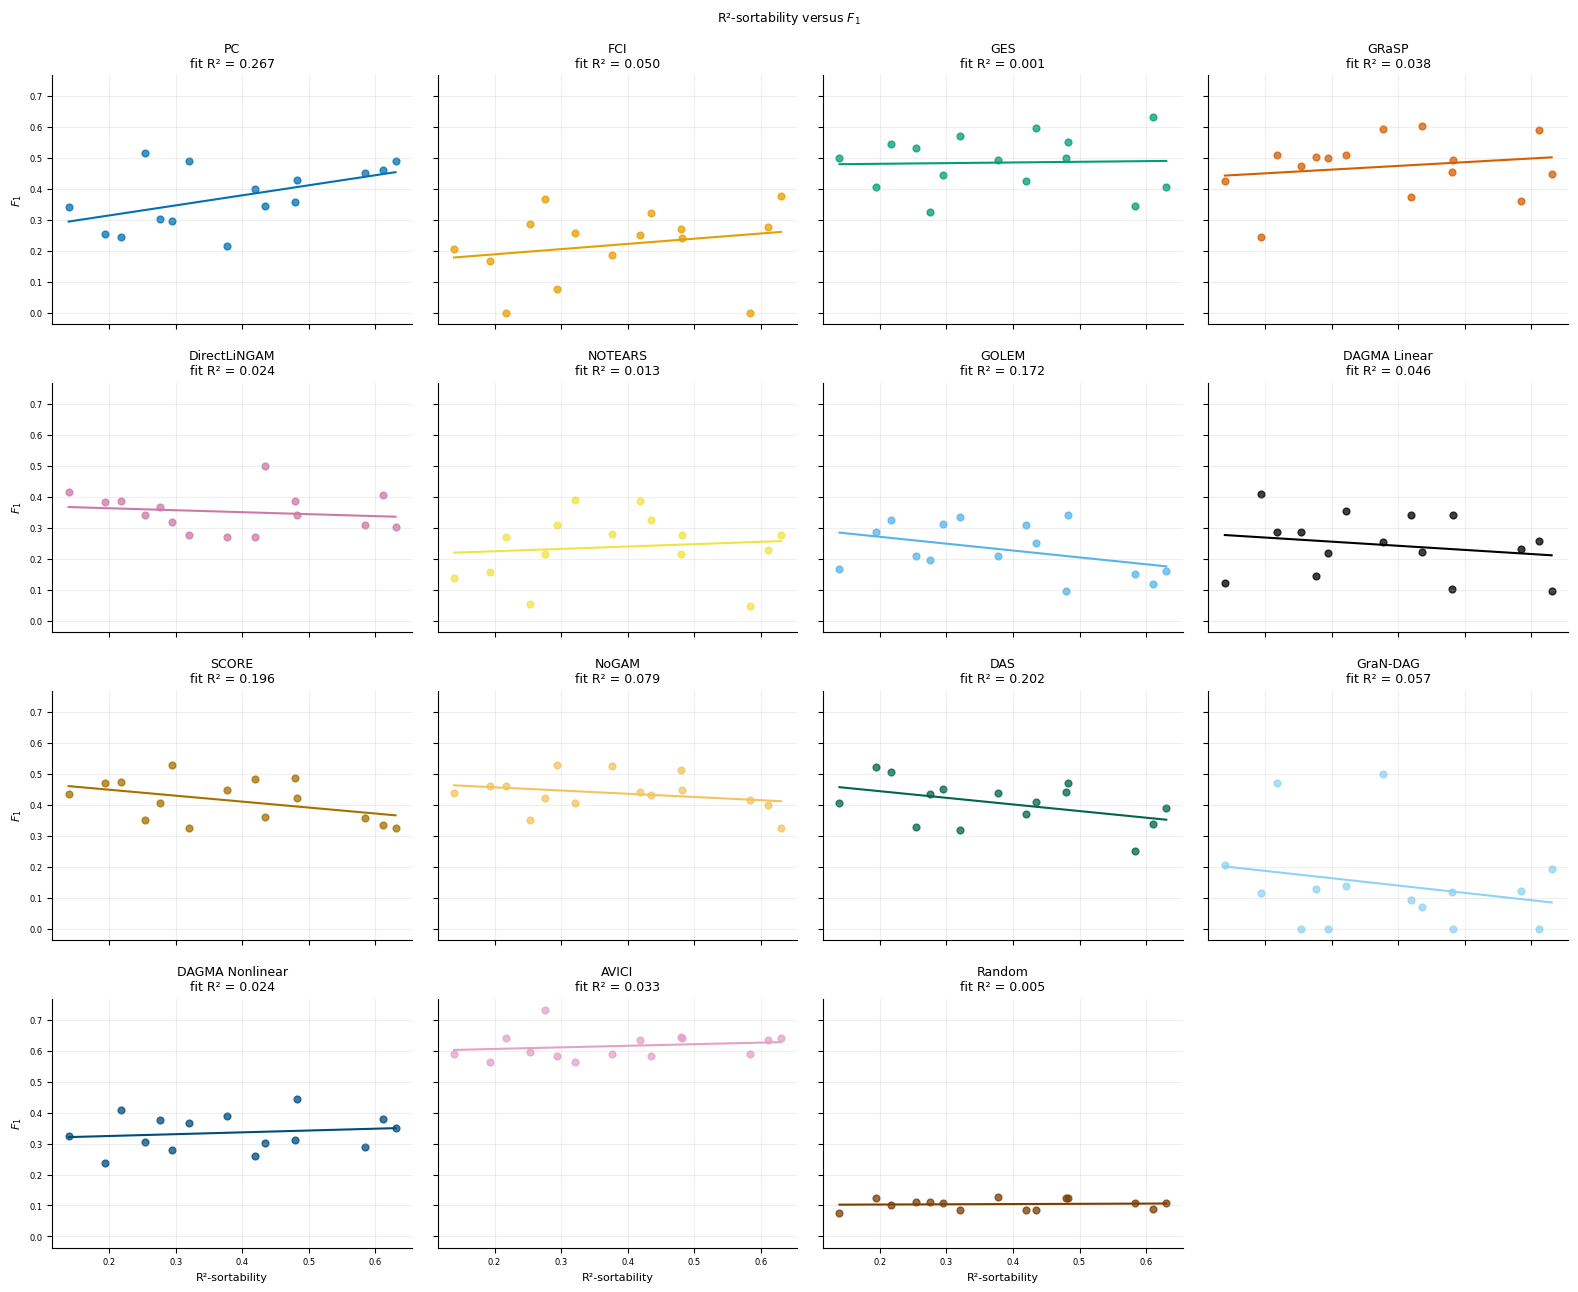

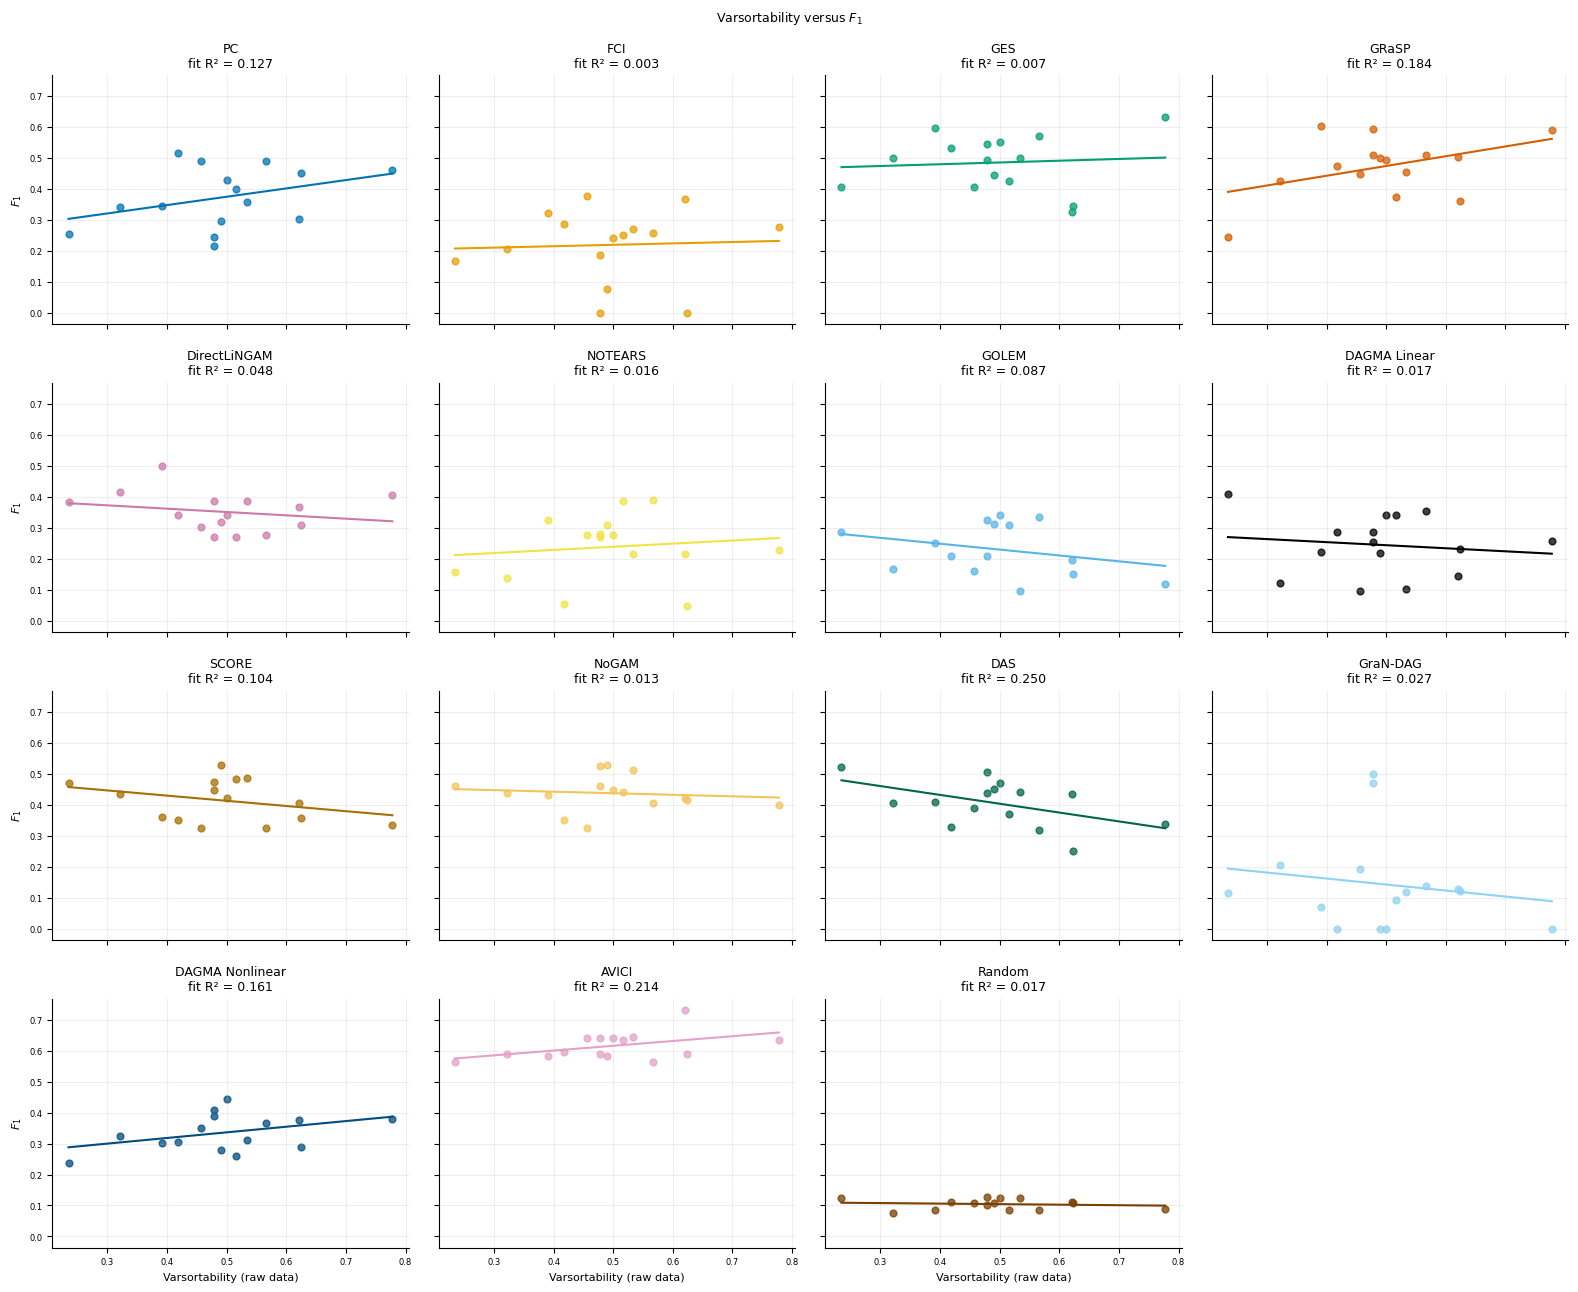

,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
660,benchmark,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,AVICI,r2_sortability,15,0.237712,0.393597,estimated,1.0
661,benchmark,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,AVICI,varsortability,15,0.338104,0.217736,estimated,1.0
662,benchmark,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAGMA_Linear,r2_sortability,15,-0.237712,0.393597,estimated,1.0
663,benchmark,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAGMA_Linear,varsortability,15,-0.002683,0.992427,estimated,1.0
664,benchmark,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAGMA_Nonlinear,r2_sortability,15,0.153571,0.584764,estimated,1.0
665,benchmark,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAGMA_Nonlinear,varsortability,15,0.255585,0.357884,estimated,1.0
666,benchmark,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAS,r2_sortability,15,-0.346429,0.205896,estimated,1.0
667,benchmark,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAS,varsortability,15,-0.393208,0.147073,estimated,1.0
668,benchmark,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DirectLiNGAM,r2_sortability,15,-0.232350,0.404667,estimated,1.0
669,benchmark,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DirectLiNGAM,varsortability,15,-0.256708,0.355703,estimated,1.0


In [21]:
for family in selected_families:
    print('\n' + family)
    frame = family_fits.loc[family_fits.dataset.eq(family)]
    values = sort_tables['sortability_all']
    values = values.loc[values.dataset.eq(family) & values.study.eq('benchmark')]
    for arm, group in frame.groupby('arm', observed=True):
        saved = family_tables[('benchmark', family, arm)]
        data = th.visualization_data(group)
        for metric in ('f1','SHD','precision','recall'):
            display(saved['summaries'][metric].head(20))
        for metric in ('f1','SHD'):
            fig, _, _ = fv.plot_metric_boxplot_grid(data, [dict(title=family,datasets=family)], metric=metric, coverage_policy='all', ncols=1, figsize=(10,7), font_size=9)
            display(fig)
            plt.close(fig)
        for kind, table in saved['ranges'].items():
            display(table.head(20))
            fig, ax = plt.subplots(figsize=(8,6))
            saved['range_summaries'][kind].rename(index=th.model_label).plot.barh(ax=ax)
            ax.set(xlabel='Mean F1 range',ylabel='',title=f"{family}: {kind.replace('_',' ')} variability")
            display(fig)
            plt.close(fig)
        for score in ('r2_sortability','varsortability'):
            if values[score].notna().sum() < 3:
                continue
            fig, _, _ = fv.plot_varsortability_vs_f1(data, metric='f1', datasets=family, varsortability_values=values, sortability=score, prepared_data=pd.read_pickle(ROOT / "results/analysis/plot_data.pkl")["scatter"][('benchmark', family, arm, score)], coverage_policy='all', columns=4, include_r2_sort_regress=False, obs_conf=None, lat_conf=None, font_size=8, title_size=9)
            display(fig)
            plt.close(fig)

    corr = sort_tables['corr']
    corr = corr.loc[corr.dataset.eq(family) & corr.study.eq('benchmark')]
    display(corr.head(20))


## Sorting baseline across available families

The original Gaussian-linear control is retained above. This additional summary applies the same sorting baseline to every included family with raw observations. It uses saved numerical results; families lacking raw observations are not assigned a score.

Each row pools the available unique benchmark/evaluation dataset instances; `size` reports their count. This descriptive extension does not change the reported benchmark or tuned rankings.


In [22]:
sorting = pd.read_pickle(ROOT / "results/analysis/sortability.pkl")
display(sorting["r2_baseline_summary"])


,dataset,mean,std,size
0,10nodes_ER_obsconf0_latconf0_Gaussian_Linear,0.524521,0.141613,15
1,10nodes_ER_obsconf0_latconf0_Gaussian_Mixed,0.391219,0.158314,15
2,10nodes_ER_obsconf0_latconf0_HighGaussian_Linear,0.541240,0.169014,15
3,10nodes_ER_obsconf0_latconf0_HighGaussian_Mixed,0.331849,0.133129,15
4,10nodes_ER_obsconf0_latconf0_NonGaussian_Linear,0.466771,0.178061,15
5,10nodes_ER_obsconf0_latconf0_Non_Gaussian_Mixed,0.397212,0.146978,15
6,10nodes_ER_obsconf0_latconf3_Gaussian_Linear,0.340333,0.127971,15
7,10nodes_ER_obsconf2_latconf2_Gaussian_Linear,0.418419,0.147777,15
8,10nodes_ER_obsconf3_latconf0_Gaussian_Linear,0.540640,0.149998,15
9,15nodes_ER_obsconf0_latconf0_Gaussian_Linear,0.545041,0.153660,15
